In [2]:
# ============================================================
# PHASE 4.1: ENVIRONMENT SETUP
# AgroVision FYP2 - Model Development and Training
# ============================================================

import os
import sys
import random
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

print("=" * 60)
print("AGROVISION FYP2 - ENVIRONMENT INFORMATION")
print("=" * 60)

print(f"Python version      : {sys.version.split()[0]}")
print(f"TensorFlow version  : {tf.__version__}")
print(f"NumPy version       : {np.__version__}")
print(f"Pandas version      : {pd.__version__}")
print(f"Operating system    : {platform.system()}")
print(f"Available GPUs      : {tf.config.list_physical_devices('GPU')}")

print("=" * 60)

AGROVISION FYP2 - ENVIRONMENT INFORMATION
Python version      : 3.13.16
TensorFlow version  : 2.21.0
NumPy version       : 2.1.3
Pandas version      : 2.2.3
Operating system    : Linux
Available GPUs      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# ============================================================
# REPRODUCIBILITY CONFIGURATION
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("=" * 60)
print("REPRODUCIBILITY CONFIGURATION")
print("=" * 60)

print(f"Random seed: {SEED}")
print("Python, NumPy and TensorFlow seeds configured.")

REPRODUCIBILITY CONFIGURATION
Random seed: 42
Python, NumPy and TensorFlow seeds configured.


In [5]:
# ============================================================
# GPU INFORMATION
# ============================================================

!nvidia-smi

Mon Oct 19 03:09:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
# ============================================================
# PHASE 4.2: EXPERIMENT CONFIGURATION
# ============================================================

# Reproducibility
SEED = 42

# Dataset configuration
IMAGE_SIZE = (160, 160)
IMAGE_CHANNELS = 3
NUM_CLASSES = 38

# Training configuration
BATCH_SIZE = 32

# Candidate architectures
MODEL_NAMES = [
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

print("=" * 60)
print("AGROVISION FYP2 - EXPERIMENT CONFIGURATION")
print("=" * 60)

print(f"Image size       : {IMAGE_SIZE}")
print(f"Image channels   : {IMAGE_CHANNELS}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Random seed      : {SEED}")
print(f"Candidate models : {', '.join(MODEL_NAMES)}")

print("=" * 60)

AGROVISION FYP2 - EXPERIMENT CONFIGURATION
Image size       : (160, 160)
Image channels   : 3
Number of classes: 38
Batch size       : 32
Random seed      : 42
Candidate models : ResNet50, MobileNetV2, EfficientNetB0


In [7]:
# ============================================================
# PHASE 4.2: OPTIMISER AND LEARNING RATE CONFIGURATION
# ============================================================

OPTIMIZER_NAME = "Adam"

INITIAL_LEARNING_RATE = 1e-3
FINE_TUNING_LEARNING_RATE = 1e-5

print("=" * 60)
print("AGROVISION FYP2 - OPTIMISER CONFIGURATION")
print("=" * 60)

print(f"Optimiser                : {OPTIMIZER_NAME}")
print(f"Initial learning rate    : {INITIAL_LEARNING_RATE}")
print(f"Fine-tuning learning rate: {FINE_TUNING_LEARNING_RATE}")

print("=" * 60)

AGROVISION FYP2 - OPTIMISER CONFIGURATION
Optimiser                : Adam
Initial learning rate    : 0.001
Fine-tuning learning rate: 1e-05


In [8]:
# ============================================================
# PHASE 4.2: TRAINING CONTROL CONFIGURATION
# ============================================================

# Maximum training duration
INITIAL_EPOCHS = 50
FINE_TUNING_EPOCHS = 50

# Early stopping
EARLY_STOPPING_PATIENCE = 7
EARLY_STOPPING_MIN_DELTA = 0.001

# Learning rate reduction
LR_REDUCTION_PATIENCE = 3
LR_REDUCTION_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-7

# Monitoring metric
MONITOR_METRIC = "val_loss"

print("=" * 60)
print("AGROVISION FYP2 - TRAINING CONTROL CONFIGURATION")
print("=" * 60)

print(f"Initial training epochs : {INITIAL_EPOCHS}")
print(f"Fine-tuning epochs      : {FINE_TUNING_EPOCHS}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")
print(f"Minimum improvement     : {EARLY_STOPPING_MIN_DELTA}")
print(f"LR reduction patience   : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor     : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate   : {MIN_LEARNING_RATE}")
print(f"Monitoring metric       : {MONITOR_METRIC}")

print("=" * 60)

AGROVISION FYP2 - TRAINING CONTROL CONFIGURATION
Initial training epochs : 50
Fine-tuning epochs      : 50
Early stopping patience : 7
Minimum improvement     : 0.001
LR reduction patience   : 3
LR reduction factor     : 0.5
Minimum learning rate   : 1e-07
Monitoring metric       : val_loss


In [9]:
# ============================================================
# PHASE 4.2: CLASSIFICATION HEAD CONFIGURATION
# ============================================================

# Classification head
POOLING_TYPE = "GlobalAveragePooling2D"
DROPOUT_RATE = 0.3

# Output configuration
OUTPUT_UNITS = NUM_CLASSES
OUTPUT_ACTIVATION = "softmax"

print("=" * 60)
print("AGROVISION FYP2 - CLASSIFICATION HEAD CONFIGURATION")
print("=" * 60)

print(f"Pooling layer     : {POOLING_TYPE}")
print(f"Dropout rate      : {DROPOUT_RATE}")
print(f"Output units      : {OUTPUT_UNITS}")
print(f"Output activation : {OUTPUT_ACTIVATION}")

print("=" * 60)

AGROVISION FYP2 - CLASSIFICATION HEAD CONFIGURATION
Pooling layer     : GlobalAveragePooling2D
Dropout rate      : 0.3
Output units      : 38
Output activation : softmax


In [11]:
# ============================================================
# PHASE 4.3: CONNECT TO PHASE 2 DATASET FILES
# ============================================================

from pathlib import Path

# Mount Google Drive if it is not already mounted
from google.colab import drive
drive.mount("/content/drive")

# Existing Phase 2 project directories
PROJECT_DIR = Path("/content/drive/MyDrive/AgroVision_FYP2")
PV_PREP_DIR = PROJECT_DIR / "plantvillage_preparation"

# Required Phase 2 files
required_files = {
    "Final split manifest": PV_PREP_DIR / "final_split_manifest.csv",
    "Class-to-index mapping": PV_PREP_DIR / "class_to_index.json",
    "Training class weights": PV_PREP_DIR / "class_weights.json",
    "Preprocessing plan": PV_PREP_DIR / "preprocessing_augmentation_plan.json"
}

print("=" * 60)
print("AGROVISION FYP2 - PHASE 2 FILE VERIFICATION")
print("=" * 60)

for name, filepath in required_files.items():
    status = "FOUND" if filepath.is_file() else "MISSING"
    print(f"{name}: {status}")

missing_files = [
    str(path)
    for path in required_files.values()
    if not path.is_file()
]

assert not missing_files, (
    "Required Phase 2 files are missing:\n"
    + "\n".join(missing_files)
)

print("=" * 60)
print("PASS: All required Phase 2 files are available.")

Mounted at /content/drive
AGROVISION FYP2 - PHASE 2 FILE VERIFICATION
Final split manifest: FOUND
Class-to-index mapping: FOUND
Training class weights: FOUND
Preprocessing plan: FOUND
PASS: All required Phase 2 files are available.


In [12]:
# ============================================================
# PHASE 4.3: LOAD AND INSPECT PHASE 2 DATASET METADATA
# ============================================================

# Load the final dataset split manifest
manifest_path = required_files["Final split manifest"]
manifest_df = pd.read_csv(manifest_path)

# Load the class-to-index mapping
mapping_path = required_files["Class-to-index mapping"]

with open(mapping_path, "r") as f:
    class_to_index = json.load(f)

print("=" * 60)
print("AGROVISION FYP2 - DATASET MANIFEST INSPECTION")
print("=" * 60)

print("\nManifest shape:")
print(manifest_df.shape)

print("\nManifest columns:")
print(manifest_df.columns.tolist())

print("\nFirst five records:")
display(manifest_df.head())

print("\nClass mapping:")
print(f"Number of mapped classes: {len(class_to_index)}")
print("First five mappings:")
for class_name, index in list(class_to_index.items())[:5]:
    print(f"  {class_name}: {index}")

print("\nMissing values per column:")
print(manifest_df.isnull().sum())

print("=" * 60)

AGROVISION FYP2 - DATASET MANIFEST INSPECTION

Manifest shape:
(54284, 6)

Manifest columns:
['filepath', 'plantvillage_class', 'sha256', 'phash', 'split_group_id', 'split']

First five records:


,filepath,plantvillage_class,sha256,phash,split_group_id,split
0,/kaggle/input/plantvillage-dataset/color/Tomat...,Tomato___Bacterial_spot,00022e991956630b8ae95e7575bda7a96e54b72615378f...,eaa5c01ccfab92d8,individual_00022e991956630b8ae95e7575bda7a96e5...,train
1,/kaggle/input/plantvillage-dataset/color/Apple...,Apple___Cedar_apple_rust,0002811ffd5484e96fd125e098b166bdeb006a9d28e440...,8df952c3c1c4878f,individual_0002811ffd5484e96fd125e098b166bdeb0...,test
2,/kaggle/input/plantvillage-dataset/color/Peppe...,"Pepper,_bell___healthy",000500883984ba2f90f2753e3d1eea3ebad06aa987e517...,ab97b448c34f946c,individual_000500883984ba2f90f2753e3d1eea3ebad...,train
3,/kaggle/input/plantvillage-dataset/color/Tomat...,Tomato___Septoria_leaf_spot,0005b8b7083fa2a20f4b7f8b0ce7716ab4859032aacbd8...,a4edc31c4cb39966,individual_0005b8b7083fa2a20f4b7f8b0ce7716ab48...,train
4,/kaggle/input/plantvillage-dataset/color/Tomat...,Tomato___Leaf_Mold,0007ae0aae62314eeb542aad3842c268cc7250954fe92f...,eaca96b091b6656c,individual_0007ae0aae62314eeb542aad3842c268cc7...,train



Class mapping:
Number of mapped classes: 38
First five mappings:
  Apple___Apple_scab: 0
  Apple___Black_rot: 1
  Apple___Cedar_apple_rust: 2
  Apple___healthy: 3
  Blueberry___healthy: 4

Missing values per column:
filepath              0
plantvillage_class    0
sha256                0
phash                 0
split_group_id        0
split                 0
dtype: int64


In [15]:
# ============================================================
# PHASE 4.3: VERIFY DATASET SPLITS
# ============================================================

EXPECTED_SPLITS = {
    "train": 37978,
    "validation": 8155,
    "test": 8151
}

print("=" * 60)
print("AGROVISION FYP2 - DATASET SPLIT VERIFICATION")
print("=" * 60)

# 1. Verify total images
total_images = len(manifest_df)

print(f"\nTotal images: {total_images:,}")
assert total_images == 54284, "Unexpected total image count!"

# 2. Inspect split names and distributions
split_counts = manifest_df["split"].value_counts()

print("\nSplit distribution:")
print(split_counts.to_string())

# 3. Verify expected split counts
print("\nSplit count verification:")

for split_name, expected_count in EXPECTED_SPLITS.items():
    actual_count = int(split_counts.get(split_name, 0))

    status = "PASS" if actual_count == expected_count else "FAIL"

    print(
        f"{split_name}: "
        f"Expected = {expected_count:,}, "
        f"Actual = {actual_count:,} [{status}]"
    )

# 4. Check group overlap between splits
group_split_counts = (
    manifest_df.groupby("split_group_id")["split"]
    .nunique()
)

overlapping_groups = int((group_split_counts > 1).sum())

print(f"\nGroups appearing in multiple splits: {overlapping_groups}")

# 5. Verify class coverage
classes_per_split = (
    manifest_df.groupby("split")["plantvillage_class"]
    .nunique()
)

print("\nNumber of classes per split:")
print(classes_per_split.to_string())

# 6. Final checks
assert set(split_counts.index) == set(EXPECTED_SPLITS), (
    "Unexpected split labels detected!"
)

assert all(
    int(split_counts.get(name, 0)) == expected
    for name, expected in EXPECTED_SPLITS.items()
), "Split counts do not match Phase 2!"

assert overlapping_groups == 0, (
    "Some split groups appear in multiple splits!"
)

assert all(
    int(classes_per_split.get(name, 0)) == NUM_CLASSES
    for name in EXPECTED_SPLITS
), "Some classes are missing from a split!"

print("\nPASS: Dataset split verification completed successfully.")
print("=" * 60)

AGROVISION FYP2 - DATASET SPLIT VERIFICATION

Total images: 54,284

Split distribution:
split
train         37978
validation     8155
test           8151

Split count verification:
train: Expected = 37,978, Actual = 37,978 [PASS]
validation: Expected = 8,155, Actual = 8,155 [PASS]
test: Expected = 8,151, Actual = 8,151 [PASS]

Groups appearing in multiple splits: 0

Number of classes per split:
split
test          38
train         38
validation    38

PASS: Dataset split verification completed successfully.


In [16]:
# ============================================================
# PHASE 4.3: IMAGE FILE ACCESSIBILITY CHECK
# ============================================================

from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - IMAGE FILE ACCESSIBILITY")
print("=" * 60)

# Display sample paths from each split
for split_name in ["train", "validation", "test"]:

    sample_path = manifest_df.loc[
        manifest_df["split"] == split_name, "filepath"
    ].iloc[0]

    print(f"\nSplit: {split_name}")
    print(f"Sample path: {sample_path}")
    print(f"File exists: {Path(sample_path).is_file()}")

# Check accessibility across the entire manifest
print("\nChecking all image paths...")

file_exists = manifest_df["filepath"].map(
    lambda path: Path(path).is_file()
)

accessible_count = int(file_exists.sum())
missing_count = int((~file_exists).sum())

print(f"\nTotal image records : {len(manifest_df):,}")
print(f"Accessible images   : {accessible_count:,}")
print(f"Missing images      : {missing_count:,}")

if missing_count == 0:
    print("\nPASS: All image files are accessible.")
else:
    print("\nWARNING: Some image paths are not accessible.")
    print("\nFirst five inaccessible paths:")

    for path in manifest_df.loc[
        ~file_exists, "filepath"
    ].head(5):
        print(path)

print("=" * 60)

AGROVISION FYP2 - IMAGE FILE ACCESSIBILITY

Split: train
Sample path: /kaggle/input/plantvillage-dataset/color/Tomato___Bacterial_spot/ae7425b4-aaae-44e0-ae8e-19623a66ed70___GCREC_Bact.Sp 2958.JPG
File exists: False

Split: validation
Sample path: /kaggle/input/plantvillage-dataset/color/Orange___Haunglongbing_(Citrus_greening)/b360f60a-49bc-433e-a18e-870dede1e9d1___CREC_HLB 4632.JPG
File exists: False

Split: test
Sample path: /kaggle/input/plantvillage-dataset/color/Apple___Cedar_apple_rust/ea119d19-1b3a-4767-af1d-e8b148a3bb8d___FREC_C.Rust 3579.JPG
File exists: False

Checking all image paths...

Total image records : 54,284
Accessible images   : 0
Missing images      : 54,284


First five inaccessible paths:
/kaggle/input/plantvillage-dataset/color/Tomato___Bacterial_spot/ae7425b4-aaae-44e0-ae8e-19623a66ed70___GCREC_Bact.Sp 2958.JPG
/kaggle/input/plantvillage-dataset/color/Apple___Cedar_apple_rust/ea119d19-1b3a-4767-af1d-e8b148a3bb8d___FREC_C.Rust 3579.JPG
/kaggle/input/plantvillag

In [17]:
# ============================================================
# PHASE 4.3: LOCATE PLANTVILLAGE DATASET
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - DATASET LOCATION CHECK")
print("=" * 60)

print("\nGoogle Drive project directory:")
print(PROJECT_DIR)

print("\nProject directory contents:")

if PROJECT_DIR.exists():
    for item in sorted(PROJECT_DIR.iterdir()):
        item_type = "DIR" if item.is_dir() else "FILE"
        print(f"[{item_type}] {item.name}")
else:
    print("Project directory not found.")

print("\nChecking common Colab dataset locations:")

candidate_paths = [
    Path("/content/plantvillage-dataset"),
    Path("/content/plantvillage"),
    Path("/content/datasets"),
    Path("/root/.cache/kagglehub/datasets")
]

for path in candidate_paths:
    print(f"{path}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("=" * 60)

AGROVISION FYP2 - DATASET LOCATION CHECK

Google Drive project directory:
/content/drive/MyDrive/AgroVision_FYP2

Project directory contents:
[DIR] external_dataset_audit
[DIR] fieldplant_preparation
[DIR] mapping_results
[DIR] plantdoc_preparation
[DIR] plantvillage_preparation

Checking common Colab dataset locations:
/content/plantvillage-dataset: NOT FOUND
/content/plantvillage: NOT FOUND
/content/datasets: NOT FOUND
/root/.cache/kagglehub/datasets: NOT FOUND


In [18]:
# ============================================================
# PHASE 4.3: INSPECT ORIGINAL DATASET REFERENCE
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - ORIGINAL DATASET REFERENCE")
print("=" * 60)

# Inspect the original Kaggle dataset structure
sample_path = manifest_df["filepath"].iloc[0]

print("\nOriginal image path:")
print(sample_path)

# Extract the original dataset root
original_root = "/kaggle/input/plantvillage-dataset/color/"

print("\nOriginal dataset root:")
print(original_root)

print("\nExample class directory:")
print(manifest_df["plantvillage_class"].iloc[0])

print("\nTotal unique classes:")
print(manifest_df["plantvillage_class"].nunique())

print("=" * 60)

AGROVISION FYP2 - ORIGINAL DATASET REFERENCE

Original image path:
/kaggle/input/plantvillage-dataset/color/Tomato___Bacterial_spot/ae7425b4-aaae-44e0-ae8e-19623a66ed70___GCREC_Bact.Sp 2958.JPG

Original dataset root:
/kaggle/input/plantvillage-dataset/color/

Example class directory:
Tomato___Bacterial_spot

Total unique classes:
38


In [19]:
# ============================================================
# PHASE 4.3: RESTORE ORIGINAL PLANTVILLAGE DATASET
# ============================================================

import kagglehub
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - RESTORE PLANTVILLAGE")
print("=" * 60)

# Download the same dataset used in Phase 2
plantvillage_path = Path(
    kagglehub.dataset_download(
        "aftaabahmedshaik/plantvillage-dataset"
    )
)

# Locate the RGB colour images
plantvillage_color_path = plantvillage_path / "color"

print("\nDataset root:", plantvillage_path)
print("Colour directory:", plantvillage_color_path)

# Verify directory exists
assert plantvillage_color_path.is_dir(), (
    "PlantVillage colour directory not found."
)

# Count class folders
class_folders = sorted(
    p.name
    for p in plantvillage_color_path.iterdir()
    if p.is_dir()
)

print("\nClass folders found:", len(class_folders))

assert len(class_folders) == NUM_CLASSES, (
    "Unexpected number of PlantVillage classes!"
)

print("\nPASS: PlantVillage dataset directory restored.")
print("=" * 60)

AGROVISION FYP2 - RESTORE PLANTVILLAGE


100%|██████████| 816M/816M [00:47<00:00, 18.0MB/s] 

Extracting files...



Dataset root: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1
Colour directory: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1/color

Class folders found: 38

PASS: PlantVillage dataset directory restored.


In [20]:
# ============================================================
# PHASE 4.3: RESOLVE PATHS AND VERIFY DATASET INTEGRITY
# ============================================================

import hashlib
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - IMAGE INTEGRITY VERIFICATION")
print("=" * 60)

# Original Kaggle image directory
OLD_ROOT = Path("/kaggle/input/plantvillage-dataset/color")

# Current Colab image directory
NEW_ROOT = plantvillage_color_path

# Create a working copy without modifying the original manifest
training_manifest = manifest_df.copy()

def resolve_image_path(original_path):
    relative_path = Path(original_path).relative_to(OLD_ROOT)
    return str(NEW_ROOT / relative_path)

# Resolve image paths
training_manifest["resolved_filepath"] = (
    training_manifest["filepath"].apply(resolve_image_path)
)

# Check file accessibility
file_exists = training_manifest["resolved_filepath"].map(
    lambda path: Path(path).is_file()
)

accessible_count = int(file_exists.sum())
missing_count = int((~file_exists).sum())

print(f"\nTotal manifest records : {len(training_manifest):,}")
print(f"Accessible images      : {accessible_count:,}")
print(f"Missing images         : {missing_count:,}")

assert missing_count == 0, (
    "Some image files could not be located."
)

# Verify that folder names match the recorded classes
class_matches = training_manifest.apply(
    lambda row: (
        Path(row["resolved_filepath"]).parent.name
        == row["plantvillage_class"]
    ),
    axis=1
)

assert class_matches.all(), (
    "Some image paths do not match their recorded classes."
)

print("Class-directory verification: PASS")

# Calculate SHA-256 hashes
def calculate_sha256(filepath):
    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

print("\nVerifying SHA-256 hashes...")
print("This may take several minutes.")

calculated_hashes = training_manifest[
    "resolved_filepath"
].map(calculate_sha256)

hash_matches = (
    calculated_hashes.str.lower()
    == training_manifest["sha256"].astype(str).str.lower()
)

matching_count = int(hash_matches.sum())
mismatching_count = int((~hash_matches).sum())

print(f"\nMatching hashes    : {matching_count:,}")
print(f"Mismatching hashes : {mismatching_count:,}")

if mismatching_count > 0:
    print("\nFirst five mismatched files:")

    print(
        training_manifest.loc[
            ~hash_matches,
            ["plantvillage_class", "resolved_filepath"]
        ].head()
    )

assert mismatching_count == 0, (
    "Dataset integrity verification failed."
)

print("\nPASS: All manifest images match their Phase 2 hashes.")
print("=" * 60)

AGROVISION FYP2 - IMAGE INTEGRITY VERIFICATION

Total manifest records : 54,284
Accessible images      : 54,284
Missing images         : 0
Class-directory verification: PASS

Verifying SHA-256 hashes...
This may take several minutes.

Matching hashes    : 54,284
Mismatching hashes : 0

PASS: All manifest images match their Phase 2 hashes.


In [21]:
# ============================================================
# PHASE 4.4: LOAD PHASE 2 TRAINING CONFIGURATIONS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - PHASE 2 CONFIGURATION")
print("=" * 60)

# Load saved class weights
with open(required_files["Training class weights"], "r") as f:
    saved_class_weights = json.load(f)

# Load saved preprocessing and augmentation plan
with open(required_files["Preprocessing plan"], "r") as f:
    preprocessing_plan = json.load(f)

print("\n1. CLASS WEIGHTS")
print("-" * 60)

print("Saved structure type:", type(saved_class_weights).__name__)
print(json.dumps(saved_class_weights, indent=2)[:2500])

print("\n2. PREPROCESSING AND AUGMENTATION PLAN")
print("-" * 60)

print(json.dumps(preprocessing_plan, indent=2))

print("=" * 60)

AGROVISION FYP2 - PHASE 2 CONFIGURATION

1. CLASS WEIGHTS
------------------------------------------------------------
Saved structure type: dict
{
  "0": 2.2714114832535883,
  "1": 2.2975196612220206,
  "2": 5.20531798245614,
  "3": 0.8720951593643795,
  "4": 0.9518295739348371,
  "5": 1.3579090389016018,
  "6": 1.67127266326351,
  "7": 2.7839026535698577,
  "8": 1.1983465858891833,
  "9": 1.4505385379268199,
  "10": 1.2293001877387195,
  "11": 1.2099528482222506,
  "12": 1.0335274587710226,
  "13": 1.3290173572228443,
  "14": 3.3878679750223015,
  "15": 0.25925319134411906,
  "16": 0.6219172698391904,
  "17": 3.965956558061821,
  "18": 1.4338896020539154,
  "19": 0.9665580779802504,
  "20": 1.4277443609022555,
  "21": 1.4277443609022555,
  "22": 9.428500496524329,
  "23": 3.8587685429790692,
  "24": 0.28057862229971336,
  "25": 0.778365305787834,
  "26": 1.2895755517826826,
  "27": 3.1428334988414433,
  "28": 0.6712028560319536,
  "29": 1.4277443609022555,
  "30": 0.7514444004748714,

In [22]:
# ============================================================
# PHASE 4.4: VALIDATE AND PREPARE CLASS WEIGHTS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - CLASS WEIGHT VERIFICATION")
print("=" * 60)

# Convert JSON string keys to integer class indices
class_weights = {
    int(index): float(weight)
    for index, weight in saved_class_weights.items()
}

# Verify class indices
expected_indices = set(range(NUM_CLASSES))

assert set(class_weights.keys()) == expected_indices, (
    "Class weight indices do not match the 38 classes."
)

# Verify weights are positive and finite
assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
), "Invalid class weights detected."

# Select only the original training records
train_df = training_manifest[
    training_manifest["split"] == "train"
].copy()

# Calculate training class frequencies
class_counts = train_df["plantvillage_class"].value_counts()

# Verify mapping matches the manifest
assert set(class_to_index.keys()) == set(class_counts.index), (
    "Class mapping does not match training classes."
)

# Calculate expected balanced class weights
total_train = len(train_df)

calculated_weights = {
    class_to_index[class_name]: (
        total_train / (NUM_CLASSES * int(count))
    )
    for class_name, count in class_counts.items()
}

# Compare saved and calculated weights
weights_match = all(
    np.isclose(
        class_weights[index],
        calculated_weights[index],
        rtol=1e-5
    )
    for index in range(NUM_CLASSES)
)

print(f"\nTraining images : {total_train:,}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Class weights    : {len(class_weights)}")

print(f"\nMinimum weight   : {min(class_weights.values()):.4f}")
print(f"Maximum weight   : {max(class_weights.values()):.4f}")

print(
    "\nSaved weights match balanced formula:",
    weights_match
)

assert weights_match, (
    "Saved class weights differ from the expected formula."
)

print("\nPASS: Class weights verified successfully.")
print("=" * 60)

AGROVISION FYP2 - CLASS WEIGHT VERIFICATION

Training images : 37,978
Number of classes: 38
Class weights    : 38

Minimum weight   : 0.2593
Maximum weight   : 9.4285

Saved weights match balanced formula: True

PASS: Class weights verified successfully.


In [23]:
# ============================================================
# PHASE 4.5: PREPARE DATASET RECORDS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - DATASET RECORD PREPARATION")
print("=" * 60)

# Preserve the original manifest
dataset_df = training_manifest.copy()

# Convert class names into numerical labels
dataset_df["label"] = dataset_df[
    "plantvillage_class"
].map(class_to_index)

# Verify that every class has a valid label
assert dataset_df["label"].notna().all(), (
    "Some classes could not be mapped to numerical labels."
)

dataset_df["label"] = dataset_df["label"].astype("int32")

# Separate the original dataset splits
train_data = dataset_df[
    dataset_df["split"] == "train"
].copy()

val_data = dataset_df[
    dataset_df["split"] == "validation"
].copy()

test_data = dataset_df[
    dataset_df["split"] == "test"
].copy()

# Verify numerical label ranges
assert dataset_df["label"].between(
    0, NUM_CLASSES - 1
).all(), "Invalid numerical labels detected."

# Verify split sizes
assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(test_data) == 8151

print(f"\nTraining records   : {len(train_data):,}")
print(f"Validation records : {len(val_data):,}")
print(f"Testing records    : {len(test_data):,}")

print("\nNumerical label range:")
print(f"Minimum: {dataset_df['label'].min()}")
print(f"Maximum: {dataset_df['label'].max()}")

print("\nSample records:")
display(
    train_data[
        ["plantvillage_class", "label", "resolved_filepath"]
    ].head()
)

print("\nPASS: Dataset records prepared successfully.")
print("=" * 60)

AGROVISION FYP2 - DATASET RECORD PREPARATION

Training records   : 37,978
Validation records : 8,155
Testing records    : 8,151

Numerical label range:
Minimum: 0
Maximum: 37

Sample records:


,plantvillage_class,label,resolved_filepath
0,Tomato___Bacterial_spot,28,/root/.cache/kagglehub/datasets/aftaabahmedsha...
2,"Pepper,_bell___healthy",19,/root/.cache/kagglehub/datasets/aftaabahmedsha...
3,Tomato___Septoria_leaf_spot,32,/root/.cache/kagglehub/datasets/aftaabahmedsha...
4,Tomato___Leaf_Mold,31,/root/.cache/kagglehub/datasets/aftaabahmedsha...
6,Orange___Haunglongbing_(Citrus_greening),15,/root/.cache/kagglehub/datasets/aftaabahmedsha...



PASS: Dataset records prepared successfully.


In [24]:
# ============================================================
# PHASE 4.5: IMAGE LOADING AND PREPROCESSING FUNCTION
# ============================================================

def load_and_preprocess_image(filepath, label):
    """
    Load an image, convert it to RGB, resize it,
    and return the image with its numerical label.
    """

    # Read the image file
    image_bytes = tf.io.read_file(filepath)

    # Decode image and ensure 3 RGB channels
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    # Set a known shape for TensorFlow
    image.set_shape([None, None, 3])

    # Resize to the configured input dimensions
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear"
    )

    # Ensure float32 representation
    image = tf.cast(image, tf.float32)

    # Ensure integer label
    label = tf.cast(label, tf.int32)

    return image, label


print("=" * 60)
print("AGROVISION FYP2 - IMAGE LOADING FUNCTION")
print("=" * 60)

print("Image loading function defined successfully.")
print(f"Target image size: {IMAGE_SIZE}")
print("Target colour mode: RGB")
print("Image data type: float32")

print("=" * 60)

AGROVISION FYP2 - IMAGE LOADING FUNCTION
Image loading function defined successfully.
Target image size: (160, 160)
Target colour mode: RGB
Image data type: float32


AGROVISION FYP2 - IMAGE LOADING TEST

Original class : Tomato___Bacterial_spot
Numerical label: 28
Image shape    : (160, 160, 3)
Image dtype    : <dtype: 'float32'>
Minimum pixel  : 9.90
Maximum pixel  : 203.80


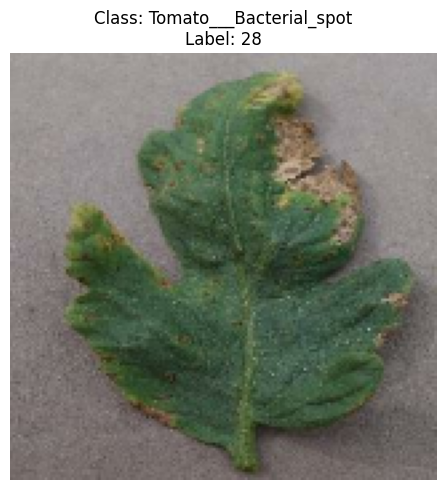


PASS: Image loading test completed successfully.


In [25]:
# ============================================================
# PHASE 4.5: TEST IMAGE LOADING FUNCTION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - IMAGE LOADING TEST")
print("=" * 60)

# Select one image from the training split
sample = train_data.iloc[0]

sample_path = sample["resolved_filepath"]
sample_label = int(sample["label"])
sample_class = sample["plantvillage_class"]

# Load and preprocess the image
image, label = load_and_preprocess_image(
    tf.constant(sample_path),
    tf.constant(sample_label)
)

# Display image properties
print(f"\nOriginal class : {sample_class}")
print(f"Numerical label: {label.numpy()}")
print(f"Image shape    : {image.shape}")
print(f"Image dtype    : {image.dtype}")
print(f"Minimum pixel  : {tf.reduce_min(image).numpy():.2f}")
print(f"Maximum pixel  : {tf.reduce_max(image).numpy():.2f}")

# Verify expected properties
assert image.shape == (160, 160, 3), (
    "Unexpected image dimensions!"
)

assert image.dtype == tf.float32, (
    "Unexpected image data type!"
)

assert 0 <= tf.reduce_min(image).numpy(), (
    "Pixel values below expected range!"
)

assert tf.reduce_max(image).numpy() <= 255, (
    "Pixel values above expected range!"
)

assert int(label.numpy()) == class_to_index[sample_class], (
    "Numerical label does not match class mapping!"
)

# Visualise the processed image
plt.figure(figsize=(5, 5))

plt.imshow(
    tf.cast(image, tf.uint8).numpy()
)

plt.title(
    f"Class: {sample_class}\n"
    f"Label: {label.numpy()}"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("\nPASS: Image loading test completed successfully.")
print("=" * 60)

In [26]:
# ============================================================
# PHASE 4.5: BUILD TENSORFLOW DATA PIPELINES
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - TF.DATA PIPELINE")
print("=" * 60)

AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(dataframe, training=False):
    """
    Create a TensorFlow dataset from the verified Phase 2
    image paths and numerical labels.
    """

    filepaths = dataframe["resolved_filepath"].astype(str).to_numpy()
    labels = dataframe["label"].astype("int32").to_numpy()

    # Create dataset from image paths and labels
    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    # Shuffle training records only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Decode and resize images
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    # Group images into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Prepare upcoming batches while the model is processing
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Create the three datasets
train_ds = create_dataset(train_data, training=True)
val_ds = create_dataset(val_data, training=False)
test_ds = create_dataset(test_data, training=False)

print("\nDataset pipelines created successfully.")

print(f"\nTraining batches   : {tf.data.experimental.cardinality(train_ds).numpy()}")
print(f"Validation batches : {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"Testing batches    : {tf.data.experimental.cardinality(test_ds).numpy()}")

print("\nTraining dataset specification:")
print(train_ds.element_spec)

print("\nPASS: TensorFlow data pipelines created.")
print("=" * 60)

AGROVISION FYP2 - TF.DATA PIPELINE

Dataset pipelines created successfully.

Training batches   : 1187
Validation batches : 255
Testing batches    : 255

Training dataset specification:
(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

PASS: TensorFlow data pipelines created.


AGROVISION FYP2 - TRAINING BATCH VERIFICATION

Batch image shape : (32, 160, 160, 3)
Batch label shape : (32,)
Image data type   : <dtype: 'float32'>
Label data type   : <dtype: 'int32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0


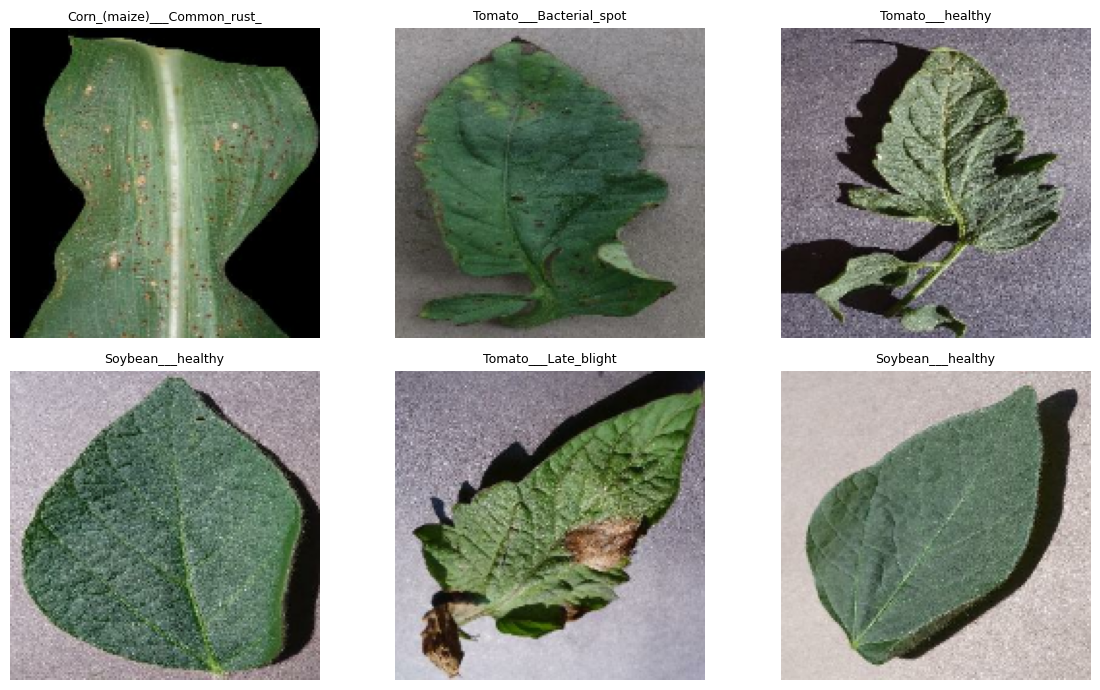


PASS: Training batch verification completed.


In [27]:
# ============================================================
# PHASE 4.5: VERIFY TRAINING BATCH
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - TRAINING BATCH VERIFICATION")
print("=" * 60)

# Retrieve one training batch
batch_images, batch_labels = next(iter(train_ds))

# Inspect batch properties
print("\nBatch image shape :", batch_images.shape)
print("Batch label shape :", batch_labels.shape)
print("Image data type   :", batch_images.dtype)
print("Label data type   :", batch_labels.dtype)

print(
    "Minimum pixel value:",
    float(tf.reduce_min(batch_images).numpy())
)

print(
    "Maximum pixel value:",
    float(tf.reduce_max(batch_images).numpy())
)

# Verify dimensions and labels
assert batch_images.shape == (
    BATCH_SIZE, 160, 160, 3
), "Unexpected training batch shape!"

assert batch_labels.shape == (
    BATCH_SIZE,
), "Unexpected label batch shape!"

assert tf.reduce_all(
    (batch_labels >= 0) & (batch_labels < NUM_CLASSES)
).numpy(), "Invalid labels detected!"

# Reverse class mapping
index_to_class = {
    int(index): class_name
    for class_name, index in class_to_index.items()
}

# Visualise six training images
plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    image = batch_images[i].numpy()
    label = int(batch_labels[i].numpy())

    plt.imshow(
        np.clip(image, 0, 255).astype(np.uint8)
    )

    plt.title(
        index_to_class[label],
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nPASS: Training batch verification completed.")
print("=" * 60)

In [28]:
# ============================================================
# PHASE 4.6: DATA AUGMENTATION CONFIGURATION
# ============================================================

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED
        ),

        layers.RandomRotation(
            factor=0.05,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=0.1,
            width_factor=0.1,
            fill_mode="reflect",
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.1,
            seed=SEED
        )
    ],
    name="agrovision_augmentation"
)

print("=" * 60)
print("AGROVISION FYP2 - DATA AUGMENTATION")
print("=" * 60)

print("Random flip     : Horizontal and vertical")
print("Rotation factor : 0.05")
print("Zoom factor     : 0.1")
print("Contrast factor : 0.1")
print("Fill mode       : Reflect")
print("Random seed     :", SEED)

print("\nPASS: Data augmentation pipeline defined.")
print("=" * 60)

AGROVISION FYP2 - DATA AUGMENTATION
Random flip     : Horizontal and vertical
Rotation factor : 0.05
Zoom factor     : 0.1
Contrast factor : 0.1
Fill mode       : Reflect
Random seed     : 42

PASS: Data augmentation pipeline defined.


AGROVISION FYP2 - AUGMENTATION VISUALISATION


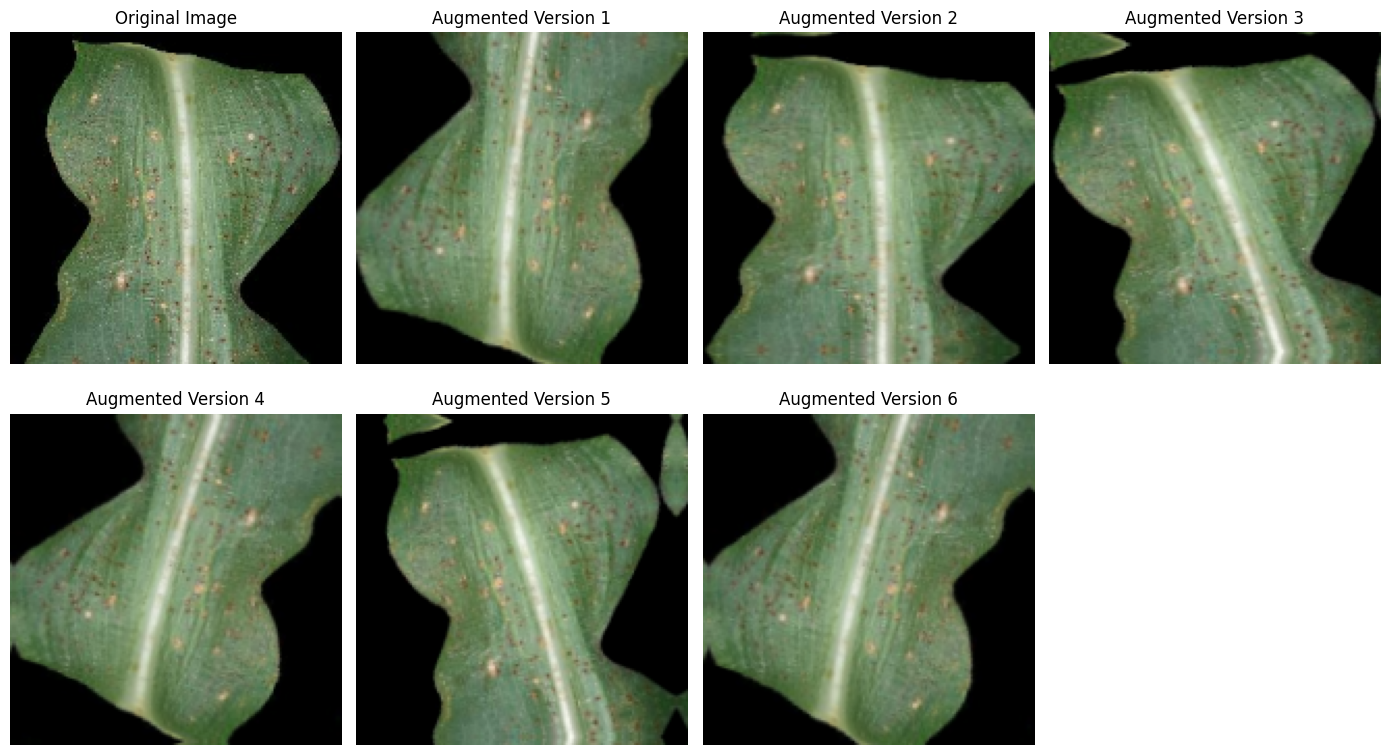


PASS: Augmentation visualisation completed.


In [29]:
# ============================================================
# PHASE 4.6: VISUALISE DATA AUGMENTATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - AUGMENTATION VISUALISATION")
print("=" * 60)

# Use the first image from our verified training batch
original_image = batch_images[0]

# Add batch dimension: (160, 160, 3) -> (1, 160, 160, 3)
image_input = tf.expand_dims(original_image, axis=0)

# Create visualisation
plt.figure(figsize=(14, 8))

# Original image
plt.subplot(2, 4, 1)
plt.imshow(
    np.clip(original_image.numpy(), 0, 255).astype(np.uint8)
)
plt.title("Original Image")
plt.axis("off")

# Generate six augmented versions
for i in range(6):

    augmented_image = data_augmentation(
        image_input,
        training=True
    )[0]

    plt.subplot(2, 4, i + 2)

    plt.imshow(
        np.clip(
            augmented_image.numpy(),
            0,
            255
        ).astype(np.uint8)
    )

    plt.title(f"Augmented Version {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nPASS: Augmentation visualisation completed.")
print("=" * 60)

In [30]:
# ============================================================
# PHASE 4.6: FULL DATASET DECODING VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - FULL DATASET DECODING CHECK")
print("=" * 60)

for split_name, dataset, expected_count in [
    ("Training", train_ds, 37978),
    ("Validation", val_ds, 8155),
    ("Testing", test_ds, 8151)
]:

    image_count = 0

    for images, labels in dataset:
        tf.debugging.assert_all_finite(
            images,
            "Non-finite pixel values detected."
        )

        tf.debugging.assert_greater_equal(images, 0.0)
        tf.debugging.assert_less_equal(images, 255.0)

        image_count += int(tf.shape(images)[0].numpy())

    print(
        f"{split_name}: "
        f"{image_count:,}/{expected_count:,} images decoded"
    )

    assert image_count == expected_count, (
        f"{split_name} image count mismatch!"
    )

print("\nPASS: All dataset images decoded successfully.")
print("=" * 60)

AGROVISION FYP2 - FULL DATASET DECODING CHECK
Training: 37,978/37,978 images decoded
Validation: 8,155/8,155 images decoded
Testing: 8,151/8,151 images decoded

PASS: All dataset images decoded successfully.


In [31]:
# ============================================================
# PHASE 4.7: REUSABLE AUGMENTATION FUNCTION
# ============================================================

def create_augmentation(seed=SEED):
    """
    Create a fresh augmentation pipeline using
    the Phase 2 augmentation configuration.
    """

    return tf.keras.Sequential(
        [
            tf.keras.layers.RandomFlip(
                mode="horizontal_and_vertical",
                seed=seed
            ),

            tf.keras.layers.RandomRotation(
                factor=0.05,
                fill_mode="reflect",
                seed=seed
            ),

            tf.keras.layers.RandomZoom(
                height_factor=0.1,
                width_factor=0.1,
                fill_mode="reflect",
                seed=seed
            ),

            tf.keras.layers.RandomContrast(
                factor=0.1,
                seed=seed
            )
        ],
        name="agrovision_augmentation"
    )


print("=" * 60)
print("AGROVISION FYP2 - REUSABLE AUGMENTATION")
print("=" * 60)

augmentation_test = create_augmentation()

print("Augmentation factory created successfully.")
print(f"Number of augmentation layers: {len(augmentation_test.layers)}")

print("\nPASS: Reusable augmentation function defined.")
print("=" * 60)

AGROVISION FYP2 - REUSABLE AUGMENTATION
Augmentation factory created successfully.
Number of augmentation layers: 4

PASS: Reusable augmentation function defined.


In [32]:
# ============================================================
# PHASE 4.7: SHARED TRANSFER LEARNING MODEL FACTORY
# ============================================================

from tensorflow.keras import Model, Input, layers
from tensorflow.keras.applications import (
    ResNet50,
    MobileNetV2,
    EfficientNetB0
)

from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)


def build_transfer_model(model_name):
    """
    Build an ImageNet-pretrained transfer learning model
    for AgroVision's 38-class PlantVillage classification.

    Stage 1: Frozen pretrained backbone.
    """

    # Input layer
    inputs = Input(
        shape=(*IMAGE_SIZE, IMAGE_CHANNELS),
        name="input_image"
    )

    # Training-only augmentation
    x = create_augmentation(seed=SEED)(inputs)

    # Select architecture and preprocessing
    if model_name == "ResNet50":

        x = layers.Lambda(
            resnet_preprocess,
            name="resnet_preprocessing"
        )(x)

        backbone = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    elif model_name == "MobileNetV2":

        x = layers.Lambda(
            mobilenet_preprocess,
            name="mobilenet_preprocessing"
        )(x)

        backbone = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    elif model_name == "EfficientNetB0":

        # EfficientNetB0 includes its own input rescaling
        # in the current TensorFlow/Keras implementation.
        backbone = EfficientNetB0(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    else:
        raise ValueError(
            f"Unsupported architecture: {model_name}"
        )

    # Stage 1: Freeze the pretrained backbone
    backbone.trainable = False

    # Apply the pretrained feature extractor
    # training=False keeps BatchNormalization layers
    # in inference mode.
    x = backbone(x, training=False)

    # Shared classification head
    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dropout(
        rate=DROPOUT_RATE,
        name="classifier_dropout"
    )(x)

    outputs = layers.Dense(
        units=NUM_CLASSES,
        activation="softmax",
        name="disease_predictions"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name=f"AgroVision_{model_name}"
    )

    return model, backbone


print("=" * 60)
print("AGROVISION FYP2 - MODEL FACTORY")
print("=" * 60)

print("Supported architectures:")
for name in MODEL_NAMES:
    print(f"  - {name}")

print("\nPretrained weights : ImageNet")
print("Initial backbone   : Frozen")
print(f"Classification head: GAP + Dropout({DROPOUT_RATE}) + Softmax")
print(f"Output classes     : {NUM_CLASSES}")

print("\nPASS: Shared model-building function defined.")
print("=" * 60)

AGROVISION FYP2 - MODEL FACTORY
Supported architectures:
  - ResNet50
  - MobileNetV2
  - EfficientNetB0

Pretrained weights : ImageNet
Initial backbone   : Frozen
Classification head: GAP + Dropout(0.3) + Softmax
Output classes     : 38

PASS: Shared model-building function defined.


RESNET50

In [33]:
# ============================================================
# PHASE 4.7: BUILD AND INSPECT RESNET50
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 MODEL CONSTRUCTION")
print("=" * 60)

# Build ResNet50 using the shared model factory
resnet50_model, resnet50_backbone = build_transfer_model(
    "ResNet50"
)

# Display model summary
resnet50_model.summary()

# Calculate parameter counts
total_params = resnet50_model.count_params()

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_model.trainable_weights
)

non_trainable_params = total_params - trainable_params

print("\n" + "=" * 60)
print("RESNET50 PARAMETER SUMMARY")
print("=" * 60)

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

print("\nBackbone trainable:", resnet50_backbone.trainable)
print("Model input shape :", resnet50_model.input_shape)
print("Model output shape:", resnet50_model.output_shape)

# Verify expected model configuration
assert resnet50_backbone.trainable is False, (
    "ResNet50 backbone should be frozen."
)

assert resnet50_model.input_shape == (
    None, 160, 160, 3
), "Unexpected model input shape!"

assert resnet50_model.output_shape == (
    None, NUM_CLASSES
), "Unexpected model output shape!"

assert trainable_params > 0, (
    "Classification head has no trainable parameters!"
)

print("\nPASS: ResNet50 constructed and verified successfully.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 MODEL CONSTRUCTION
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "AgroVision_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ agrovision_augmentation         │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_predictions (Dense)     │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)


RESNET50 PARAMETER SUMMARY
Total parameters       : 23,665,574
Trainable parameters   : 77,862
Non-trainable parameters: 23,587,712

Backbone trainable: False
Model input shape : (None, 160, 160, 3)
Model output shape: (None, 38)

PASS: ResNet50 constructed and verified successfully.


In [34]:
# ============================================================
# PHASE 4.7: RESNET50 FORWARD PASS VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 FORWARD PASS")
print("=" * 60)

# Select four images from our verified training batch
sample_images = batch_images[:4]

# Run a forward pass without training
predictions = resnet50_model(
    sample_images,
    training=False
)

print("\nInput shape      :", sample_images.shape)
print("Prediction shape :", predictions.shape)
print("Prediction dtype :", predictions.dtype)

# Check probability distributions
probability_sums = tf.reduce_sum(predictions, axis=1)

print("\nProbability sums:")
print(probability_sums.numpy())

# Check predicted class indices
predicted_classes = tf.argmax(
    predictions,
    axis=1
).numpy()

print("\nPredicted class indices:")
print(predicted_classes)

# Verify output shape
assert predictions.shape == (4, NUM_CLASSES), (
    "Unexpected prediction shape!"
)

# Verify finite predictions
tf.debugging.assert_all_finite(
    predictions,
    "Invalid prediction values detected."
)

# Verify Softmax probabilities
np.testing.assert_allclose(
    probability_sums.numpy(),
    np.ones(4),
    rtol=1e-5,
    atol=1e-5
)

print("\nPASS: ResNet50 forward pass verified successfully.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 FORWARD PASS

Input shape      : (4, 160, 160, 3)
Prediction shape : (4, 38)
Prediction dtype : <dtype: 'float32'>

Probability sums:
[1.         0.99999994 0.99999994 1.        ]

Predicted class indices:
[14 20 27 36]

PASS: ResNet50 forward pass verified successfully.


In [35]:
# ============================================================
# PHASE 4.8: COMPILE RESNET50 - INITIAL TRAINING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 COMPILATION")
print("=" * 60)

# Create a fresh Adam optimiser
resnet50_optimizer = tf.keras.optimizers.Adam(
    learning_rate=INITIAL_LEARNING_RATE
)

# Compile the model
resnet50_model.compile(
    optimizer=resnet50_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\nModel             : ResNet50")
print("Training stage    : Initial feature extraction")
print("Optimiser         : Adam")
print(f"Learning rate     : {INITIAL_LEARNING_RATE}")
print("Loss function     : SparseCategoricalCrossentropy")
print("Evaluation metric : Accuracy")
print("Backbone trainable:", resnet50_backbone.trainable)

# Verify configuration
assert resnet50_backbone.trainable is False, (
    "ResNet50 backbone must remain frozen during Stage 1."
)

assert np.isclose(
    float(resnet50_model.optimizer.learning_rate.numpy()),
    INITIAL_LEARNING_RATE
), "Incorrect initial learning rate!"

print("\nPASS: ResNet50 compiled successfully.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 COMPILATION

Model             : ResNet50
Training stage    : Initial feature extraction
Optimiser         : Adam
Learning rate     : 0.001
Loss function     : SparseCategoricalCrossentropy
Evaluation metric : Accuracy
Backbone trainable: False

PASS: ResNet50 compiled successfully.


In [36]:
# ============================================================
# PHASE 4.8: RESNET50 STAGE 1 CHECKPOINTS AND CALLBACKS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 TRAINING CALLBACKS")
print("=" * 60)

# Persistent experiment directories
EXPERIMENT_DIR = PROJECT_DIR / "model_experiments"

RESNET50_DIR = EXPERIMENT_DIR / "ResNet50"
RESNET50_STAGE1_DIR = RESNET50_DIR / "stage1"

RESNET50_STAGE1_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# File paths
resnet50_stage1_checkpoint = (
    RESNET50_STAGE1_DIR / "best_model.keras"
)

resnet50_stage1_history_path = (
    RESNET50_STAGE1_DIR / "training_history.csv"
)

resnet50_stage1_log_path = (
    RESNET50_STAGE1_DIR / "epoch_log.csv"
)

# Training callbacks
resnet50_stage1_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(resnet50_stage1_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(resnet50_stage1_log_path),
        append=False
    )
]

print(f"\nExperiment directory : {RESNET50_STAGE1_DIR}")
print(f"Best model checkpoint: {resnet50_stage1_checkpoint}")
print(f"Training history     : {resnet50_stage1_history_path}")
print(f"Epoch log            : {resnet50_stage1_log_path}")

print("\nCallback configuration:")
for callback in resnet50_stage1_callbacks:
    print(f"  - {callback.__class__.__name__}")

print(f"\nMonitoring metric       : {MONITOR_METRIC}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience   : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor     : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate   : {MIN_LEARNING_RATE}")

# Verify configuration
assert RESNET50_STAGE1_DIR.exists()
assert len(resnet50_stage1_callbacks) == 4

print("\nPASS: ResNet50 Stage 1 callbacks configured.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 TRAINING CALLBACKS

Experiment directory : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1
Best model checkpoint: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras
Training history     : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/training_history.csv
Epoch log            : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/epoch_log.csv

Callback configuration:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Monitoring metric       : val_loss
Early stopping patience : 7
LR reduction patience   : 3
LR reduction factor     : 0.5
Minimum learning rate   : 1e-07

PASS: ResNet50 Stage 1 callbacks configured.


In [37]:
# ============================================================
# PHASE 4.8: PRE-TRAINING CLASS WEIGHT VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - CLASS WEIGHT VERIFICATION")
print("=" * 60)

# 1. Verify class weight structure
assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(range(NUM_CLASSES))

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

# 2. Verify training label coverage
training_labels = set(
    train_data["label"].unique()
)

assert training_labels == set(range(NUM_CLASSES))

# 3. Convert class weights into a TensorFlow lookup tensor
class_weight_tensor = tf.constant(
    [class_weights[i] for i in range(NUM_CLASSES)],
    dtype=tf.float32
)

# 4. Test sample-weight mapping on a training batch
sample_labels = tf.cast(batch_labels, tf.int32)

sample_weights = tf.gather(
    class_weight_tensor,
    sample_labels
)

assert sample_weights.shape == sample_labels.shape

tf.debugging.assert_all_finite(
    sample_weights,
    "Invalid sample weights detected."
)

tf.debugging.assert_positive(sample_weights)

# 5. Display verification results
print(f"\nNumber of classes       : {NUM_CLASSES}")
print(f"Training images         : {len(train_data):,}")
print(f"Class weights available : {len(class_weights)}")

print(f"\nMinimum class weight    : {min(class_weights.values()):.6f}")
print(f"Maximum class weight    : {max(class_weights.values()):.6f}")

print("\nSample labels:")
print(sample_labels[:10].numpy())

print("\nCorresponding sample weights:")
print(sample_weights[:10].numpy())

print("\nPASS: Class weights and sample-weight mapping verified.")
print("=" * 60)

AGROVISION FYP2 - CLASS WEIGHT VERIFICATION

Number of classes       : 38
Training images         : 37,978
Class weights available : 38

Minimum class weight    : 0.259253
Maximum class weight    : 9.428500

Sample labels:
[ 8 28 37 24 30 24 34  3  6 15]

Corresponding sample weights:
[1.1983466  0.67120284 0.90119123 0.2805786  0.7514444  0.2805786
 1.0177404  0.87209517 1.6712726  0.2592532 ]

PASS: Class weights and sample-weight mapping verified.


In [38]:
# ============================================================
# PHASE 4.8: SERIALISABLE MODEL PREPROCESSING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - SERIALISABLE PREPROCESSING")
print("=" * 60)


def create_model_preprocessing(model_name):
    """
    Return a preprocessing layer compatible with
    the selected ImageNet-pretrained architecture.

    Input images must be RGB float32 in [0, 255].
    """

    if model_name == "ResNet50":

        # Convert RGB to BGR using channel reversal.
        # A fixed 1x1 convolution also subtracts
        # the ImageNet BGR channel means.
        preprocessing = tf.keras.layers.Conv2D(
            filters=3,
            kernel_size=1,
            use_bias=True,
            trainable=False,
            name="resnet_preprocessing"
        )

        preprocessing.build((None, *IMAGE_SIZE, 3))

        kernel = np.zeros((1, 1, 3, 3), dtype=np.float32)

        # Output B, G, R from input R, G, B
        kernel[0, 0, 2, 0] = 1.0
        kernel[0, 0, 1, 1] = 1.0
        kernel[0, 0, 0, 2] = 1.0

        bias = np.array(
            [-103.939, -116.779, -123.68],
            dtype=np.float32
        )

        preprocessing.set_weights([kernel, bias])

        return preprocessing

    elif model_name == "MobileNetV2":

        return tf.keras.Sequential(
            [
                tf.keras.layers.Rescaling(
                    scale=1.0 / 127.5,
                    offset=-1.0
                )
            ],
            name="mobilenet_preprocessing"
        )

    elif model_name == "EfficientNetB0":

        # EfficientNetB0 includes its own preprocessing.
        return tf.keras.layers.Activation(
            "linear",
            name="efficientnet_input_passthrough"
        )

    else:
        raise ValueError(
            f"Unsupported architecture: {model_name}"
        )


# Verify ResNet50 preprocessing against Keras reference
test_input = tf.random.uniform(
    shape=(2, *IMAGE_SIZE, 3),
    minval=0,
    maxval=255,
    dtype=tf.float32,
    seed=SEED
)

reference_output = resnet_preprocess(
    tf.identity(test_input)
)

custom_output = create_model_preprocessing(
    "ResNet50"
)(test_input)

max_difference = tf.reduce_max(
    tf.abs(reference_output - custom_output)
).numpy()

print(f"\nResNet50 maximum preprocessing difference: {max_difference:.8f}")

np.testing.assert_allclose(
    custom_output.numpy(),
    reference_output.numpy(),
    rtol=1e-5,
    atol=1e-4
)

# Verify MobileNetV2 preprocessing
mobilenet_reference = mobilenet_preprocess(
    tf.identity(test_input)
)

mobilenet_custom = create_model_preprocessing(
    "MobileNetV2"
)(test_input)

np.testing.assert_allclose(
    mobilenet_custom.numpy(),
    mobilenet_reference.numpy(),
    rtol=1e-5,
    atol=1e-5
)

print("ResNet50 preprocessing : Verified")
print("MobileNetV2 preprocessing: Verified")
print("EfficientNetB0 preprocessing: Built into backbone")

print("\nPASS: Serialisable preprocessing layers verified.")
print("=" * 60)

AGROVISION FYP2 - SERIALISABLE PREPROCESSING

ResNet50 maximum preprocessing difference: 0.00000000
ResNet50 preprocessing : Verified
MobileNetV2 preprocessing: Verified
EfficientNetB0 preprocessing: Built into backbone

PASS: Serialisable preprocessing layers verified.


In [39]:
# ============================================================
# PHASE 4.8: UPDATED TRANSFER LEARNING MODEL FACTORY
# ============================================================

def build_transfer_model(model_name):
    """
    Build an ImageNet-pretrained AgroVision model
    using serialisable preprocessing layers.

    Stage 1: Frozen pretrained backbone.
    """

    inputs = tf.keras.Input(
        shape=(*IMAGE_SIZE, IMAGE_CHANNELS),
        name="input_image"
    )

    # Training-only augmentation
    x = create_augmentation(seed=SEED)(inputs)

    # Architecture-specific preprocessing
    x = create_model_preprocessing(model_name)(x)

    # Select pretrained architecture
    if model_name == "ResNet50":

        backbone = tf.keras.applications.ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    elif model_name == "MobileNetV2":

        backbone = tf.keras.applications.MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    elif model_name == "EfficientNetB0":

        backbone = tf.keras.applications.EfficientNetB0(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
        )

    else:
        raise ValueError(
            f"Unsupported architecture: {model_name}"
        )

    # Freeze pretrained backbone for Stage 1
    backbone.trainable = False

    # Keep backbone BatchNormalization statistics fixed
    x = backbone(x, training=False)

    # Shared classification head
    x = tf.keras.layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = tf.keras.layers.Dropout(
        rate=DROPOUT_RATE,
        name="classifier_dropout"
    )(x)

    outputs = tf.keras.layers.Dense(
        units=NUM_CLASSES,
        activation="softmax",
        name="disease_predictions"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"AgroVision_{model_name}"
    )

    return model, backbone


print("=" * 60)
print("AGROVISION FYP2 - UPDATED MODEL FACTORY")
print("=" * 60)

print("\nSupported architectures:")
for model_name in MODEL_NAMES:
    print(f"  - {model_name}")

print("\nPreprocessing:")
print("  ResNet50      : Fixed RGB-to-BGR transformation")
print("  MobileNetV2   : Rescaling to [-1, 1]")
print("  EfficientNetB0: Built-in preprocessing")

print("\nShared configuration:")
print(f"  Input shape   : {(*IMAGE_SIZE, IMAGE_CHANNELS)}")
print(f"  Output classes: {NUM_CLASSES}")
print(f"  Dropout rate  : {DROPOUT_RATE}")
print("  Backbone      : Initially frozen")

print("\nPASS: Updated model factory defined successfully.")
print("=" * 60)

AGROVISION FYP2 - UPDATED MODEL FACTORY

Supported architectures:
  - ResNet50
  - MobileNetV2
  - EfficientNetB0

Preprocessing:
  ResNet50      : Fixed RGB-to-BGR transformation
  MobileNetV2   : Rescaling to [-1, 1]
  EfficientNetB0: Built-in preprocessing

Shared configuration:
  Input shape   : (160, 160, 3)
  Output classes: 38
  Dropout rate  : 0.3
  Backbone      : Initially frozen

PASS: Updated model factory defined successfully.


In [40]:
# ============================================================
# PHASE 4.8: REBUILD RESNET50 WITH UPDATED PREPROCESSING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 REBUILD VERIFICATION")
print("=" * 60)

# Release references to the previous model
del resnet50_model
del resnet50_backbone
del resnet50_optimizer

# Clear previous Keras model state
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

# Build ResNet50 using the updated model factory
resnet50_model, resnet50_backbone = build_transfer_model(
    "ResNet50"
)

# Compile with the original Stage 1 configuration
resnet50_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Inspect the preprocessing layer
preprocessing_layer = resnet50_model.get_layer(
    "resnet_preprocessing"
)

# Calculate parameter counts
total_params = resnet50_model.count_params()

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_model.trainable_weights
)

non_trainable_params = total_params - trainable_params

print("\nModel configuration:")
print("Model name          :", resnet50_model.name)
print("Preprocessing layer :", type(preprocessing_layer).__name__)
print("Backbone frozen     :", not resnet50_backbone.trainable)
print("Input shape         :", resnet50_model.input_shape)
print("Output shape        :", resnet50_model.output_shape)

print("\nParameter summary:")
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

# Verify model configuration
assert isinstance(
    preprocessing_layer,
    tf.keras.layers.Conv2D
)

assert preprocessing_layer.trainable is False

assert resnet50_backbone.trainable is False

assert resnet50_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_model.output_shape == (
    None, NUM_CLASSES
)

assert trainable_params == 77862

# Test forward pass
test_predictions = resnet50_model(
    batch_images[:4],
    training=False
)

tf.debugging.assert_all_finite(
    test_predictions,
    "Non-finite prediction values detected."
)

np.testing.assert_allclose(
    tf.reduce_sum(test_predictions, axis=1).numpy(),
    np.ones(4),
    rtol=1e-5,
    atol=1e-5
)

print("\nForward pass: Verified")
print("Softmax probabilities: Verified")

print("\nPASS: Updated ResNet50 rebuilt successfully.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 REBUILD VERIFICATION

Model configuration:
Model name          : AgroVision_ResNet50
Preprocessing layer : Conv2D
Backbone frozen     : True
Input shape         : (None, 160, 160, 3)
Output shape        : (None, 38)

Parameter summary:
Total parameters       : 23,665,586
Trainable parameters   : 77,862
Non-trainable parameters: 23,587,724

Forward pass: Verified
Softmax probabilities: Verified

PASS: Updated ResNet50 rebuilt successfully.


In [42]:
# ============================================================
# PHASE 4.8: RESNET50 SAVE-AND-RELOAD VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 SAVE/RELOAD TEST")
print("=" * 60)

# Temporary checkpoint for verification
test_checkpoint_path = (
    RESNET50_STAGE1_DIR / "serialization_test.keras"
)

# Use the same images for both models
test_images = batch_images[:4]

# Predictions before saving
original_predictions = resnet50_model.predict(
    test_images,
    verbose=0
)

# Save the complete model
resnet50_model.save(
    str(test_checkpoint_path)
)

print("\nModel saved successfully.")
print(f"Checkpoint: {test_checkpoint_path}")

# Reload using standard Keras safe deserialisation
reloaded_model = tf.keras.models.load_model(
    str(test_checkpoint_path),
    safe_mode=True
)

print("\nModel reloaded successfully.")

# Predictions after reloading
reloaded_predictions = reloaded_model.predict(
    test_images,
    verbose=0
)

# Compare predictions
max_difference = np.max(
    np.abs(
        original_predictions - reloaded_predictions
    )
)

print(f"\nMaximum prediction difference: {max_difference:.10f}")

np.testing.assert_allclose(
    original_predictions,
    reloaded_predictions,
    rtol=1e-5,
    atol=1e-6
)

# Verify model structure
assert reloaded_model.input_shape == (
    None, 160, 160, 3
)

assert reloaded_model.output_shape == (
    None, NUM_CLASSES
)

assert isinstance(
    reloaded_model.get_layer("resnet_preprocessing"),
    tf.keras.layers.Conv2D
)

assert reloaded_model.get_layer("resnet50").trainable is False

assert reloaded_model.count_params() == (
    resnet50_model.count_params()
)

# Verify fixed preprocessing weights survived reloading
original_preprocessing_weights = (
    resnet50_model
    .get_layer("resnet_preprocessing")
    .get_weights()
)

reloaded_preprocessing_weights = (
    reloaded_model
    .get_layer("resnet_preprocessing")
    .get_weights()
)

for original, restored in zip(
    original_preprocessing_weights,
    reloaded_preprocessing_weights
):
    np.testing.assert_array_equal(original, restored)

print("\nArchitecture             : Verified")
print("Preprocessing weights    : Verified")
print("Frozen backbone          : Verified")
print("Prediction consistency   : Verified")

print("\nPASS: ResNet50 save-and-reload test successful.")
print("=" * 60)

# Release the temporary reloaded model
del reloaded_model

AGROVISION FYP2 - RESNET50 SAVE/RELOAD TEST

Model saved successfully.
Checkpoint: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/serialization_test.keras


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



Model reloaded successfully.

Maximum prediction difference: 0.0000000000

Architecture             : Verified
Preprocessing weights    : Verified
Frozen backbone          : Verified
Prediction consistency   : Verified

PASS: ResNet50 save-and-reload test successful.


In [43]:
# ============================================================
# PHASE 4.8: FINAL RESNET50 TRAINING READINESS CHECK
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 TRAINING READINESS")
print("=" * 60)

# 1. Dataset sizes
assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(test_data) == 8151

# 2. Model configuration
assert resnet50_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_model.output_shape == (
    None, NUM_CLASSES
)

assert resnet50_backbone.trainable is False

# 3. Training configuration
assert INITIAL_EPOCHS == 50

assert np.isclose(
    float(resnet50_model.optimizer.learning_rate.numpy()),
    INITIAL_LEARNING_RATE
)

# 4. Class weights
assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

# 5. Checkpoint configuration
assert RESNET50_STAGE1_DIR.exists()

assert len(resnet50_stage1_callbacks) == 4

# 6. Check whether previous training outputs exist
existing_outputs = [
    path for path in [
        resnet50_stage1_checkpoint,
        resnet50_stage1_log_path,
        resnet50_stage1_history_path
    ]
    if path.exists()
]

print("\nDataset configuration:")
print(f"  Training images   : {len(train_data):,}")
print(f"  Validation images : {len(val_data):,}")
print(f"  Test images       : {len(test_data):,}")

print("\nModel configuration:")
print(f"  Architecture      : {resnet50_model.name}")
print(f"  Input size        : {IMAGE_SIZE}")
print(f"  Output classes    : {NUM_CLASSES}")
print(f"  Backbone frozen   : {not resnet50_backbone.trainable}")

print("\nTraining configuration:")
print(f"  Batch size        : {BATCH_SIZE}")
print(f"  Maximum epochs    : {INITIAL_EPOCHS}")
print(f"  Learning rate     : {INITIAL_LEARNING_RATE}")
print(f"  Class weights     : {len(class_weights)}")
print(f"  Callbacks         : {len(resnet50_stage1_callbacks)}")

print("\nExisting training outputs:")
if existing_outputs:
    for path in existing_outputs:
        print(f"  WARNING: {path.name} already exists")
else:
    print("  None detected")

print("\n" + "=" * 60)

if existing_outputs:
    print("WARNING: Existing training files require review.")
else:
    print("PASS: ResNet50 is ready for Stage 1 training.")

print("=" * 60)

AGROVISION FYP2 - RESNET50 TRAINING READINESS

Dataset configuration:
  Training images   : 37,978
  Validation images : 8,155
  Test images       : 8,151

Model configuration:
  Architecture      : AgroVision_ResNet50
  Input size        : (160, 160)
  Output classes    : 38
  Backbone frozen   : True

Training configuration:
  Batch size        : 32
  Maximum epochs    : 50
  Learning rate     : 0.001
  Class weights     : 38
  Callbacks         : 4

Existing training outputs:
  None detected

PASS: ResNet50 is ready for Stage 1 training.


TRAINING RESNET50, STAGE 1

In [44]:
# ============================================================
# PHASE 4.9: RESNET50 STAGE 1 - INITIAL TRAINING
# ============================================================

import time

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 1 TRAINING")
print("=" * 60)

# Prevent accidental overwriting of previous training outputs
training_outputs = [
    resnet50_stage1_checkpoint,
    resnet50_stage1_log_path,
    resnet50_stage1_history_path
]

assert not any(path.exists() for path in training_outputs), (
    "Existing Stage 1 training files detected. "
    "Review them before starting another run."
)

# Confirm the backbone is frozen
assert resnet50_backbone.trainable is False

print("\nTraining configuration:")
print(f"Architecture       : {resnet50_model.name}")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {INITIAL_EPOCHS}")
print(f"Initial LR         : {INITIAL_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {resnet50_stage1_checkpoint}")

print("\nStarting Stage 1 training...\n")

# Record training start time
resnet50_stage1_start = time.time()

# Train the classification head
resnet50_stage1_history = resnet50_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=resnet50_stage1_callbacks,
    verbose=1
)

# Record training duration
resnet50_stage1_duration = (
    time.time() - resnet50_stage1_start
)

# Save training history
resnet50_stage1_history_df = pd.DataFrame(
    resnet50_stage1_history.history
)

resnet50_stage1_history_df.to_csv(
    resnet50_stage1_history_path,
    index=False
)

print("\n" + "=" * 60)
print("RESNET50 STAGE 1 TRAINING COMPLETED")
print("=" * 60)

print(
    f"Epochs completed : "
    f"{len(resnet50_stage1_history.epoch)}"
)

print(
    f"Training duration: "
    f"{resnet50_stage1_duration / 60:.2f} minutes"
)

print(
    f"Best validation loss: "
    f"{min(resnet50_stage1_history.history['val_loss']):.6f}"
)

print(
    f"Best validation accuracy: "
    f"{max(resnet50_stage1_history.history['val_accuracy']):.6f}"
)

print(f"\nBest checkpoint: {resnet50_stage1_checkpoint}")
print(f"Training history: {resnet50_stage1_history_path}")

print("\nPASS: ResNet50 Stage 1 training completed.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE 1 TRAINING

Training configuration:
Architecture       : AgroVision_ResNet50
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 0.001
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras

Starting Stage 1 training...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7177 - loss: 1.1627
Epoch 1: val_loss improved from None to 0.34924, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 128s 101ms/step - accuracy: 0.8361 - loss: 0.6151 - val_accuracy: 0.8846 - val_loss: 0.3492 - learning_rate: 0.0010
Epoch 2/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9193 - lo

AGROVISION FYP2 - RESNET50 STAGE 1 VISUALISATION


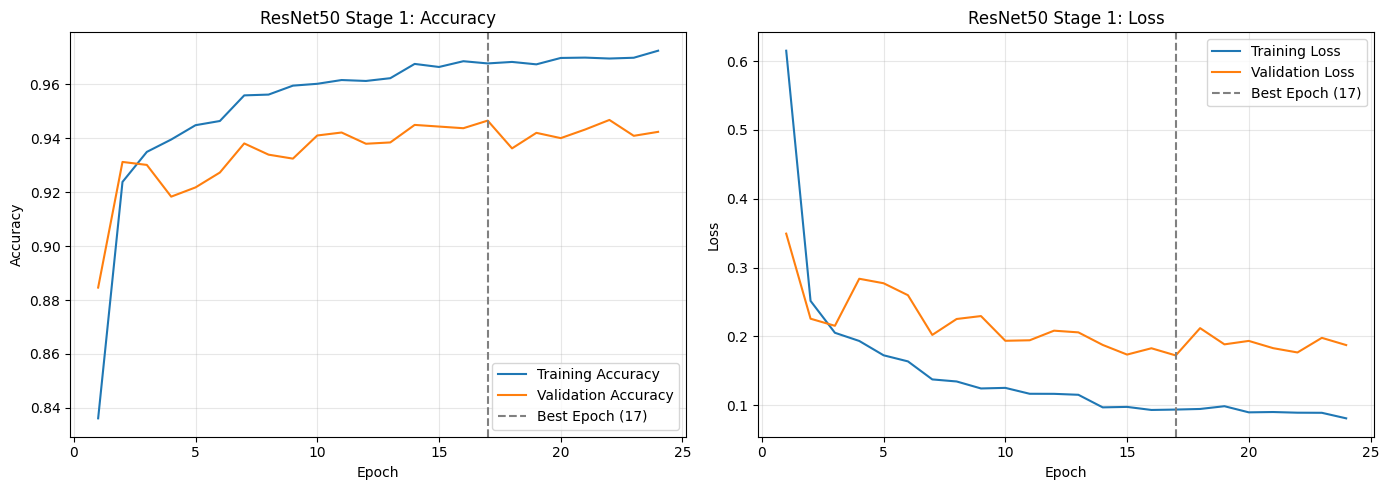


Best epoch: 17
Best validation loss: 0.172250
Best validation accuracy: 0.946781

Figure saved to: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/training_curves.png

PASS: Stage 1 training curves generated.


In [45]:
# ============================================================
# PHASE 4.10: RESNET50 STAGE 1 TRAINING VISUALISATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 1 VISUALISATION")
print("=" * 60)

# Load saved training history
history_df = pd.read_csv(
    resnet50_stage1_history_path
)

epochs = np.arange(1, len(history_df) + 1)

# Identify best epoch based on validation loss
best_epoch = int(
    history_df["val_loss"].idxmin() + 1
)

# Create training performance plots
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].axvline(
    best_epoch,
    color="grey",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[0].set_title("ResNet50 Stage 1: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss"
)

axes[1].axvline(
    best_epoch,
    color="grey",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[1].set_title("ResNet50 Stage 1: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save figure to Google Drive
figure_path = (
    RESNET50_STAGE1_DIR / "training_curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {history_df['val_loss'].min():.6f}")
print(f"Best validation accuracy: {history_df['val_accuracy'].max():.6f}")

print(f"\nFigure saved to: {figure_path}")

print("\nPASS: Stage 1 training curves generated.")
print("=" * 60)

In [46]:
# ============================================================
# PHASE 4.11: INSPECT RESNET50 FOR FINE-TUNING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 FINE-TUNING INSPECTION")
print("=" * 60)

# Confirm that our best Stage 1 checkpoint exists
assert resnet50_stage1_checkpoint.exists(), (
    "Best Stage 1 checkpoint not found."
)

# Inspect backbone structure
print("\nBackbone name:", resnet50_backbone.name)
print("Total backbone layers:", len(resnet50_backbone.layers))

# Identify layers belonging to the final convolutional stage
conv5_layers = [
    layer
    for layer in resnet50_backbone.layers
    if layer.name.startswith("conv5_")
]

print("\nFinal convolutional stage (conv5_x):")
print("Number of matching layers:", len(conv5_layers))

print("\nFirst 10 matching layers:")
for layer in conv5_layers[:10]:
    print(
        f"  {layer.name:<35} "
        f"{layer.__class__.__name__}"
    )

print("\nLast 10 matching layers:")
for layer in conv5_layers[-10:]:
    print(
        f"  {layer.name:<35} "
        f"{layer.__class__.__name__}"
    )

# Count BatchNormalization layers in conv5_x
conv5_bn_layers = [
    layer
    for layer in conv5_layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

print("\nBatchNormalization layers in conv5_x:",
      len(conv5_bn_layers))

# Verify final stage exists
assert len(conv5_layers) > 0, (
    "No conv5_x layers found in ResNet50."
)

print("\nStage 1 checkpoint: Verified")
print("Final convolutional stage: Identified")

print("\nPASS: ResNet50 fine-tuning inspection completed.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 FINE-TUNING INSPECTION

Backbone name: resnet50
Total backbone layers: 175

Final convolutional stage (conv5_x):
Number of matching layers: 32

First 10 matching layers:
  conv5_block1_1_conv                 Conv2D
  conv5_block1_1_bn                   BatchNormalization
  conv5_block1_1_relu                 Activation
  conv5_block1_2_conv                 Conv2D
  conv5_block1_2_bn                   BatchNormalization
  conv5_block1_2_relu                 Activation
  conv5_block1_0_conv                 Conv2D
  conv5_block1_3_conv                 Conv2D
  conv5_block1_0_bn                   BatchNormalization
  conv5_block1_3_bn                   BatchNormalization

Last 10 matching layers:
  conv5_block3_1_conv                 Conv2D
  conv5_block3_1_bn                   BatchNormalization
  conv5_block3_1_relu                 Activation
  conv5_block3_2_conv                 Conv2D
  conv5_block3_2_bn                   BatchNormalization
  conv5_block3_2_r

In [47]:
# ============================================================
# PHASE 4.11: LOAD BEST RESNET50 STAGE 1 CHECKPOINT
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - LOAD BEST STAGE 1 CHECKPOINT")
print("=" * 60)

# Confirm checkpoint exists
assert resnet50_stage1_checkpoint.exists(), (
    "Best Stage 1 checkpoint not found."
)

# Load the model without restoring the Stage 1 optimiser
# Stage 2 will use a fresh Adam optimiser.
resnet50_stage2_model = tf.keras.models.load_model(
    str(resnet50_stage1_checkpoint),
    compile=False,
    safe_mode=True
)

# Retrieve the pretrained backbone
resnet50_stage2_backbone = (
    resnet50_stage2_model.get_layer("resnet50")
)

# Verify architecture
assert resnet50_stage2_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_stage2_model.output_shape == (
    None, NUM_CLASSES
)

assert resnet50_stage2_backbone.trainable is False

# Verify preprocessing layer
assert isinstance(
    resnet50_stage2_model.get_layer("resnet_preprocessing"),
    tf.keras.layers.Conv2D
)

# Verify parameter count
assert resnet50_stage2_model.count_params() == 23665586

# Verify checkpoint predictions are valid
checkpoint_predictions = resnet50_stage2_model(
    batch_images[:4],
    training=False
)

tf.debugging.assert_all_finite(
    checkpoint_predictions,
    "Invalid predictions from Stage 1 checkpoint."
)

np.testing.assert_allclose(
    tf.reduce_sum(checkpoint_predictions, axis=1).numpy(),
    np.ones(4),
    rtol=1e-5,
    atol=1e-5
)

print("\nCheckpoint loaded successfully.")
print(f"Checkpoint path : {resnet50_stage1_checkpoint}")
print(f"Model name      : {resnet50_stage2_model.name}")
print(f"Total parameters: {resnet50_stage2_model.count_params():,}")
print(f"Backbone frozen : {not resnet50_stage2_backbone.trainable}")
print(f"Output shape    : {resnet50_stage2_model.output_shape}")

print("\nPASS: Best Stage 1 checkpoint loaded for fine-tuning.")
print("=" * 60)

AGROVISION FYP2 - LOAD BEST STAGE 1 CHECKPOINT

Checkpoint loaded successfully.
Checkpoint path : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras
Model name      : AgroVision_ResNet50
Total parameters: 23,665,586
Backbone frozen : True
Output shape    : (None, 38)

PASS: Best Stage 1 checkpoint loaded for fine-tuning.


In [48]:
# ============================================================
# PHASE 4.11: RESNET50 SELECTIVE FINE-TUNING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 SELECTIVE FINE-TUNING")
print("=" * 60)

# Enable fine-tuning at the backbone level
resnet50_stage2_backbone.trainable = True

# Configure individual backbone layers
for layer in resnet50_stage2_backbone.layers:

    # Keep BatchNormalization layers frozen
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

    # Unfreeze only the final convolutional stage
    elif layer.name.startswith("conv5_"):
        layer.trainable = True

    # Keep all earlier stages frozen
    else:
        layer.trainable = False


# Identify trainable backbone layers
trainable_backbone_layers = [
    layer
    for layer in resnet50_stage2_backbone.layers
    if layer.trainable
]

# Identify trainable layers in conv5_x
trainable_conv5_layers = [
    layer
    for layer in trainable_backbone_layers
    if layer.name.startswith("conv5_")
]

# Verify BatchNormalization remains frozen
bn_layers = [
    layer
    for layer in resnet50_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert all(
    not layer.trainable
    for layer in bn_layers
), "Some BatchNormalization layers are trainable!"

# Verify only conv5_x layers are unfrozen
assert all(
    layer.name.startswith("conv5_")
    for layer in trainable_backbone_layers
), "Unexpected backbone layers are trainable!"

# Verify preprocessing remains frozen
assert (
    resnet50_stage2_model
    .get_layer("resnet_preprocessing")
    .trainable is False
)

# Calculate model parameters
total_params = resnet50_stage2_model.count_params()

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_stage2_model.trainable_weights
)

non_trainable_params = total_params - trainable_params

print("\nFine-tuning configuration:")
print("Backbone trainable       :", resnet50_stage2_backbone.trainable)
print("Fine-tuning stage        : conv5_x")
print("Trainable backbone layers:", len(trainable_backbone_layers))
print("Trainable conv5_x layers :", len(trainable_conv5_layers))
print("Frozen BatchNorm layers  :", len(bn_layers))

print("\nParameter summary:")
print(f"Total parameters        : {total_params:,}")
print(f"Trainable parameters    : {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

print("\nFirst 10 trainable backbone layers:")
for layer in trainable_backbone_layers[:10]:
    print(f"  {layer.name}")

print("\nLast 10 trainable backbone layers:")
for layer in trainable_backbone_layers[-10:]:
    print(f"  {layer.name}")

assert trainable_params > 77862, (
    "Fine-tuning did not increase trainable parameters!"
)

assert trainable_params < total_params, (
    "All model parameters became trainable unexpectedly!"
)

print("\nPASS: ResNet50 selective fine-tuning configured.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 SELECTIVE FINE-TUNING

Fine-tuning configuration:
Backbone trainable       : True
Fine-tuning stage        : conv5_x
Trainable backbone layers: 22
Trainable conv5_x layers : 22
Frozen BatchNorm layers  : 53

Parameter summary:
Total parameters        : 23,665,586
Trainable parameters    : 15,031,334
Non-trainable parameters: 8,634,252

First 10 trainable backbone layers:
  conv5_block1_1_conv
  conv5_block1_1_relu
  conv5_block1_2_conv
  conv5_block1_2_relu
  conv5_block1_0_conv
  conv5_block1_3_conv
  conv5_block1_add
  conv5_block1_out
  conv5_block2_1_conv
  conv5_block2_1_relu

Last 10 trainable backbone layers:
  conv5_block2_3_conv
  conv5_block2_add
  conv5_block2_out
  conv5_block3_1_conv
  conv5_block3_1_relu
  conv5_block3_2_conv
  conv5_block3_2_relu
  conv5_block3_3_conv
  conv5_block3_add
  conv5_block3_out

PASS: ResNet50 selective fine-tuning configured.


In [49]:
# ============================================================
# PHASE 4.11: COMPILE RESNET50 FOR FINE-TUNING
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 2 COMPILATION")
print("=" * 60)

# Create a fresh optimiser for fine-tuning
resnet50_stage2_optimizer = tf.keras.optimizers.Adam(
    learning_rate=FINE_TUNING_LEARNING_RATE
)

# Compile the fine-tuning model
resnet50_stage2_model.compile(
    optimizer=resnet50_stage2_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Verify learning rate
actual_lr = float(
    resnet50_stage2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE
), "Incorrect fine-tuning learning rate!"

# Verify backbone configuration
assert resnet50_stage2_backbone.trainable is True

# Verify all Batch Normalisation layers remain frozen
assert all(
    not layer.trainable
    for layer in resnet50_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

# Verify trainable parameter count
stage2_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_stage2_model.trainable_weights
)

assert stage2_trainable_params == 15031334

print("\nModel configuration:")
print("Architecture       :", resnet50_stage2_model.name)
print("Training stage     : Stage 2 - Fine-Tuning")
print("Fine-tuning region : conv5_x")
print("Optimiser          : Adam")
print(f"Learning rate      : {actual_lr:.8f}")
print("Loss function      : SparseCategoricalCrossentropy")
print("Evaluation metric  : Accuracy")
print(f"Trainable params   : {stage2_trainable_params:,}")

print("\nPASS: ResNet50 Stage 2 compiled successfully.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE 2 COMPILATION

Model configuration:
Architecture       : AgroVision_ResNet50
Training stage     : Stage 2 - Fine-Tuning
Fine-tuning region : conv5_x
Optimiser          : Adam
Learning rate      : 0.00001000
Loss function      : SparseCategoricalCrossentropy
Evaluation metric  : Accuracy
Trainable params   : 15,031,334

PASS: ResNet50 Stage 2 compiled successfully.


In [50]:
# ============================================================
# PHASE 4.11: RESNET50 STAGE 2 CHECKPOINTS AND CALLBACKS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 2 CALLBACKS")
print("=" * 60)

# Create a separate directory for fine-tuning
RESNET50_STAGE2_DIR = RESNET50_DIR / "stage2"

RESNET50_STAGE2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Define Stage 2 output paths
resnet50_stage2_checkpoint = (
    RESNET50_STAGE2_DIR / "best_model.keras"
)

resnet50_stage2_history_path = (
    RESNET50_STAGE2_DIR / "training_history.csv"
)

resnet50_stage2_log_path = (
    RESNET50_STAGE2_DIR / "epoch_log.csv"
)

# Prevent accidental overwriting of existing results
stage2_output_paths = [
    resnet50_stage2_checkpoint,
    resnet50_stage2_history_path,
    resnet50_stage2_log_path
]

existing_stage2_outputs = [
    path for path in stage2_output_paths
    if path.exists()
]

assert not existing_stage2_outputs, (
    "Existing Stage 2 training files detected: "
    + ", ".join(str(p) for p in existing_stage2_outputs)
)

# Configure Stage 2 callbacks
resnet50_stage2_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(resnet50_stage2_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(resnet50_stage2_log_path),
        append=False
    )
]

# Display configuration
print("\nExperiment directory:")
print(RESNET50_STAGE2_DIR)

print("\nOutput files:")
print("Best checkpoint :", resnet50_stage2_checkpoint)
print("Training history:", resnet50_stage2_history_path)
print("Epoch log       :", resnet50_stage2_log_path)

print("\nCallback configuration:")
for callback in resnet50_stage2_callbacks:
    print(f"  - {callback.__class__.__name__}")

print("\nFine-tuning settings:")
print(f"Maximum epochs         : {FINE_TUNING_EPOCHS}")
print(f"Initial learning rate  : {FINE_TUNING_LEARNING_RATE}")
print(f"Monitoring metric      : {MONITOR_METRIC}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience  : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor    : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate  : {MIN_LEARNING_RATE}")

# Verify configuration
assert RESNET50_STAGE2_DIR.exists()
assert len(resnet50_stage2_callbacks) == 4

assert resnet50_stage2_checkpoint != (
    resnet50_stage1_checkpoint
)

print("\nPASS: ResNet50 Stage 2 callbacks configured.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE 2 CALLBACKS

Experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2

Output files:
Best checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras
Training history: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/training_history.csv
Epoch log       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/epoch_log.csv

Callback configuration:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Fine-tuning settings:
Maximum epochs         : 50
Initial learning rate  : 1e-05
Monitoring metric      : val_loss
Early stopping patience: 7
LR reduction patience  : 3
LR reduction factor    : 0.5
Minimum learning rate  : 1e-07

PASS: ResNet50 Stage 2 callbacks configured.


In [51]:
# ============================================================
# PHASE 4.11: FINAL RESNET50 STAGE 2 READINESS CHECK
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 2 READINESS")
print("=" * 60)

# 1. Verify Stage 1 checkpoint
assert resnet50_stage1_checkpoint.exists(), (
    "Stage 1 checkpoint is missing."
)

# 2. Verify dataset sizes
assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(test_data) == 8151

# 3. Verify model architecture
assert resnet50_stage2_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_stage2_model.output_shape == (
    None, NUM_CLASSES
)

# 4. Verify fine-tuning configuration
assert resnet50_stage2_backbone.trainable is True

assert all(
    layer.name.startswith("conv5_")
    for layer in resnet50_stage2_backbone.layers
    if layer.trainable
)

assert all(
    not layer.trainable
    for layer in resnet50_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

# 5. Verify trainable parameters
trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_stage2_model.trainable_weights
)

assert trainable_params == 15031334

# 6. Verify learning rate
actual_lr = float(
    resnet50_stage2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE
)

# 7. Verify class weights
assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

# 8. Verify callbacks and output paths
assert len(resnet50_stage2_callbacks) == 4

assert RESNET50_STAGE2_DIR.exists()

assert resnet50_stage2_checkpoint != (
    resnet50_stage1_checkpoint
)

# 9. Prevent accidental overwriting
existing_outputs = [
    path
    for path in [
        resnet50_stage2_checkpoint,
        resnet50_stage2_history_path,
        resnet50_stage2_log_path
    ]
    if path.exists()
]

# Display results
print("\nDataset configuration:")
print(f"  Training images   : {len(train_data):,}")
print(f"  Validation images : {len(val_data):,}")
print(f"  Test images       : {len(test_data):,}")

print("\nFine-tuning configuration:")
print(f"  Architecture      : {resnet50_stage2_model.name}")
print("  Fine-tuning region: conv5_x")
print(f"  Trainable params  : {trainable_params:,}")
print(f"  Learning rate     : {actual_lr:.8f}")
print(f"  Maximum epochs    : {FINE_TUNING_EPOCHS}")
print(f"  Batch size        : {BATCH_SIZE}")

print("\nExperiment configuration:")
print(f"  Class weights     : {len(class_weights)}")
print(f"  Callbacks         : {len(resnet50_stage2_callbacks)}")
print(f"  Stage 1 checkpoint: {resnet50_stage1_checkpoint}")
print(f"  Stage 2 checkpoint: {resnet50_stage2_checkpoint}")

print("\nExisting Stage 2 outputs:")

if existing_outputs:
    for path in existing_outputs:
        print(f"  WARNING: {path.name} already exists")
else:
    print("  None detected")

print("\n" + "=" * 60)

if existing_outputs:
    print("WARNING: Review existing training files before proceeding.")
else:
    print("PASS: ResNet50 is ready for Stage 2 fine-tuning.")

print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE 2 READINESS

Dataset configuration:
  Training images   : 37,978
  Validation images : 8,155
  Test images       : 8,151

Fine-tuning configuration:
  Architecture      : AgroVision_ResNet50
  Fine-tuning region: conv5_x
  Trainable params  : 15,031,334
  Learning rate     : 0.00001000
  Maximum epochs    : 50
  Batch size        : 32

Experiment configuration:
  Class weights     : 38
  Callbacks         : 4
  Stage 1 checkpoint: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage1/best_model.keras
  Stage 2 checkpoint: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras

Existing Stage 2 outputs:
  None detected

PASS: ResNet50 is ready for Stage 2 fine-tuning.


RESNET50 STAGE 2 FINE TUNING

In [52]:
# ============================================================
# PHASE 4.12: RESNET50 STAGE 2 - FINE-TUNING
# ============================================================

import time

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 2 FINE-TUNING")
print("=" * 60)

# Prevent accidental overwriting
stage2_training_outputs = [
    resnet50_stage2_checkpoint,
    resnet50_stage2_log_path,
    resnet50_stage2_history_path
]

assert not any(
    path.exists() for path in stage2_training_outputs
), (
    "Existing Stage 2 training files detected. "
    "Review them before starting another run."
)

# Confirm fine-tuning configuration
assert resnet50_stage2_backbone.trainable is True

assert np.isclose(
    float(resnet50_stage2_model.optimizer.learning_rate.numpy()),
    FINE_TUNING_LEARNING_RATE
)

print("\nTraining configuration:")
print(f"Architecture       : {resnet50_stage2_model.name}")
print("Training stage     : Stage 2 - Fine-Tuning")
print("Fine-tuning region : conv5_x")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {FINE_TUNING_EPOCHS}")
print(f"Initial LR         : {FINE_TUNING_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {resnet50_stage2_checkpoint}")

print("\nStarting Stage 2 fine-tuning...\n")

# Record start time
resnet50_stage2_start = time.time()

# Fine-tune the selected backbone layers
resnet50_stage2_history = resnet50_stage2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNING_EPOCHS,
    class_weight=class_weights,
    callbacks=resnet50_stage2_callbacks,
    verbose=1
)

# Calculate training duration
resnet50_stage2_duration = (
    time.time() - resnet50_stage2_start
)

# Save training history
resnet50_stage2_history_df = pd.DataFrame(
    resnet50_stage2_history.history
)

resnet50_stage2_history_df.to_csv(
    resnet50_stage2_history_path,
    index=False
)

# Identify the best epoch using validation loss
best_epoch_index = int(
    np.argmin(
        resnet50_stage2_history.history["val_loss"]
    )
)

best_epoch = best_epoch_index + 1

best_val_loss = (
    resnet50_stage2_history.history["val_loss"][best_epoch_index]
)

best_epoch_val_accuracy = (
    resnet50_stage2_history.history["val_accuracy"][best_epoch_index]
)

highest_val_accuracy = max(
    resnet50_stage2_history.history["val_accuracy"]
)

print("\n" + "=" * 60)
print("RESNET50 STAGE 2 FINE-TUNING COMPLETED")
print("=" * 60)

print(
    f"Epochs completed       : "
    f"{len(resnet50_stage2_history.epoch)}"
)

print(
    f"Training duration      : "
    f"{resnet50_stage2_duration / 60:.2f} minutes"
)

print(f"Best checkpoint epoch  : {best_epoch}")
print(f"Best validation loss   : {best_val_loss:.6f}")

print(
    f"Accuracy at best epoch : "
    f"{best_epoch_val_accuracy:.6f}"
)

print(
    f"Highest val accuracy   : "
    f"{highest_val_accuracy:.6f}"
)

print(f"\nBest checkpoint: {resnet50_stage2_checkpoint}")
print(f"Training history: {resnet50_stage2_history_path}")

assert resnet50_stage2_checkpoint.exists(), (
    "Stage 2 checkpoint was not saved."
)

print("\nPASS: ResNet50 Stage 2 fine-tuning completed.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE 2 FINE-TUNING

Training configuration:
Architecture       : AgroVision_ResNet50
Training stage     : Stage 2 - Fine-Tuning
Fine-tuning region : conv5_x
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 1e-05
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras

Starting Stage 2 fine-tuning...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.9699 - loss: 0.0919
Epoch 1: val_loss improved from None to 0.18083, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 167s 134ms/step - accuracy: 0.9707 - loss: 0.0865 - val_accuracy: 0.9430 - val_loss: 0.1808 - learning_rate: 1.0000

AGROVISION FYP2 - RESNET50 STAGE 2 VISUALISATION


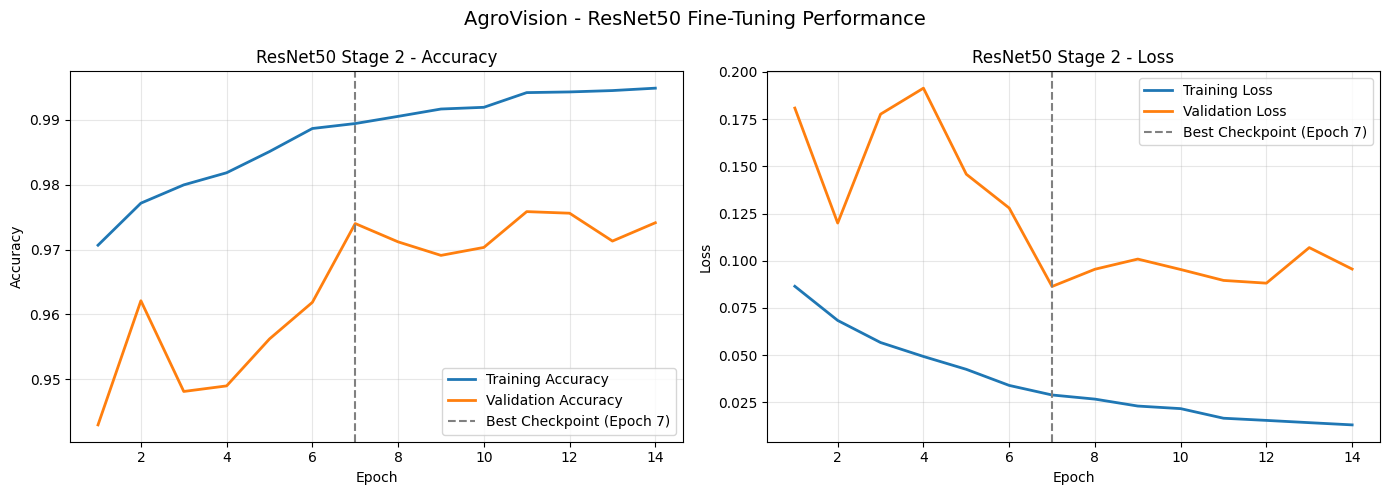


Training visualisation:
Epochs completed : 14
Best epoch       : 7
Best val loss    : 0.086392
Accuracy at best : 0.974004

Figure saved to: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/training_curves.png

PASS: Stage 2 training curves generated.


In [53]:
# ============================================================
# PHASE 4.12: RESNET50 STAGE 2 TRAINING VISUALISATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE 2 VISUALISATION")
print("=" * 60)

# Load saved training history
history_df = pd.read_csv(
    resnet50_stage2_history_path
)

required_columns = [
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
]

assert all(
    col in history_df.columns
    for col in required_columns
), "Required training metrics are missing."

# Prepare epoch numbers
epochs = np.arange(1, len(history_df) + 1)

# Identify selected checkpoint epoch
best_epoch = int(
    history_df["val_loss"].idxmin() + 1
)

# Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# Plot 1: Training and validation accuracy
# ------------------------------------------------------------

axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    x=best_epoch,
    linestyle="--",
    color="grey",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[0].set_title(
    "ResNet50 Stage 2 - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------------------
# Plot 2: Training and validation loss
# ------------------------------------------------------------

axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    x=best_epoch,
    linestyle="--",
    color="grey",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[1].set_title(
    "ResNet50 Stage 2 - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "AgroVision - ResNet50 Fine-Tuning Performance",
    fontsize=14
)

plt.tight_layout()

# Save figure
resnet50_stage2_curves_path = (
    RESNET50_STAGE2_DIR / "training_curves.png"
)

plt.savefig(
    resnet50_stage2_curves_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display summary
print("\nTraining visualisation:")
print(f"Epochs completed : {len(history_df)}")
print(f"Best epoch       : {best_epoch}")
print(
    f"Best val loss    : "
    f"{history_df['val_loss'].min():.6f}"
)
print(
    f"Accuracy at best : "
    f"{history_df.loc[best_epoch - 1, 'val_accuracy']:.6f}"
)

assert resnet50_stage2_curves_path.exists()

print(f"\nFigure saved to: {resnet50_stage2_curves_path}")
print("\nPASS: Stage 2 training curves generated.")
print("=" * 60)

In [55]:
# ============================================================
# PHASE 4.12: VERIFY RESNET50 STAGE 2 CHECKPOINT
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - VERIFY STAGE 2 CHECKPOINT")
print("=" * 60)

# 1. Verify checkpoint exists
assert resnet50_stage2_checkpoint.exists(), (
    "Stage 2 checkpoint does not exist."
)

# 2. Load saved checkpoint without restoring optimiser state
resnet50_stage2_best_model = tf.keras.models.load_model(
    str(resnet50_stage2_checkpoint),
    compile=False,
    safe_mode=True
)

# 3. Verify architecture
assert resnet50_stage2_best_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_stage2_best_model.output_shape == (
    None, NUM_CLASSES
)

assert (
    resnet50_stage2_best_model.count_params()
    == 23665586
)

# 4. Verify fine-tuned backbone configuration
loaded_backbone = (
    resnet50_stage2_best_model.get_layer("resnet50")
)

assert loaded_backbone.trainable is True

assert all(
    not layer.trainable
    for layer in loaded_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

assert all(
    layer.name.startswith("conv5_")
    for layer in loaded_backbone.layers
    if layer.trainable
)

# 5. Compare checkpoint predictions with restored model
sample_images = batch_images[:8]

saved_predictions = resnet50_stage2_best_model(
    sample_images,
    training=False
).numpy()

restored_predictions = resnet50_stage2_model(
    sample_images,
    training=False
).numpy()

# Check predictions are finite
assert np.all(np.isfinite(saved_predictions))

# Check softmax probabilities
np.testing.assert_allclose(
    saved_predictions.sum(axis=1),
    np.ones(len(sample_images)),
    rtol=1e-5,
    atol=1e-5
)

# Check saved and restored models agree
np.testing.assert_allclose(
    saved_predictions,
    restored_predictions,
    rtol=1e-5,
    atol=1e-5
)

# 6. Display verification results
print("\nCheckpoint information:")
print("Path              :", resnet50_stage2_checkpoint)
print("Model name        :", resnet50_stage2_best_model.name)
print(
    "Total parameters  :",
    f"{resnet50_stage2_best_model.count_params():,}"
)
print("Output shape      :", resnet50_stage2_best_model.output_shape)
print("Backbone trainable:", loaded_backbone.trainable)

print("\nPrediction verification:")
print("Sample images tested :", len(sample_images))
print("Finite predictions   : PASS")
print("Softmax probabilities: PASS")
print("Saved/restored match : PASS")

print("\nPASS: ResNet50 Stage 2 checkpoint verified.")
print("=" * 60)

AGROVISION FYP2 - VERIFY STAGE 2 CHECKPOINT


AssertionError: 

In [56]:
# ============================================================
# PHASE 4.12: DIAGNOSE STAGE 2 CHECKPOINT TRAINABLE LAYERS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - STAGE 2 CHECKPOINT DIAGNOSIS")
print("=" * 60)

# Retrieve backbones
original_backbone = resnet50_stage2_backbone

loaded_backbone = (
    resnet50_stage2_best_model.get_layer("resnet50")
)

# Identify trainable layers
original_trainable = [
    layer.name
    for layer in original_backbone.layers
    if layer.trainable
]

loaded_trainable = [
    layer.name
    for layer in loaded_backbone.layers
    if layer.trainable
]

# Identify unexpected trainable layers
unexpected_loaded_layers = [
    name
    for name in loaded_trainable
    if not name.startswith("conv5_")
]

# Compare configurations
print("\nOriginal in-memory model:")
print("Backbone trainable layers:", len(original_trainable))

print("\nReloaded checkpoint:")
print("Backbone trainable layers:", len(loaded_trainable))

print("\nUnexpected trainable layers:")
if unexpected_loaded_layers:
    for name in unexpected_loaded_layers:
        print(" -", name)
else:
    print("None")

# Compare trainable parameter counts
def count_trainable_parameters(model):
    return sum(
        int(tf.size(weight).numpy())
        for weight in model.trainable_weights
    )

original_params = count_trainable_parameters(
    resnet50_stage2_model
)

loaded_params = count_trainable_parameters(
    resnet50_stage2_best_model
)

print("\nTrainable parameter comparison:")
print(f"Original model : {original_params:,}")
print(f"Loaded model   : {loaded_params:,}")

# Compare layer trainable flags
configuration_matches = (
    original_trainable == loaded_trainable
)

print("\nTrainable layer configurations match:",
      configuration_matches)

# Compare inference predictions
sample_images = batch_images[:8]

original_predictions = resnet50_stage2_model(
    sample_images,
    training=False
).numpy()

loaded_predictions = resnet50_stage2_best_model(
    sample_images,
    training=False
).numpy()

max_prediction_difference = np.max(
    np.abs(
        original_predictions - loaded_predictions
    )
)

print(
    "\nMaximum prediction difference:",
    f"{max_prediction_difference:.10f}"
)

print("\nDiagnosis completed.")
print("=" * 60)

AGROVISION FYP2 - STAGE 2 CHECKPOINT DIAGNOSIS

Original in-memory model:
Backbone trainable layers: 22

Reloaded checkpoint:
Backbone trainable layers: 23

Unexpected trainable layers:
 - input_layer_1

Trainable parameter comparison:
Original model : 15,031,334
Loaded model   : 15,031,334

Trainable layer configurations match: False

Maximum prediction difference: 0.0000000000

Diagnosis completed.


In [58]:
# ============================================================
# PHASE 4.12: CORRECTED STAGE 2 CHECKPOINT VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - VERIFY STAGE 2 CHECKPOINT")
print("=" * 60)

# 1. Verify checkpoint exists
assert resnet50_stage2_checkpoint.exists()

# 2. Verify architecture
assert resnet50_stage2_best_model.input_shape == (
    None, 160, 160, 3
)

assert resnet50_stage2_best_model.output_shape == (
    None, NUM_CLASSES
)

assert (
    resnet50_stage2_best_model.count_params()
    == 23665586
)

# 3. Retrieve loaded backbone
loaded_backbone = (
    resnet50_stage2_best_model.get_layer("resnet50")
)

assert loaded_backbone.trainable is True

# 4. Verify BatchNormalization remains frozen
bn_layers = [
    layer
    for layer in loaded_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert all(
    not layer.trainable
    for layer in bn_layers
)

# 5. Verify trainable layers containing weights
trainable_weight_layers = [
    layer
    for layer in loaded_backbone.layers
    if layer.trainable and len(layer.trainable_weights) > 0
]

assert all(
    layer.name.startswith("conv5_")
    for layer in trainable_weight_layers
), "Unexpected trainable weight-bearing layers detected."

# 6. Verify trainable parameter count
loaded_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in resnet50_stage2_best_model.trainable_weights
)

assert loaded_trainable_params == 15031334

# 7. Verify prediction consistency
sample_images = batch_images[:8]

saved_predictions = resnet50_stage2_best_model(
    sample_images,
    training=False
).numpy()

restored_predictions = resnet50_stage2_model(
    sample_images,
    training=False
).numpy()

assert np.all(np.isfinite(saved_predictions))

np.testing.assert_allclose(
    saved_predictions.sum(axis=1),
    np.ones(len(sample_images)),
    rtol=1e-5,
    atol=1e-5
)

np.testing.assert_allclose(
    saved_predictions,
    restored_predictions,
    rtol=1e-5,
    atol=1e-5
)

# 8. Display verification results
print("\nCheckpoint information:")
print("Model name       :", resnet50_stage2_best_model.name)
print("Checkpoint       :", resnet50_stage2_checkpoint)
print("Output shape     :", resnet50_stage2_best_model.output_shape)

print("\nFine-tuning configuration:")
print("Backbone trainable           :", loaded_backbone.trainable)
print("Trainable weight-bearing layers:", len(trainable_weight_layers))
print("Frozen BatchNorm layers      :", len(bn_layers))
print(f"Trainable parameters         : {loaded_trainable_params:,}")

print("\nPrediction verification:")
print("Finite predictions     : PASS")
print("Softmax probabilities  : PASS")
print("Saved/restored match   : PASS")

print("\nPASS: ResNet50 Stage 2 checkpoint verified.")
print("=" * 60)

AGROVISION FYP2 - VERIFY STAGE 2 CHECKPOINT

Checkpoint information:
Model name       : AgroVision_ResNet50
Checkpoint       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras
Output shape     : (None, 38)

Fine-tuning configuration:
Backbone trainable           : True
Trainable weight-bearing layers: 10
Frozen BatchNorm layers      : 53
Trainable parameters         : 15,031,334

Prediction verification:
Finite predictions     : PASS
Softmax probabilities  : PASS
Saved/restored match   : PASS

PASS: ResNet50 Stage 2 checkpoint verified.


In [59]:
# ============================================================
# PHASE 4.13: RESNET50 STAGE 1 VS STAGE 2 VALIDATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 STAGE COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify checkpoints
# ------------------------------------------------------------

assert resnet50_stage1_checkpoint.exists()
assert resnet50_stage2_checkpoint.exists()

assert len(val_data) == 8155

# ------------------------------------------------------------
# 2. Load both saved models
# ------------------------------------------------------------

resnet50_stage1_best_model = tf.keras.models.load_model(
    str(resnet50_stage1_checkpoint),
    compile=False,
    safe_mode=True
)

# Stage 2 checkpoint already verified in Cell 47B
assert resnet50_stage2_best_model is not None

# ------------------------------------------------------------
# 3. Compile both models for evaluation
# ------------------------------------------------------------

for model in [
    resnet50_stage1_best_model,
    resnet50_stage2_best_model
]:
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=FINE_TUNING_LEARNING_RATE
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=False
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

# ------------------------------------------------------------
# 4. Evaluate Stage 1
# ------------------------------------------------------------

print("\nEvaluating Stage 1 checkpoint...\n")

stage1_results = resnet50_stage1_best_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

# ------------------------------------------------------------
# 5. Evaluate Stage 2
# ------------------------------------------------------------

print("\nEvaluating Stage 2 checkpoint...\n")

stage2_results = resnet50_stage2_best_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

# ------------------------------------------------------------
# 6. Create comparison table
# ------------------------------------------------------------

resnet50_stage_comparison = pd.DataFrame([
    {
        "Stage": "Stage 1 - Feature Extraction",
        "Validation Loss": stage1_results["loss"],
        "Validation Accuracy": stage1_results["accuracy"]
    },
    {
        "Stage": "Stage 2 - Fine-Tuning",
        "Validation Loss": stage2_results["loss"],
        "Validation Accuracy": stage2_results["accuracy"]
    }
])

# ------------------------------------------------------------
# 7. Calculate improvements
# ------------------------------------------------------------

loss_reduction = (
    stage1_results["loss"] -
    stage2_results["loss"]
)

loss_reduction_percent = (
    loss_reduction / stage1_results["loss"]
) * 100

accuracy_improvement = (
    stage2_results["accuracy"] -
    stage1_results["accuracy"]
) * 100

# ------------------------------------------------------------
# 8. Select checkpoint based on validation loss
# ------------------------------------------------------------

if stage2_results["loss"] < stage1_results["loss"]:
    selected_stage = "Stage 2 - Fine-Tuning"
    selected_checkpoint = resnet50_stage2_checkpoint
else:
    selected_stage = "Stage 1 - Feature Extraction"
    selected_checkpoint = resnet50_stage1_checkpoint

# ------------------------------------------------------------
# 9. Save comparison results
# ------------------------------------------------------------

resnet50_comparison_path = (
    RESNET50_DIR / "stage_comparison.csv"
)

resnet50_stage_comparison.to_csv(
    resnet50_comparison_path,
    index=False
)

# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESNET50 VALIDATION COMPARISON RESULTS")
print("=" * 60)

print(
    resnet50_stage_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nPerformance changes:")
print(f"Validation loss reduction : {loss_reduction:.6f}")
print(f"Relative loss reduction   : {loss_reduction_percent:.2f}%")
print(f"Accuracy improvement      : {accuracy_improvement:.2f} percentage points")

print("\nCheckpoint selection:")
print("Selected stage      :", selected_stage)
print("Selected checkpoint :", selected_checkpoint)

print("\nComparison saved to:")
print(resnet50_comparison_path)

print("\nPASS: ResNet50 stage comparison completed.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 STAGE COMPARISON

Evaluating Stage 1 checkpoint...

255/255 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.9465 - loss: 0.1722

Evaluating Stage 2 checkpoint...

255/255 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.9740 - loss: 0.0864

RESNET50 VALIDATION COMPARISON RESULTS
                       Stage  Validation Loss  Validation Accuracy
Stage 1 - Feature Extraction         0.172250             0.946536
       Stage 2 - Fine-Tuning         0.086392             0.974004

Performance changes:
Validation loss reduction : 0.085858
Relative loss reduction   : 49.84%
Accuracy improvement      : 2.75 percentage points

Checkpoint selection:
Selected stage      : Stage 2 - Fine-Tuning
Selected checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras

Comparison saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage_comparison.csv

PASS: ResNet50 stage comparison completed.


In [60]:
# ============================================================
# PHASE 4.13: RECORD SELECTED RESNET50 CHECKPOINT
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - RESNET50 EXPERIMENT SUMMARY")
print("=" * 60)

# Verify comparison results
assert resnet50_comparison_path.exists()
assert selected_checkpoint.exists()

# Prepare experiment summary
resnet50_experiment_summary = {
    "architecture": "ResNet50",
    "dataset": "PlantVillage",
    "num_classes": NUM_CLASSES,
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "random_seed": SEED,

    "training_samples": len(train_data),
    "validation_samples": len(val_data),
    "test_samples_reserved": len(test_data),

    "stage1": {
        "training_type": "Feature Extraction",
        "backbone_trainable": False,
        "initial_learning_rate": INITIAL_LEARNING_RATE,
        "best_epoch": 17,
        "validation_loss": float(stage1_results["loss"]),
        "validation_accuracy": float(stage1_results["accuracy"]),
        "checkpoint": str(resnet50_stage1_checkpoint)
    },

    "stage2": {
        "training_type": "Selective Fine-Tuning",
        "fine_tuning_region": "conv5_x",
        "batch_normalization_frozen": True,
        "initial_learning_rate": FINE_TUNING_LEARNING_RATE,
        "best_epoch": int(best_epoch),
        "validation_loss": float(stage2_results["loss"]),
        "validation_accuracy": float(stage2_results["accuracy"]),
        "checkpoint": str(resnet50_stage2_checkpoint)
    },

    "model_selection": {
        "criterion": "Minimum validation loss",
        "selected_stage": selected_stage,
        "selected_checkpoint": str(selected_checkpoint)
    },

    "test_evaluation_completed": False,
    "external_evaluation_completed": False
}

# Save summary
resnet50_summary_path = (
    RESNET50_DIR / "experiment_summary.json"
)

assert not resnet50_summary_path.exists(), (
    "Experiment summary already exists. "
    "Review it before overwriting."
)

with open(
    resnet50_summary_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        resnet50_experiment_summary,
        f,
        indent=4
    )

# Verify saved JSON
with open(
    resnet50_summary_path,
    "r",
    encoding="utf-8"
) as f:
    saved_summary = json.load(f)

assert saved_summary["architecture"] == "ResNet50"

assert (
    saved_summary["model_selection"]["selected_checkpoint"]
    == str(selected_checkpoint)
)

assert saved_summary["test_evaluation_completed"] is False
assert saved_summary["external_evaluation_completed"] is False

# Display summary
print("\nArchitecture:", saved_summary["architecture"])

print("\nStage 1:")
print(
    f"  Validation loss     : "
    f"{stage1_results['loss']:.6f}"
)
print(
    f"  Validation accuracy : "
    f"{stage1_results['accuracy']:.6f}"
)

print("\nStage 2:")
print(
    f"  Validation loss     : "
    f"{stage2_results['loss']:.6f}"
)
print(
    f"  Validation accuracy : "
    f"{stage2_results['accuracy']:.6f}"
)

print("\nModel selection:")
print("  Criterion      : Minimum validation loss")
print("  Selected stage :", selected_stage)
print("  Checkpoint     :", selected_checkpoint)

print("\nEvaluation status:")
print("  PlantVillage test : Not evaluated")
print("  External datasets : Not evaluated")

print("\nSummary saved to:")
print(resnet50_summary_path)

print("\nPASS: ResNet50 experiment summary recorded.")
print("=" * 60)

AGROVISION FYP2 - RESNET50 EXPERIMENT SUMMARY

Architecture: ResNet50

Stage 1:
  Validation loss     : 0.172250
  Validation accuracy : 0.946536

Stage 2:
  Validation loss     : 0.086392
  Validation accuracy : 0.974004

Model selection:
  Criterion      : Minimum validation loss
  Selected stage : Stage 2 - Fine-Tuning
  Checkpoint     : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/stage2/best_model.keras

Evaluation status:
  PlantVillage test : Not evaluated
  External datasets : Not evaluated

Summary saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/ResNet50/experiment_summary.json

PASS: ResNet50 experiment summary recorded.


MOBILENETV2

In [61]:
# ============================================================
# PHASE 4.14: BUILD MOBILENETV2 STAGE 1 MODEL
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - BUILD MOBILENETV2 STAGE 1")
print("=" * 60)

# 1. Clear unused TensorFlow objects
import gc

gc.collect()

# 2. Build MobileNetV2 using the shared model factory
mobilenetv2_model, mobilenetv2_backbone = (
    build_transfer_model("MobileNetV2")
)

# 3. Verify model architecture
assert mobilenetv2_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_model.output_shape == (
    None, NUM_CLASSES
)

# 4. Verify pretrained backbone is frozen
assert mobilenetv2_backbone.trainable is False

assert all(
    not layer.trainable
    for layer in mobilenetv2_backbone.layers
)

# 5. Verify architecture-specific preprocessing
mobilenet_preprocessing = (
    mobilenetv2_model.get_layer(
        "mobilenet_preprocessing"
    )
)

assert isinstance(
    mobilenet_preprocessing,
    tf.keras.Sequential
)

assert any(
    isinstance(layer, tf.keras.layers.Rescaling)
    for layer in mobilenet_preprocessing.layers
)

# 6. Calculate parameter counts
total_params = mobilenetv2_model.count_params()

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_model.trainable_weights
)

non_trainable_params = (
    total_params - trainable_params
)

# 7. Verify classification head is trainable
assert trainable_params > 0

assert trainable_params < total_params

# 8. Verify output predictions
sample_predictions = mobilenetv2_model(
    batch_images[:4],
    training=False
)

assert sample_predictions.shape == (
    4, NUM_CLASSES
)

tf.debugging.assert_all_finite(
    sample_predictions,
    "Invalid MobileNetV2 predictions."
)

np.testing.assert_allclose(
    tf.reduce_sum(
        sample_predictions,
        axis=1
    ).numpy(),
    np.ones(4),
    rtol=1e-5,
    atol=1e-5
)

# 9. Display model summary
print("\nModel information:")
print("Architecture       :", mobilenetv2_model.name)
print("Backbone           :", mobilenetv2_backbone.name)
print("Input shape        :", mobilenetv2_model.input_shape)
print("Output shape       :", mobilenetv2_model.output_shape)
print("Backbone trainable :", mobilenetv2_backbone.trainable)

print("\nParameter summary:")
print(f"Total parameters        : {total_params:,}")
print(f"Trainable parameters    : {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

print("\nPreprocessing:")
print("MobileNetV2 input scaling: [-1, 1]")
print("Training augmentation   : Enabled")
print("Inference augmentation  : Disabled")

print("\nPASS: MobileNetV2 Stage 1 model built successfully.")
print("=" * 60)

AGROVISION FYP2 - BUILD MOBILENETV2 STAGE 1
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

Model information:
Architecture       : AgroVision_MobileNetV2
Backbone           : mobilenetv2_1.00_160
Input shape        : (None, 160, 160, 3)
Output shape       : (None, 38)
Backbone trainable : False

Parameter summary:
Total parameters        : 2,306,662
Trainable parameters    : 48,678
Non-trainable parameters: 2,257,984

Preprocessing:
MobileNetV2 input scaling: [-1, 1]
Training augmentation   : Enabled
Inference augmentation  : Disabled

PASS: MobileNetV2 Stage 1 model built successfully.


In [63]:
# ============================================================
# PHASE 4.14: COMPILE MOBILENETV2 STAGE 1
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 1 COMPILATION")
print("=" * 60)

# 1. Verify the backbone is frozen
assert mobilenetv2_backbone.trainable is False

assert all(
    not layer.trainable
    for layer in mobilenetv2_backbone.layers
)

# 2. Create a fresh Adam optimiser
mobilenetv2_stage1_optimizer = tf.keras.optimizers.Adam(
    learning_rate=INITIAL_LEARNING_RATE
)

# 3. Compile MobileNetV2
mobilenetv2_model.compile(
    optimizer=mobilenetv2_stage1_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# 4. Verify learning rate
actual_lr = float(
    mobilenetv2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    INITIAL_LEARNING_RATE
), "Incorrect Stage 1 learning rate!"

# 5. Verify trainable parameter count
trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_model.trainable_weights
)

assert trainable_params == 48678, (
    "Unexpected trainable parameter count!"
)

# 6. Verify model output
assert mobilenetv2_model.output_shape == (
    None, NUM_CLASSES
)

# 7. Display compilation results
print("\nModel configuration:")
print("Architecture       :", mobilenetv2_model.name)
print("Training stage     : Stage 1 - Feature Extraction")
print("Backbone trainable :", mobilenetv2_backbone.trainable)
print("Optimiser          : Adam")
print(f"Learning rate      : {actual_lr:.8f}")
print("Loss function      : SparseCategoricalCrossentropy")
print("Evaluation metric  : Accuracy")
print(f"Trainable params   : {trainable_params:,}")

print("\nPASS: MobileNetV2 Stage 1 compiled successfully.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 1 COMPILATION

Model configuration:
Architecture       : AgroVision_MobileNetV2
Training stage     : Stage 1 - Feature Extraction
Backbone trainable : False
Optimiser          : Adam
Learning rate      : 0.00100000
Loss function      : SparseCategoricalCrossentropy
Evaluation metric  : Accuracy
Trainable params   : 48,678

PASS: MobileNetV2 Stage 1 compiled successfully.


In [64]:
# ============================================================
# PHASE 4.14: MOBILENETV2 STAGE 1 CHECKPOINTS AND CALLBACKS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 1 CALLBACKS")
print("=" * 60)

# 1. Create MobileNetV2 experiment directories
MOBILENETV2_DIR = EXPERIMENT_DIR / "MobileNetV2"

MOBILENETV2_STAGE1_DIR = (
    MOBILENETV2_DIR / "stage1"
)

MOBILENETV2_STAGE1_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Define Stage 1 output paths
mobilenetv2_stage1_checkpoint = (
    MOBILENETV2_STAGE1_DIR / "best_model.keras"
)

mobilenetv2_stage1_history_path = (
    MOBILENETV2_STAGE1_DIR / "training_history.csv"
)

mobilenetv2_stage1_log_path = (
    MOBILENETV2_STAGE1_DIR / "epoch_log.csv"
)

# 3. Prevent accidental overwriting
stage1_output_paths = [
    mobilenetv2_stage1_checkpoint,
    mobilenetv2_stage1_history_path,
    mobilenetv2_stage1_log_path
]

existing_stage1_outputs = [
    path
    for path in stage1_output_paths
    if path.exists()
]

assert not existing_stage1_outputs, (
    "Existing MobileNetV2 Stage 1 files detected: "
    + ", ".join(str(p) for p in existing_stage1_outputs)
)

# 4. Configure callbacks
mobilenetv2_stage1_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(mobilenetv2_stage1_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(mobilenetv2_stage1_log_path),
        append=False
    )
]

# 5. Verify callback configuration
assert len(mobilenetv2_stage1_callbacks) == 4

assert MOBILENETV2_STAGE1_DIR.exists()

assert (
    mobilenetv2_stage1_checkpoint
    != resnet50_stage1_checkpoint
)

# 6. Display configuration
print("\nExperiment directory:")
print(MOBILENETV2_STAGE1_DIR)

print("\nOutput files:")
print("Best checkpoint :", mobilenetv2_stage1_checkpoint)
print("Training history:", mobilenetv2_stage1_history_path)
print("Epoch log       :", mobilenetv2_stage1_log_path)

print("\nCallback configuration:")
for callback in mobilenetv2_stage1_callbacks:
    print(f"  - {callback.__class__.__name__}")

print("\nTraining settings:")
print(f"Maximum epochs         : {INITIAL_EPOCHS}")
print(f"Initial learning rate  : {INITIAL_LEARNING_RATE}")
print(f"Monitoring metric      : {MONITOR_METRIC}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience  : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor    : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate  : {MIN_LEARNING_RATE}")

print("\nPASS: MobileNetV2 Stage 1 callbacks configured.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 1 CALLBACKS

Experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1

Output files:
Best checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras
Training history: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/training_history.csv
Epoch log       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/epoch_log.csv

Callback configuration:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Training settings:
Maximum epochs         : 50
Initial learning rate  : 0.001
Monitoring metric      : val_loss
Early stopping patience: 7
LR reduction patience  : 3
LR reduction factor    : 0.5
Minimum learning rate  : 1e-07

PASS: MobileNetV2 Stage 1 callbacks configured.


In [65]:
# ============================================================
# PHASE 4.14: MOBILENETV2 STAGE 1 TRAINING READINESS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 1 READINESS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify dataset configuration
# ------------------------------------------------------------

assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(test_data) == 8151

assert NUM_CLASSES == 38
assert IMAGE_SIZE == (160, 160)
assert BATCH_SIZE == 32

# ------------------------------------------------------------
# 2. Verify model architecture
# ------------------------------------------------------------

assert mobilenetv2_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_model.output_shape == (
    None, NUM_CLASSES
)

# ------------------------------------------------------------
# 3. Verify frozen backbone
# ------------------------------------------------------------

assert mobilenetv2_backbone.trainable is False

assert all(
    not layer.trainable
    for layer in mobilenetv2_backbone.layers
)

# ------------------------------------------------------------
# 4. Verify trainable parameters
# ------------------------------------------------------------

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_model.trainable_weights
)

assert trainable_params == 48678

# ------------------------------------------------------------
# 5. Verify optimiser and learning rate
# ------------------------------------------------------------

assert isinstance(
    mobilenetv2_model.optimizer,
    tf.keras.optimizers.Adam
)

actual_lr = float(
    mobilenetv2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    INITIAL_LEARNING_RATE
)

# ------------------------------------------------------------
# 6. Verify class weights
# ------------------------------------------------------------

assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

# ------------------------------------------------------------
# 7. Verify callbacks
# ------------------------------------------------------------

assert len(mobilenetv2_stage1_callbacks) == 4

expected_callback_types = [
    tf.keras.callbacks.ModelCheckpoint,
    tf.keras.callbacks.EarlyStopping,
    tf.keras.callbacks.ReduceLROnPlateau,
    tf.keras.callbacks.CSVLogger
]

assert all(
    isinstance(callback, expected_type)
    for callback, expected_type in zip(
        mobilenetv2_stage1_callbacks,
        expected_callback_types
    )
)

# ------------------------------------------------------------
# 8. Verify checkpoint directory
# ------------------------------------------------------------

assert MOBILENETV2_STAGE1_DIR.exists()

assert (
    mobilenetv2_stage1_checkpoint
    != resnet50_stage1_checkpoint
)

# ------------------------------------------------------------
# 9. Prevent accidental overwriting
# ------------------------------------------------------------

existing_outputs = [
    path
    for path in [
        mobilenetv2_stage1_checkpoint,
        mobilenetv2_stage1_history_path,
        mobilenetv2_stage1_log_path
    ]
    if path.exists()
]

# ------------------------------------------------------------
# 10. Display readiness summary
# ------------------------------------------------------------

print("\nDataset configuration:")
print(f"  Training images   : {len(train_data):,}")
print(f"  Validation images : {len(val_data):,}")
print(f"  Test images       : {len(test_data):,}")

print("\nModel configuration:")
print(f"  Architecture      : {mobilenetv2_model.name}")
print(f"  Total parameters  : {mobilenetv2_model.count_params():,}")
print(f"  Trainable params  : {trainable_params:,}")
print(f"  Backbone frozen   : {not mobilenetv2_backbone.trainable}")

print("\nTraining configuration:")
print(f"  Batch size        : {BATCH_SIZE}")
print(f"  Maximum epochs    : {INITIAL_EPOCHS}")
print(f"  Initial LR        : {actual_lr:.8f}")
print(f"  Class weights     : {len(class_weights)}")
print(f"  Callbacks         : {len(mobilenetv2_stage1_callbacks)}")

print("\nExperiment configuration:")
print(f"  Checkpoint        : {mobilenetv2_stage1_checkpoint}")
print(f"  History file      : {mobilenetv2_stage1_history_path}")
print(f"  Epoch log         : {mobilenetv2_stage1_log_path}")

print("\nExisting Stage 1 outputs:")

if existing_outputs:
    for path in existing_outputs:
        print(f"  WARNING: {path.name} already exists")
else:
    print("  None detected")

print("\n" + "=" * 60)

if existing_outputs:
    print(
        "WARNING: Existing training files detected. "
        "Review before proceeding."
    )
else:
    print(
        "PASS: MobileNetV2 is ready for Stage 1 training."
    )

print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 1 READINESS

Dataset configuration:
  Training images   : 37,978
  Validation images : 8,155
  Test images       : 8,151

Model configuration:
  Architecture      : AgroVision_MobileNetV2
  Total parameters  : 2,306,662
  Trainable params  : 48,678
  Backbone frozen   : True

Training configuration:
  Batch size        : 32
  Maximum epochs    : 50
  Initial LR        : 0.00100000
  Class weights     : 38
  Callbacks         : 4

Experiment configuration:
  Checkpoint        : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras
  History file      : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/training_history.csv
  Epoch log         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/epoch_log.csv

Existing Stage 1 outputs:
  None detected

PASS: MobileNetV2 is ready for Stage 1 training.


In [66]:
# ============================================================
# PHASE 4.15: MOBILENETV2 STAGE 1 - FEATURE EXTRACTION
# ============================================================

import time

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 1 TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. Prevent accidental overwriting
# ------------------------------------------------------------

stage1_training_outputs = [
    mobilenetv2_stage1_checkpoint,
    mobilenetv2_stage1_history_path,
    mobilenetv2_stage1_log_path
]

assert not any(
    path.exists() for path in stage1_training_outputs
), (
    "Existing MobileNetV2 Stage 1 files detected. "
    "Review them before starting another run."
)

# ------------------------------------------------------------
# 2. Verify training configuration
# ------------------------------------------------------------

assert mobilenetv2_backbone.trainable is False

assert np.isclose(
    float(mobilenetv2_model.optimizer.learning_rate.numpy()),
    INITIAL_LEARNING_RATE
)

assert len(class_weights) == NUM_CLASSES

# ------------------------------------------------------------
# 3. Display training configuration
# ------------------------------------------------------------

print("\nTraining configuration:")
print(f"Architecture       : {mobilenetv2_model.name}")
print("Training stage     : Stage 1 - Feature Extraction")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {INITIAL_EPOCHS}")
print(f"Initial LR         : {INITIAL_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {mobilenetv2_stage1_checkpoint}")

print("\nStarting MobileNetV2 Stage 1 training...\n")

# ------------------------------------------------------------
# 4. Record training start time
# ------------------------------------------------------------

mobilenetv2_stage1_start = time.time()

# ------------------------------------------------------------
# 5. Train MobileNetV2
# ------------------------------------------------------------

mobilenetv2_stage1_history = mobilenetv2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=mobilenetv2_stage1_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 6. Calculate training duration
# ------------------------------------------------------------

mobilenetv2_stage1_duration = (
    time.time() - mobilenetv2_stage1_start
)

# ------------------------------------------------------------
# 7. Save training history
# ------------------------------------------------------------

mobilenetv2_stage1_history_df = pd.DataFrame(
    mobilenetv2_stage1_history.history
)

mobilenetv2_stage1_history_df.to_csv(
    mobilenetv2_stage1_history_path,
    index=False
)

# ------------------------------------------------------------
# 8. Identify best checkpoint epoch
# ------------------------------------------------------------

best_epoch_index = int(
    np.argmin(
        mobilenetv2_stage1_history.history["val_loss"]
    )
)

mobilenetv2_stage1_best_epoch = (
    best_epoch_index + 1
)

mobilenetv2_stage1_best_val_loss = (
    mobilenetv2_stage1_history.history["val_loss"][
        best_epoch_index
    ]
)

mobilenetv2_stage1_best_epoch_accuracy = (
    mobilenetv2_stage1_history.history["val_accuracy"][
        best_epoch_index
    ]
)

mobilenetv2_stage1_highest_val_accuracy = max(
    mobilenetv2_stage1_history.history["val_accuracy"]
)

# ------------------------------------------------------------
# 9. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MOBILENETV2 STAGE 1 TRAINING COMPLETED")
print("=" * 60)

print(
    f"Epochs completed       : "
    f"{len(mobilenetv2_stage1_history.epoch)}"
)

print(
    f"Training duration      : "
    f"{mobilenetv2_stage1_duration / 60:.2f} minutes"
)

print(
    f"Best checkpoint epoch  : "
    f"{mobilenetv2_stage1_best_epoch}"
)

print(
    f"Best validation loss   : "
    f"{mobilenetv2_stage1_best_val_loss:.6f}"
)

print(
    f"Accuracy at best epoch : "
    f"{mobilenetv2_stage1_best_epoch_accuracy:.6f}"
)

print(
    f"Highest val accuracy   : "
    f"{mobilenetv2_stage1_highest_val_accuracy:.6f}"
)

print("\nSaved files:")
print("Best checkpoint :", mobilenetv2_stage1_checkpoint)
print("Training history:", mobilenetv2_stage1_history_path)
print("Epoch log       :", mobilenetv2_stage1_log_path)

# ------------------------------------------------------------
# 10. Verify saved outputs
# ------------------------------------------------------------

assert mobilenetv2_stage1_checkpoint.exists()
assert mobilenetv2_stage1_history_path.exists()
assert mobilenetv2_stage1_log_path.exists()

print("\nPASS: MobileNetV2 Stage 1 training completed.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 1 TRAINING

Training configuration:
Architecture       : AgroVision_MobileNetV2
Training stage     : Stage 1 - Feature Extraction
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 0.001
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras

Starting MobileNetV2 Stage 1 training...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6795 - loss: 1.2628
Epoch 1: val_loss improved from None to 0.35475, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 56s 43ms/step - accuracy: 0.8044 - loss: 0.7155 - val_accuracy: 0.8882 - val_loss: 0.3548 - learning_rate: 0.0010
Epo

AGROVISION FYP2 - MOBILENETV2 STAGE 1 VISUALISATION


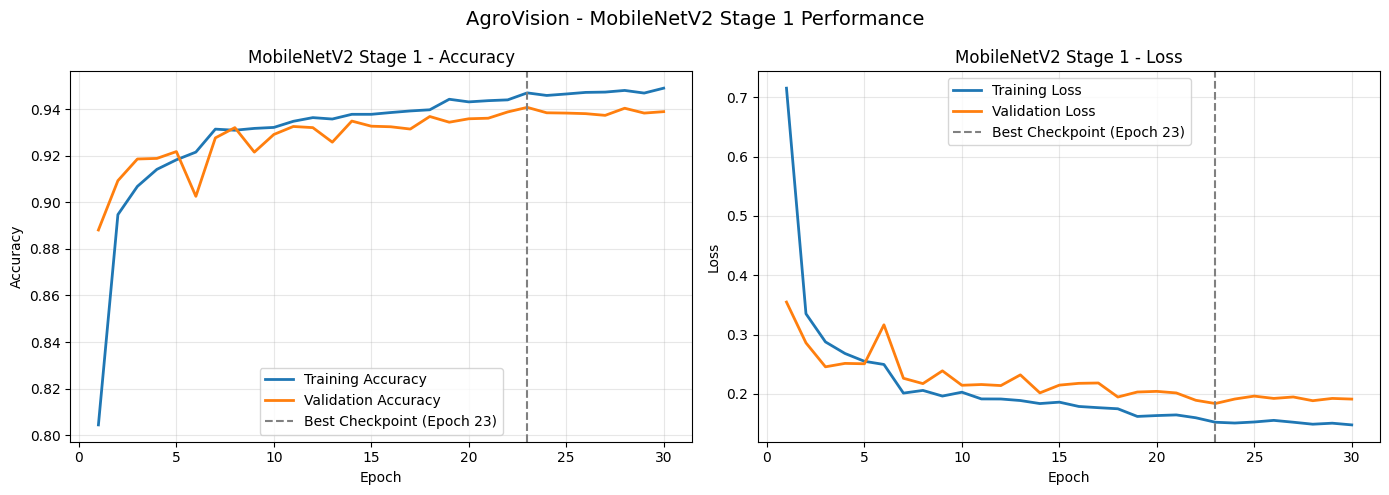


Training visualisation:
Epochs completed : 30
Best epoch       : 23
Best val loss    : 0.183626
Accuracy at best : 0.940895

Figure saved to: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/training_curves.png

PASS: MobileNetV2 Stage 1 training curves generated.


In [67]:
# ============================================================
# PHASE 4.15: MOBILENETV2 STAGE 1 VISUALISATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 1 VISUALISATION")
print("=" * 60)

# 1. Load saved training history
history_df = pd.read_csv(
    mobilenetv2_stage1_history_path
)

required_columns = [
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
]

assert all(
    col in history_df.columns
    for col in required_columns
), "Required training metrics are missing."

# 2. Prepare epoch numbers
epochs = np.arange(1, len(history_df) + 1)

# 3. Identify best checkpoint epoch
best_epoch = int(
    history_df["val_loss"].idxmin() + 1
)

assert best_epoch == mobilenetv2_stage1_best_epoch

# 4. Create training curves
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# Plot 1: Training and validation accuracy
# ------------------------------------------------------------

axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    x=best_epoch,
    linestyle="--",
    color="grey",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[0].set_title(
    "MobileNetV2 Stage 1 - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------------------
# Plot 2: Training and validation loss
# ------------------------------------------------------------

axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    x=best_epoch,
    linestyle="--",
    color="grey",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

axes[1].set_title(
    "MobileNetV2 Stage 1 - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "AgroVision - MobileNetV2 Stage 1 Performance",
    fontsize=14
)

plt.tight_layout()

# 5. Save figure
mobilenetv2_stage1_curves_path = (
    MOBILENETV2_STAGE1_DIR / "training_curves.png"
)

plt.savefig(
    mobilenetv2_stage1_curves_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Display summary
print("\nTraining visualisation:")
print(f"Epochs completed : {len(history_df)}")
print(f"Best epoch       : {best_epoch}")
print(
    f"Best val loss    : "
    f"{history_df['val_loss'].min():.6f}"
)
print(
    f"Accuracy at best : "
    f"{history_df.loc[best_epoch - 1, 'val_accuracy']:.6f}"
)

assert mobilenetv2_stage1_curves_path.exists()

print(f"\nFigure saved to: {mobilenetv2_stage1_curves_path}")

print("\nPASS: MobileNetV2 Stage 1 training curves generated.")
print("=" * 60)

In [68]:
# ============================================================
# PHASE 4.16: MOBILENETV2 STAGE 1 CHECKPOINT VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 CHECKPOINT VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify checkpoint exists
# ------------------------------------------------------------

assert mobilenetv2_stage1_checkpoint.exists(), (
    "MobileNetV2 Stage 1 checkpoint not found."
)

print("\nCheckpoint found:")
print(mobilenetv2_stage1_checkpoint)

# ------------------------------------------------------------
# 2. Load best saved model
# ------------------------------------------------------------

mobilenetv2_stage1_best_model = (
    tf.keras.models.load_model(
        str(mobilenetv2_stage1_checkpoint),
        compile=False
    )
)

# ------------------------------------------------------------
# 3. Verify model structure
# ------------------------------------------------------------

assert mobilenetv2_stage1_best_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_stage1_best_model.output_shape == (
    None, NUM_CLASSES
)

assert (
    mobilenetv2_stage1_best_model.count_params()
    == mobilenetv2_model.count_params()
)

# ------------------------------------------------------------
# 4. Compile for validation evaluation
# ------------------------------------------------------------

mobilenetv2_stage1_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Evaluate on validation dataset only
# ------------------------------------------------------------

print("\nEvaluating saved checkpoint on validation data...")

mobilenetv2_stage1_val_results = (
    mobilenetv2_stage1_best_model.evaluate(
        val_ds,
        verbose=1,
        return_dict=True
    )
)

saved_val_loss = float(
    mobilenetv2_stage1_val_results["loss"]
)

saved_val_accuracy = float(
    mobilenetv2_stage1_val_results["accuracy"]
)

# ------------------------------------------------------------
# 6. Compare against training history
# ------------------------------------------------------------

expected_val_loss = float(
    mobilenetv2_stage1_best_val_loss
)

expected_val_accuracy = float(
    mobilenetv2_stage1_best_epoch_accuracy
)

loss_difference = abs(
    saved_val_loss - expected_val_loss
)

accuracy_difference = abs(
    saved_val_accuracy - expected_val_accuracy
)

# Small numerical differences may occur after reloading.
assert np.isclose(
    saved_val_loss,
    expected_val_loss,
    atol=1e-4,
    rtol=0
), "Saved checkpoint validation loss differs unexpectedly."

assert np.isclose(
    saved_val_accuracy,
    expected_val_accuracy,
    atol=1e-4,
    rtol=0
), "Saved checkpoint validation accuracy differs unexpectedly."

# ------------------------------------------------------------
# 7. Display verification summary
# ------------------------------------------------------------

print("\nCheckpoint verification results:")
print(f"Model name             : {mobilenetv2_stage1_best_model.name}")
print(f"Total parameters       : {mobilenetv2_stage1_best_model.count_params():,}")
print(f"Best checkpoint epoch  : {mobilenetv2_stage1_best_epoch}")

print("\nValidation comparison:")
print(f"Expected val loss      : {expected_val_loss:.6f}")
print(f"Reloaded val loss      : {saved_val_loss:.6f}")
print(f"Loss difference        : {loss_difference:.8f}")

print(f"\nExpected val accuracy  : {expected_val_accuracy:.6f}")
print(f"Reloaded val accuracy  : {saved_val_accuracy:.6f}")
print(f"Accuracy difference    : {accuracy_difference:.8f}")

print("\nDataset usage:")
print("Training dataset       : Not evaluated")
print("Validation dataset     : Evaluated")
print("Test dataset           : Untouched")
print("External datasets      : Untouched")

print("\nPASS: MobileNetV2 Stage 1 checkpoint verified.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 CHECKPOINT VERIFICATION

Checkpoint found:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras

Evaluating saved checkpoint on validation data...
255/255 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.9409 - loss: 0.1836

Checkpoint verification results:
Model name             : AgroVision_MobileNetV2
Total parameters       : 2,306,662
Best checkpoint epoch  : 23

Validation comparison:
Expected val loss      : 0.183626
Reloaded val loss      : 0.183626
Loss difference        : 0.00000000

Expected val accuracy  : 0.940895
Reloaded val accuracy  : 0.940895
Accuracy difference    : 0.00000000

Dataset usage:
Training dataset       : Not evaluated
Validation dataset     : Evaluated
Test dataset           : Untouched
External datasets      : Untouched

PASS: MobileNetV2 Stage 1 checkpoint verified.


In [70]:
# ============================================================
# PHASE 4.16: MOBILENETV2 BACKBONE STRUCTURE INSPECTION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 BACKBONE INSPECTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Locate MobileNetV2 backbone in saved model
# ------------------------------------------------------------

mobilenetv2_stage2_backbone = next(
    layer
    for layer in mobilenetv2_stage1_best_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# ------------------------------------------------------------
# 2. Inspect backbone layers
# ------------------------------------------------------------

backbone_layers = mobilenetv2_stage2_backbone.layers

print("\nBackbone information:")
print("Backbone name  :", mobilenetv2_stage2_backbone.name)
print("Total layers  :", len(backbone_layers))
print("Trainable     :", mobilenetv2_stage2_backbone.trainable)

# ------------------------------------------------------------
# 3. Display final 50 layers
# ------------------------------------------------------------

print("\nFinal 50 backbone layers:")
print("-" * 90)

print(
    f"{'Index':<8}"
    f"{'Layer Name':<42}"
    f"{'Layer Type':<28}"
    f"{'Trainable'}"
)

print("-" * 90)

start_index = max(
    0,
    len(backbone_layers) - 50
)

for index in range(start_index, len(backbone_layers)):

    layer = backbone_layers[index]

    print(
        f"{index:<8}"
        f"{layer.name:<42}"
        f"{layer.__class__.__name__:<28}"
        f"{layer.trainable}"
    )

# ------------------------------------------------------------
# 4. Identify Batch Normalisation layers
# ------------------------------------------------------------

bn_layers = [
    layer
    for layer in backbone_layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

print("\nBatch Normalisation information:")
print("Total BN layers:", len(bn_layers))

# ------------------------------------------------------------
# 5. Identify later inverted residual blocks
# ------------------------------------------------------------

print("\nLater MobileNetV2 blocks:")
print("-" * 60)

for block_number in range(12, 17):

    block_prefix = f"block_{block_number}_"

    block_layers = [
        layer
        for layer in backbone_layers
        if layer.name.startswith(block_prefix)
    ]

    print(
        f"Block {block_number:<2}: "
        f"{len(block_layers)} layers"
    )

# ------------------------------------------------------------
# 6. Confirm Stage 1 backbone is frozen
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is False

assert all(
    not layer.trainable
    for layer in backbone_layers
)

print("\nPASS: MobileNetV2 backbone inspection completed.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 BACKBONE INSPECTION

Backbone information:
Backbone name  : mobilenetv2_1.00_160
Total layers  : 154
Trainable     : False

Final 50 backbone layers:
------------------------------------------------------------------------------------------
Index   Layer Name                                Layer Type                  Trainable
------------------------------------------------------------------------------------------
104     block_11_project                          Conv2D                      False
105     block_11_project_BN                       BatchNormalization          False
106     block_11_add                              Add                         False
107     block_12_expand                           Conv2D                      False
108     block_12_expand_BN                        BatchNormalization          False
109     block_12_expand_relu                      ReLU                        False
110     block_12_depthwise                    

AssertionError: 

In [71]:
# ============================================================
# PHASE 4.16: MOBILENETV2 BACKBONE FREEZE VERIFICATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 FREEZE VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Identify layers reporting trainable=True
# ------------------------------------------------------------

reported_trainable_layers = [
    (index, layer)
    for index, layer in enumerate(
        mobilenetv2_stage2_backbone.layers
    )
    if layer.trainable
]

print("\nLayers reporting trainable=True:")
print("-" * 75)

if reported_trainable_layers:

    for index, layer in reported_trainable_layers:

        print(
            f"Index: {index:<4} "
            f"Name: {layer.name:<35} "
            f"Type: {layer.__class__.__name__}"
        )

else:
    print("None")

# ------------------------------------------------------------
# 2. Inspect effective backbone trainable weights
# ------------------------------------------------------------

backbone_trainable_weights = (
    mobilenetv2_stage2_backbone.trainable_weights
)

backbone_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in backbone_trainable_weights
)

print("\nEffective backbone training status:")
print(
    "Backbone trainable flag :",
    mobilenetv2_stage2_backbone.trainable
)

print(
    "Trainable weight tensors:",
    len(backbone_trainable_weights)
)

print(
    "Trainable parameters    :",
    backbone_trainable_params
)

# ------------------------------------------------------------
# 3. Identify trainable weight-bearing layers
# ------------------------------------------------------------

trainable_weight_bearing_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if layer.trainable and len(layer.trainable_weights) > 0
]

print("\nTrainable weight-bearing layers:")
print(len(trainable_weight_bearing_layers))

# ------------------------------------------------------------
# 4. Verify actual freezing
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is False

assert len(backbone_trainable_weights) == 0

assert backbone_trainable_params == 0

assert len(trainable_weight_bearing_layers) == 0

print("\nPASS: MobileNetV2 backbone weights are frozen.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 FREEZE VERIFICATION

Layers reporting trainable=True:
---------------------------------------------------------------------------
Index: 0    Name: input_layer_4                       Type: InputLayer

Effective backbone training status:
Backbone trainable flag : False
Trainable weight tensors: 0
Trainable parameters    : 0

Trainable weight-bearing layers:
0

PASS: MobileNetV2 backbone weights are frozen.


In [72]:
# ============================================================
# PHASE 4.17: MOBILENETV2 STAGE 2 LAYER CONFIGURATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 CONFIGURATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load verified Stage 1 checkpoint
# ------------------------------------------------------------

mobilenetv2_stage2_model = tf.keras.models.load_model(
    str(mobilenetv2_stage1_checkpoint),
    compile=False
)

# ------------------------------------------------------------
# 2. Locate pretrained MobileNetV2 backbone
# ------------------------------------------------------------

mobilenetv2_stage2_backbone = next(
    layer
    for layer in mobilenetv2_stage2_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# ------------------------------------------------------------
# 3. Enable selective fine-tuning
# ------------------------------------------------------------

mobilenetv2_stage2_backbone.trainable = True

# Select the final four inverted residual blocks
fine_tune_prefixes = tuple(
    f"block_{i}_"
    for i in range(13, 17)
)

# Include final convolutional layer
fine_tune_final_layer = "Conv_1"

for layer in mobilenetv2_stage2_backbone.layers:

    is_selected_block = layer.name.startswith(
        fine_tune_prefixes
    )

    is_final_conv = (
        layer.name == fine_tune_final_layer
    )

    is_batch_norm = isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )

    # Only selected convolutional layers are trainable
    layer.trainable = (
        (is_selected_block or is_final_conv)
        and isinstance(
            layer,
            (
                tf.keras.layers.Conv2D,
                tf.keras.layers.DepthwiseConv2D
            )
        )
        and not is_batch_norm
    )

# ------------------------------------------------------------
# 4. Verify Batch Normalisation remains frozen
# ------------------------------------------------------------

bn_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert len(bn_layers) == 52

assert all(
    not layer.trainable
    for layer in bn_layers
)

# ------------------------------------------------------------
# 5. Identify trainable backbone layers
# ------------------------------------------------------------

trainable_backbone_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if layer.trainable
    and len(layer.trainable_weights) > 0
]

# ------------------------------------------------------------
# 6. Calculate trainable parameters
# ------------------------------------------------------------

backbone_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_stage2_backbone.trainable_weights
)

total_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_stage2_model.trainable_weights
)

total_params = mobilenetv2_stage2_model.count_params()

# ------------------------------------------------------------
# 7. Verify fine-tuning boundary
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is True

assert backbone_trainable_params > 0

assert total_trainable_params > 48678

assert total_trainable_params < total_params

assert all(
    layer.name.startswith(fine_tune_prefixes)
    or layer.name == fine_tune_final_layer
    for layer in trainable_backbone_layers
)

# ------------------------------------------------------------
# 8. Display configuration
# ------------------------------------------------------------

print("\nFine-tuning configuration:")
print("Architecture       :", mobilenetv2_stage2_model.name)
print("Backbone           :", mobilenetv2_stage2_backbone.name)
print("Training stage     : Stage 2 - Fine-Tuning")
print("Fine-tuning blocks : 13, 14, 15, 16")
print("Final convolution  : Conv_1")
print("BatchNorm frozen   :", all(not l.trainable for l in bn_layers))

print("\nParameter configuration:")
print(f"Total parameters              : {total_params:,}")
print(f"Trainable backbone parameters : {backbone_trainable_params:,}")
print(f"Total trainable parameters    : {total_trainable_params:,}")
print(f"Non-trainable parameters      : {total_params - total_trainable_params:,}")

print("\nTrainable backbone layers:")
print("-" * 65)

for layer in trainable_backbone_layers:
    print(
        f"{layer.name:<35}"
        f"{layer.__class__.__name__}"
    )

print("\nSummary:")
print(f"Trainable backbone layers : {len(trainable_backbone_layers)}")
print(f"Frozen BatchNorm layers   : {len(bn_layers)}")
print(f"Planned learning rate     : {FINE_TUNING_LEARNING_RATE}")

print("\nPASS: MobileNetV2 Stage 2 layers configured.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 CONFIGURATION

Fine-tuning configuration:
Architecture       : AgroVision_MobileNetV2
Backbone           : mobilenetv2_1.00_160
Training stage     : Stage 2 - Fine-Tuning
Fine-tuning blocks : 13, 14, 15, 16
Final convolution  : Conv_1
BatchNorm frozen   : True

Parameter configuration:
Total parameters              : 2,306,662
Trainable backbone parameters : 1,663,360
Total trainable parameters    : 1,712,038
Non-trainable parameters      : 594,624

Trainable backbone layers:
-----------------------------------------------------------------
block_13_expand                    Conv2D
block_13_depthwise                 DepthwiseConv2D
block_13_project                   Conv2D
block_14_expand                    Conv2D
block_14_depthwise                 DepthwiseConv2D
block_14_project                   Conv2D
block_15_expand                    Conv2D
block_15_depthwise                 DepthwiseConv2D
block_15_project                   Conv2D
block_16_e

In [73]:
# ============================================================
# PHASE 4.17: MOBILENETV2 STAGE 2 COMPILATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 COMPILATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify fine-tuning configuration
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is True

assert all(
    not layer.trainable
    for layer in mobilenetv2_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

# ------------------------------------------------------------
# 2. Create fresh Stage 2 optimiser
# ------------------------------------------------------------

mobilenetv2_stage2_optimizer = (
    tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNING_LEARNING_RATE
    )
)

# ------------------------------------------------------------
# 3. Compile fine-tuning model
# ------------------------------------------------------------

mobilenetv2_stage2_model.compile(
    optimizer=mobilenetv2_stage2_optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 4. Verify learning rate
# ------------------------------------------------------------

actual_lr = float(
    mobilenetv2_stage2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE
)

# ------------------------------------------------------------
# 5. Verify trainable parameters
# ------------------------------------------------------------

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_stage2_model.trainable_weights
)

assert trainable_params == 1712038

assert (
    mobilenetv2_stage2_model.output_shape
    == (None, NUM_CLASSES)
)

# ------------------------------------------------------------
# 6. Verify selected backbone layers
# ------------------------------------------------------------

trainable_backbone_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if layer.trainable
    and len(layer.trainable_weights) > 0
]

assert len(trainable_backbone_layers) == 13

assert all(
    layer.name.startswith(
        tuple(f"block_{i}_" for i in range(13, 17))
    )
    or layer.name == "Conv_1"
    for layer in trainable_backbone_layers
)

# ------------------------------------------------------------
# 7. Display compilation summary
# ------------------------------------------------------------

print("\nModel configuration:")
print("Architecture       :", mobilenetv2_stage2_model.name)
print("Training stage     : Stage 2 - Fine-Tuning")
print("Backbone trainable :", mobilenetv2_stage2_backbone.trainable)

print("\nOptimisation configuration:")
print("Optimiser          : Adam")
print(f"Learning rate      : {actual_lr:.8f}")
print("Loss function      : SparseCategoricalCrossentropy")
print("Evaluation metric  : Accuracy")

print("\nParameter configuration:")
print(f"Trainable parameters    : {trainable_params:,}")
print(f"Trainable backbone layers: {len(trainable_backbone_layers)}")

print("\nBatch Normalisation:")
print("Total BN layers   : 52")
print("All BN frozen     : True")

print("\nPASS: MobileNetV2 Stage 2 compiled successfully.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 COMPILATION

Model configuration:
Architecture       : AgroVision_MobileNetV2
Training stage     : Stage 2 - Fine-Tuning
Backbone trainable : True

Optimisation configuration:
Optimiser          : Adam
Learning rate      : 0.00001000
Loss function      : SparseCategoricalCrossentropy
Evaluation metric  : Accuracy

Parameter configuration:
Trainable parameters    : 1,712,038
Trainable backbone layers: 13

Batch Normalisation:
Total BN layers   : 52
All BN frozen     : True

PASS: MobileNetV2 Stage 2 compiled successfully.


In [74]:
# ============================================================
# PHASE 4.17: MOBILENETV2 STAGE 2 CHECKPOINTS AND CALLBACKS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 CALLBACKS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Create Stage 2 experiment directory
# ------------------------------------------------------------

MOBILENETV2_STAGE2_DIR = (
    MOBILENETV2_DIR / "stage2"
)

MOBILENETV2_STAGE2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Define Stage 2 output paths
# ------------------------------------------------------------

mobilenetv2_stage2_checkpoint = (
    MOBILENETV2_STAGE2_DIR / "best_model.keras"
)

mobilenetv2_stage2_history_path = (
    MOBILENETV2_STAGE2_DIR / "training_history.csv"
)

mobilenetv2_stage2_log_path = (
    MOBILENETV2_STAGE2_DIR / "epoch_log.csv"
)

# ------------------------------------------------------------
# 3. Prevent accidental overwriting
# ------------------------------------------------------------

stage2_output_paths = [
    mobilenetv2_stage2_checkpoint,
    mobilenetv2_stage2_history_path,
    mobilenetv2_stage2_log_path
]

existing_stage2_outputs = [
    path
    for path in stage2_output_paths
    if path.exists()
]

assert not existing_stage2_outputs, (
    "Existing MobileNetV2 Stage 2 files detected: "
    + ", ".join(str(p) for p in existing_stage2_outputs)
)

# ------------------------------------------------------------
# 4. Configure callbacks
# ------------------------------------------------------------

mobilenetv2_stage2_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(mobilenetv2_stage2_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(mobilenetv2_stage2_log_path),
        append=False
    )
]

# ------------------------------------------------------------
# 5. Verify callback configuration
# ------------------------------------------------------------

assert len(mobilenetv2_stage2_callbacks) == 4

assert MOBILENETV2_STAGE2_DIR.exists()

assert (
    mobilenetv2_stage2_checkpoint
    != mobilenetv2_stage1_checkpoint
)

assert (
    mobilenetv2_stage2_checkpoint
    != resnet50_stage2_checkpoint
)

assert np.isclose(
    float(
        mobilenetv2_stage2_model.optimizer.learning_rate.numpy()
    ),
    FINE_TUNING_LEARNING_RATE
)

# ------------------------------------------------------------
# 6. Display configuration
# ------------------------------------------------------------

print("\nExperiment directory:")
print(MOBILENETV2_STAGE2_DIR)

print("\nOutput files:")
print("Best checkpoint :", mobilenetv2_stage2_checkpoint)
print("Training history:", mobilenetv2_stage2_history_path)
print("Epoch log       :", mobilenetv2_stage2_log_path)

print("\nCallback configuration:")

for callback in mobilenetv2_stage2_callbacks:
    print(f"  - {callback.__class__.__name__}")

print("\nTraining settings:")
print(f"Maximum epochs         : {FINE_TUNING_EPOCHS}")
print(f"Initial learning rate  : {FINE_TUNING_LEARNING_RATE}")
print(f"Monitoring metric      : {MONITOR_METRIC}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience  : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor    : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate  : {MIN_LEARNING_RATE}")

print("\nPASS: MobileNetV2 Stage 2 callbacks configured.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 CALLBACKS

Experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2

Output files:
Best checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras
Training history: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/training_history.csv
Epoch log       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/epoch_log.csv

Callback configuration:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Training settings:
Maximum epochs         : 50
Initial learning rate  : 1e-05
Monitoring metric      : val_loss
Early stopping patience: 7
LR reduction patience  : 3
LR reduction factor    : 0.5
Minimum learning rate  : 1e-07

PASS: MobileNetV2 Stage 2 callbacks configured.


In [75]:
# ============================================================
# PHASE 4.17: MOBILENETV2 STAGE 2 TRAINING READINESS
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 READINESS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify dataset configuration
# ------------------------------------------------------------

assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(test_data) == 8151

assert NUM_CLASSES == 38
assert IMAGE_SIZE == (160, 160)
assert BATCH_SIZE == 32

# ------------------------------------------------------------
# 2. Verify model architecture
# ------------------------------------------------------------

assert mobilenetv2_stage2_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_stage2_model.output_shape == (
    None, NUM_CLASSES
)

assert (
    mobilenetv2_stage2_model.count_params()
    == 2306662
)

# ------------------------------------------------------------
# 3. Verify fine-tuning configuration
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is True

fine_tune_prefixes = tuple(
    f"block_{i}_"
    for i in range(13, 17)
)

trainable_backbone_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if layer.trainable and len(layer.trainable_weights) > 0
]

assert len(trainable_backbone_layers) == 13

assert all(
    (
        layer.name.startswith(fine_tune_prefixes)
        or layer.name == "Conv_1"
    )
    and isinstance(
        layer,
        (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D
        )
    )
    for layer in trainable_backbone_layers
)

# ------------------------------------------------------------
# 4. Verify Batch Normalisation
# ------------------------------------------------------------

bn_layers = [
    layer
    for layer in mobilenetv2_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert len(bn_layers) == 52

assert all(
    not layer.trainable
    for layer in bn_layers
)

# ------------------------------------------------------------
# 5. Verify trainable parameters
# ------------------------------------------------------------

backbone_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_stage2_backbone.trainable_weights
)

total_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in mobilenetv2_stage2_model.trainable_weights
)

assert backbone_trainable_params == 1663360
assert total_trainable_params == 1712038

# ------------------------------------------------------------
# 6. Verify optimiser and learning rate
# ------------------------------------------------------------

assert isinstance(
    mobilenetv2_stage2_model.optimizer,
    tf.keras.optimizers.Adam
)

actual_lr = float(
    mobilenetv2_stage2_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE
)

# ------------------------------------------------------------
# 7. Verify class weights
# ------------------------------------------------------------

assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

# ------------------------------------------------------------
# 8. Verify callbacks
# ------------------------------------------------------------

expected_callback_types = [
    tf.keras.callbacks.ModelCheckpoint,
    tf.keras.callbacks.EarlyStopping,
    tf.keras.callbacks.ReduceLROnPlateau,
    tf.keras.callbacks.CSVLogger
]

assert len(mobilenetv2_stage2_callbacks) == 4

assert all(
    isinstance(callback, expected_type)
    for callback, expected_type in zip(
        mobilenetv2_stage2_callbacks,
        expected_callback_types
    )
)

# ------------------------------------------------------------
# 9. Verify checkpoint paths
# ------------------------------------------------------------

assert MOBILENETV2_STAGE2_DIR.exists()

assert mobilenetv2_stage1_checkpoint.exists()

assert (
    mobilenetv2_stage2_checkpoint
    != mobilenetv2_stage1_checkpoint
)

assert (
    mobilenetv2_stage2_checkpoint
    != resnet50_stage2_checkpoint
)

# ------------------------------------------------------------
# 10. Prevent accidental overwriting
# ------------------------------------------------------------

existing_outputs = [
    path
    for path in [
        mobilenetv2_stage2_checkpoint,
        mobilenetv2_stage2_history_path,
        mobilenetv2_stage2_log_path
    ]
    if path.exists()
]

assert not existing_outputs, (
    "Existing Stage 2 outputs detected: "
    + ", ".join(str(path) for path in existing_outputs)
)

# ------------------------------------------------------------
# 11. Display readiness summary
# ------------------------------------------------------------

print("\nDataset configuration:")
print(f"  Training images       : {len(train_data):,}")
print(f"  Validation images     : {len(val_data):,}")
print(f"  Test images           : {len(test_data):,}")

print("\nModel configuration:")
print(f"  Architecture          : {mobilenetv2_stage2_model.name}")
print(f"  Total parameters      : {mobilenetv2_stage2_model.count_params():,}")
print(f"  Trainable parameters  : {total_trainable_params:,}")
print(f"  Backbone trainable    : {mobilenetv2_stage2_backbone.trainable}")

print("\nFine-tuning configuration:")
print("  Selected blocks       : 13, 14, 15, 16")
print("  Final convolution     : Conv_1")
print(f"  Trainable conv layers : {len(trainable_backbone_layers)}")
print(f"  Frozen BN layers      : {len(bn_layers)}")

print("\nTraining configuration:")
print(f"  Batch size            : {BATCH_SIZE}")
print(f"  Maximum epochs        : {FINE_TUNING_EPOCHS}")
print(f"  Learning rate         : {actual_lr:.8f}")
print(f"  Class weights         : {len(class_weights)}")
print(f"  Callbacks             : {len(mobilenetv2_stage2_callbacks)}")
print(f"  Monitor               : {MONITOR_METRIC}")

print("\nExperiment configuration:")
print(f"  Stage 1 checkpoint    : {mobilenetv2_stage1_checkpoint}")
print(f"  Stage 2 checkpoint    : {mobilenetv2_stage2_checkpoint}")

print("\nDataset usage:")
print("  Training dataset      : Used for training")
print("  Validation dataset    : Used for model selection")
print("  Test dataset          : Reserved")
print("  External datasets     : Reserved")

print("\nPASS: MobileNetV2 is ready for Stage 2 training.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 READINESS

Dataset configuration:
  Training images       : 37,978
  Validation images     : 8,155
  Test images           : 8,151

Model configuration:
  Architecture          : AgroVision_MobileNetV2
  Total parameters      : 2,306,662
  Trainable parameters  : 1,712,038
  Backbone trainable    : True

Fine-tuning configuration:
  Selected blocks       : 13, 14, 15, 16
  Final convolution     : Conv_1
  Trainable conv layers : 13
  Frozen BN layers      : 52

Training configuration:
  Batch size            : 32
  Maximum epochs        : 50
  Learning rate         : 0.00001000
  Class weights         : 38
  Callbacks             : 4
  Monitor               : val_loss

Experiment configuration:
  Stage 1 checkpoint    : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage1/best_model.keras
  Stage 2 checkpoint    : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras

Dataset usage:
  Tr

In [76]:
# ============================================================
# PHASE 4.18: MOBILENETV2 STAGE 2 - FINE-TUNING
# ============================================================

import time

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. Prevent accidental overwriting
# ------------------------------------------------------------

stage2_training_outputs = [
    mobilenetv2_stage2_checkpoint,
    mobilenetv2_stage2_history_path,
    mobilenetv2_stage2_log_path
]

assert not any(
    path.exists() for path in stage2_training_outputs
), (
    "Existing MobileNetV2 Stage 2 files detected. "
    "Review them before starting another run."
)

# ------------------------------------------------------------
# 2. Verify fine-tuning configuration
# ------------------------------------------------------------

assert mobilenetv2_stage2_backbone.trainable is True

assert all(
    not layer.trainable
    for layer in mobilenetv2_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

assert np.isclose(
    float(
        mobilenetv2_stage2_model.optimizer.learning_rate.numpy()
    ),
    FINE_TUNING_LEARNING_RATE
)

assert len(class_weights) == NUM_CLASSES

# ------------------------------------------------------------
# 3. Display training configuration
# ------------------------------------------------------------

print("\nTraining configuration:")
print(f"Architecture       : {mobilenetv2_stage2_model.name}")
print("Training stage     : Stage 2 - Fine-Tuning")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {FINE_TUNING_EPOCHS}")
print(f"Initial LR         : {FINE_TUNING_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {mobilenetv2_stage2_checkpoint}")

print("\nStarting MobileNetV2 Stage 2 fine-tuning...\n")

# ------------------------------------------------------------
# 4. Record training start time
# ------------------------------------------------------------

mobilenetv2_stage2_start = time.time()

# ------------------------------------------------------------
# 5. Fine-tune MobileNetV2
# ------------------------------------------------------------

mobilenetv2_stage2_history = mobilenetv2_stage2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNING_EPOCHS,
    class_weight=class_weights,
    callbacks=mobilenetv2_stage2_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 6. Calculate training duration
# ------------------------------------------------------------

mobilenetv2_stage2_duration = (
    time.time() - mobilenetv2_stage2_start
)

# ------------------------------------------------------------
# 7. Save training history
# ------------------------------------------------------------

mobilenetv2_stage2_history_df = pd.DataFrame(
    mobilenetv2_stage2_history.history
)

mobilenetv2_stage2_history_df.to_csv(
    mobilenetv2_stage2_history_path,
    index=False
)

# ------------------------------------------------------------
# 8. Identify best checkpoint epoch
# ------------------------------------------------------------

best_epoch_index = int(
    np.argmin(
        mobilenetv2_stage2_history.history["val_loss"]
    )
)

mobilenetv2_stage2_best_epoch = (
    best_epoch_index + 1
)

mobilenetv2_stage2_best_val_loss = (
    mobilenetv2_stage2_history.history["val_loss"][
        best_epoch_index
    ]
)

mobilenetv2_stage2_best_epoch_accuracy = (
    mobilenetv2_stage2_history.history["val_accuracy"][
        best_epoch_index
    ]
)

mobilenetv2_stage2_highest_val_accuracy = max(
    mobilenetv2_stage2_history.history["val_accuracy"]
)

# ------------------------------------------------------------
# 9. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MOBILENETV2 STAGE 2 TRAINING COMPLETED")
print("=" * 60)

print(
    f"Epochs completed       : "
    f"{len(mobilenetv2_stage2_history.epoch)}"
)

print(
    f"Training duration      : "
    f"{mobilenetv2_stage2_duration / 60:.2f} minutes"
)

print(
    f"Best checkpoint epoch  : "
    f"{mobilenetv2_stage2_best_epoch}"
)

print(
    f"Best validation loss   : "
    f"{mobilenetv2_stage2_best_val_loss:.6f}"
)

print(
    f"Accuracy at best epoch : "
    f"{mobilenetv2_stage2_best_epoch_accuracy:.6f}"
)

print(
    f"Highest val accuracy   : "
    f"{mobilenetv2_stage2_highest_val_accuracy:.6f}"
)

print("\nSaved files:")
print("Best checkpoint :", mobilenetv2_stage2_checkpoint)
print("Training history:", mobilenetv2_stage2_history_path)
print("Epoch log       :", mobilenetv2_stage2_log_path)

# ------------------------------------------------------------
# 10. Verify saved outputs
# ------------------------------------------------------------

assert mobilenetv2_stage2_checkpoint.exists()
assert mobilenetv2_stage2_history_path.exists()
assert mobilenetv2_stage2_log_path.exists()

print("\nPASS: MobileNetV2 Stage 2 training completed.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 TRAINING

Training configuration:
Architecture       : AgroVision_MobileNetV2
Training stage     : Stage 2 - Fine-Tuning
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 1e-05
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras

Starting MobileNetV2 Stage 2 fine-tuning...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9387 - loss: 0.1813
Epoch 1: val_loss improved from None to 0.24287, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 71s 54ms/step - accuracy: 0.9428 - loss: 0.1661 - val_accuracy: 0.9245 - val_loss: 0.2429 - learning_rate: 1.0000e-05
Epo

In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Runtime is working!")

TensorFlow version: 2.21.0
Available GPUs: []
Runtime is working!


In [2]:
from pathlib import Path
import os

print("Current directory:", os.getcwd())

project_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

checkpoint = (
    project_dir
    / "model_experiments"
    / "MobileNetV2"
    / "stage2"
    / "best_model.keras"
)

history_file = (
    project_dir
    / "model_experiments"
    / "MobileNetV2"
    / "stage2"
    / "training_history.csv"
)

print("Project directory exists:", project_dir.exists())
print("Stage 2 checkpoint exists:", checkpoint.exists())
print("Stage 2 history exists:", history_file.exists())

Current directory: /content
Project directory exists: False
Stage 2 checkpoint exists: False
Stage 2 history exists: False


In [3]:
# ============================================================
# RESTORE GOOGLE DRIVE CONNECTION
# ============================================================

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Verify AgroVision project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

print("\nGoogle Drive verification:")
print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("AgroVision project found:", PROJECT_DIR.exists())

# Verify MobileNetV2 Stage 2 files
stage2_dir = (
    PROJECT_DIR
    / "model_experiments"
    / "MobileNetV2"
    / "stage2"
)

print("\nMobileNetV2 Stage 2 files:")
print("Checkpoint:", (stage2_dir / "best_model.keras").exists())
print("History   :", (stage2_dir / "training_history.csv").exists())
print("Epoch log :", (stage2_dir / "epoch_log.csv").exists())

Mounted at /content/drive

Google Drive verification:
Drive mounted: True
AgroVision project found: True

MobileNetV2 Stage 2 files:
Checkpoint: True
History   : True
Epoch log : True


AGROVISION FYP2 - MOBILENETV2 STAGE 2 VISUALISATION


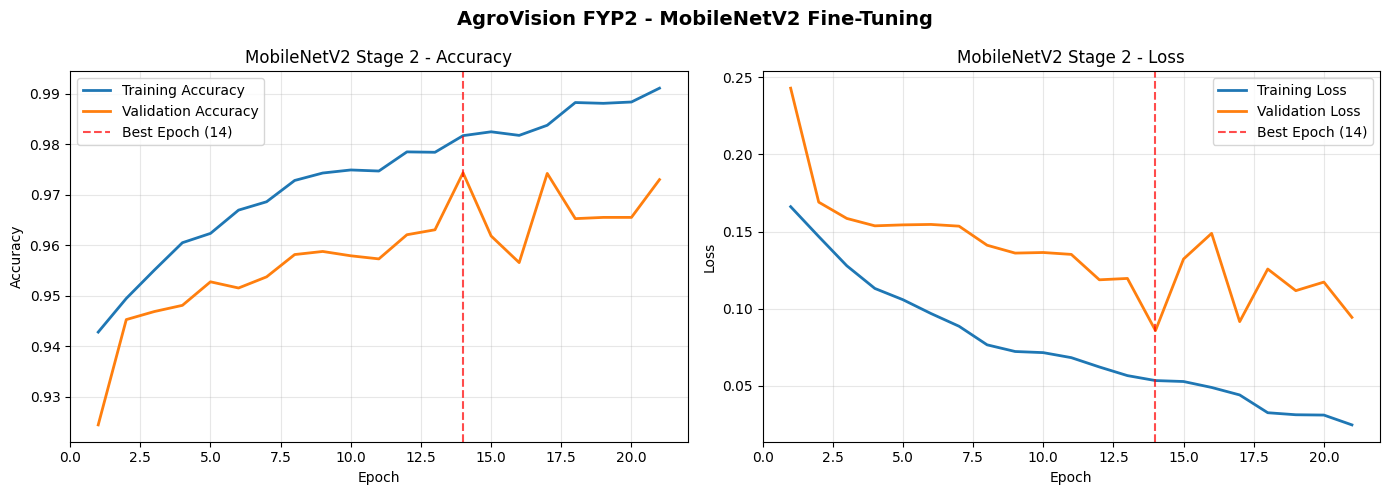


Training summary:
Epochs completed      : 21
Best checkpoint epoch : 14
Best validation loss  : 0.085886
Accuracy at best epoch: 0.974372

Visualisation saved:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/training_curves.png

PASS: MobileNetV2 Stage 2 visualisation completed.


In [4]:
# ============================================================
# PHASE 4.19: MOBILENETV2 STAGE 2 TRAINING VISUALISATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 VISUALISATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore experiment paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

EXPERIMENT_DIR = PROJECT_DIR / "model_experiments"

MOBILENETV2_DIR = EXPERIMENT_DIR / "MobileNetV2"

MOBILENETV2_STAGE2_DIR = (
    MOBILENETV2_DIR / "stage2"
)

mobilenetv2_stage2_history_path = (
    MOBILENETV2_STAGE2_DIR / "training_history.csv"
)

mobilenetv2_stage2_curves_path = (
    MOBILENETV2_STAGE2_DIR / "training_curves.png"
)

# ------------------------------------------------------------
# 2. Load saved training history
# ------------------------------------------------------------

assert mobilenetv2_stage2_history_path.exists(), (
    "MobileNetV2 Stage 2 history file not found."
)

mobilenetv2_stage2_history_df = pd.read_csv(
    mobilenetv2_stage2_history_path
)

required_columns = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

assert all(
    column in mobilenetv2_stage2_history_df.columns
    for column in required_columns
)

assert not mobilenetv2_stage2_history_df[
    required_columns
].isna().any().any()

# ------------------------------------------------------------
# 3. Identify best checkpoint epoch
# ------------------------------------------------------------

epochs = np.arange(
    1,
    len(mobilenetv2_stage2_history_df) + 1
)

best_epoch_index = int(
    mobilenetv2_stage2_history_df["val_loss"].idxmin()
)

mobilenetv2_stage2_best_epoch = (
    best_epoch_index + 1
)

mobilenetv2_stage2_best_val_loss = float(
    mobilenetv2_stage2_history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

mobilenetv2_stage2_best_epoch_accuracy = float(
    mobilenetv2_stage2_history_df.loc[
        best_epoch_index,
        "val_accuracy"
    ]
)

# ------------------------------------------------------------
# 4. Create training visualisation
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    epochs,
    mobilenetv2_stage2_history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    mobilenetv2_stage2_history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    mobilenetv2_stage2_best_epoch,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Best Epoch ({mobilenetv2_stage2_best_epoch})"
)

axes[0].set_title(
    "MobileNetV2 Stage 2 - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    epochs,
    mobilenetv2_stage2_history_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    mobilenetv2_stage2_history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    mobilenetv2_stage2_best_epoch,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Best Epoch ({mobilenetv2_stage2_best_epoch})"
)

axes[1].set_title(
    "MobileNetV2 Stage 2 - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "AgroVision FYP2 - MobileNetV2 Fine-Tuning",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# 5. Save visualisation
# ------------------------------------------------------------

plt.savefig(
    mobilenetv2_stage2_curves_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Verify expected training results
# ------------------------------------------------------------

assert len(mobilenetv2_stage2_history_df) == 21

assert mobilenetv2_stage2_best_epoch == 14

assert np.isclose(
    mobilenetv2_stage2_best_val_loss,
    0.085886,
    atol=1e-5
)

assert mobilenetv2_stage2_curves_path.exists()

# ------------------------------------------------------------
# 7. Display summary
# ------------------------------------------------------------

print("\nTraining summary:")
print(
    f"Epochs completed      : "
    f"{len(mobilenetv2_stage2_history_df)}"
)

print(
    f"Best checkpoint epoch : "
    f"{mobilenetv2_stage2_best_epoch}"
)

print(
    f"Best validation loss  : "
    f"{mobilenetv2_stage2_best_val_loss:.6f}"
)

print(
    f"Accuracy at best epoch: "
    f"{mobilenetv2_stage2_best_epoch_accuracy:.6f}"
)

print("\nVisualisation saved:")
print(mobilenetv2_stage2_curves_path)

print("\nPASS: MobileNetV2 Stage 2 visualisation completed.")
print("=" * 60)

In [5]:
# ============================================================
# PHASE 4.20: MOBILENETV2 STAGE 2 CHECKPOINT VERIFICATION
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore checkpoint path
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

EXPERIMENT_DIR = PROJECT_DIR / "model_experiments"

MOBILENETV2_DIR = EXPERIMENT_DIR / "MobileNetV2"

MOBILENETV2_STAGE2_DIR = (
    MOBILENETV2_DIR / "stage2"
)

mobilenetv2_stage2_checkpoint = (
    MOBILENETV2_STAGE2_DIR / "best_model.keras"
)

mobilenetv2_stage2_history_path = (
    MOBILENETV2_STAGE2_DIR / "training_history.csv"
)

# ------------------------------------------------------------
# 2. Verify saved files
# ------------------------------------------------------------

assert mobilenetv2_stage2_checkpoint.exists()
assert mobilenetv2_stage2_history_path.exists()

# ------------------------------------------------------------
# 3. Load best Stage 2 checkpoint
# ------------------------------------------------------------

mobilenetv2_stage2_best_model = (
    tf.keras.models.load_model(
        str(mobilenetv2_stage2_checkpoint),
        compile=False
    )
)

# ------------------------------------------------------------
# 4. Compile for validation evaluation
# ------------------------------------------------------------

mobilenetv2_stage2_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Verify checkpoint architecture
# ------------------------------------------------------------

assert mobilenetv2_stage2_best_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_stage2_best_model.output_shape == (
    None, 38
)

assert (
    mobilenetv2_stage2_best_model.count_params()
    == 2306662
)

print("\nCheckpoint loaded successfully.")
print("Model:", mobilenetv2_stage2_best_model.name)

# ------------------------------------------------------------
# 6. Check validation dataset availability
# ------------------------------------------------------------

if "val_ds" not in globals():
    print("\nVALIDATION DATASET NOT AVAILABLE")
    print(
        "The previous Colab runtime was reset, "
        "so val_ds must be reconstructed."
    )
    print(
        "Checkpoint loading succeeded. "
        "Validation evaluation has been deferred."
    )

else:

    # --------------------------------------------------------
    # 7. Evaluate saved checkpoint
    # --------------------------------------------------------

    print("\nEvaluating saved checkpoint...")

    validation_results = (
        mobilenetv2_stage2_best_model.evaluate(
            val_ds,
            verbose=1,
            return_dict=True
        )
    )

    # --------------------------------------------------------
    # 8. Compare against saved training history
    # --------------------------------------------------------

    history_df = pd.read_csv(
        mobilenetv2_stage2_history_path
    )

    best_idx = int(
        history_df["val_loss"].idxmin()
    )

    recorded_loss = float(
        history_df.loc[best_idx, "val_loss"]
    )

    recorded_accuracy = float(
        history_df.loc[best_idx, "val_accuracy"]
    )

    evaluated_loss = float(
        validation_results["loss"]
    )

    evaluated_accuracy = float(
        validation_results["accuracy"]
    )

    print("\nValidation comparison:")
    print(f"Recorded loss     : {recorded_loss:.6f}")
    print(f"Evaluated loss    : {evaluated_loss:.6f}")
    print(f"Recorded accuracy : {recorded_accuracy:.6f}")
    print(f"Evaluated accuracy: {evaluated_accuracy:.6f}")

    print("\nAbsolute differences:")
    print(
        f"Loss difference    : "
        f"{abs(recorded_loss - evaluated_loss):.8f}"
    )
    print(
        f"Accuracy difference: "
        f"{abs(recorded_accuracy - evaluated_accuracy):.8f}"
    )

    assert np.isclose(
        recorded_loss,
        evaluated_loss,
        atol=1e-4
    )

    assert np.isclose(
        recorded_accuracy,
        evaluated_accuracy,
        atol=1e-4
    )

    print(
        "\nPASS: MobileNetV2 Stage 2 checkpoint "
        "reproduces recorded validation results."
    )

print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 VERIFICATION

Checkpoint loaded successfully.
Model: AgroVision_MobileNetV2

VALIDATION DATASET NOT AVAILABLE
The previous Colab runtime was reset, so val_ds must be reconstructed.
Checkpoint loading succeeded. Validation evaluation has been deferred.


In [6]:
# ============================================================
# PHASE 4.20: VALIDATION DATASET RECOVERY
# ============================================================

from pathlib import Path
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - VALIDATION DATASET RECOVERY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify project directory
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

assert PROJECT_DIR.exists(), (
    "AgroVision project directory not found."
)

# ------------------------------------------------------------
# 2. Search for saved dataset metadata
# ------------------------------------------------------------

search_extensions = {
    ".csv",
    ".json",
    ".parquet"
}

metadata_files = sorted(
    [
        path
        for path in PROJECT_DIR.rglob("*")
        if path.is_file()
        and path.suffix.lower() in search_extensions
        and any(
            keyword in path.name.lower()
            for keyword in [
                "split",
                "val",
                "manifest",
                "mapping",
                "class"
            ]
        )
    ],
    key=lambda path: str(path)
)

print("\nPotential dataset metadata files:")

if metadata_files:
    for index, path in enumerate(metadata_files, 1):
        print(f"{index}. {path.relative_to(PROJECT_DIR)}")
else:
    print("No matching metadata files found.")

# ------------------------------------------------------------
# 3. Inspect candidate CSV files
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("CSV FILE STRUCTURE")
print("-" * 60)

for path in metadata_files:

    if path.suffix.lower() != ".csv":
        continue

    try:
        df = pd.read_csv(path, nrows=5)

        print(f"\nFile: {path.relative_to(PROJECT_DIR)}")
        print("Columns:", df.columns.tolist())
        print("Sample rows:")
        print(df.head(2).to_string(index=False))

    except Exception as error:
        print(f"\nCould not inspect {path.name}: {error}")

# ------------------------------------------------------------
# 4. Check whether validation dataset exists in memory
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("RUNTIME VARIABLE STATUS")
print("-" * 60)

for variable_name in [
    "val_data",
    "val_ds",
    "class_names",
    "class_to_index",
    "NUM_CLASSES",
    "IMAGE_SIZE",
    "BATCH_SIZE"
]:
    print(
        f"{variable_name:20}: "
        f"{variable_name in globals()}"
    )

print("\nPASS: Validation dataset recovery inspection completed.")
print("=" * 60)

AGROVISION FYP2 - VALIDATION DATASET RECOVERY

Potential dataset metadata files:
1. mapping_results/fieldplant_approved_mapping.csv
2. mapping_results/fieldplant_candidate_mapping.csv
3. mapping_results/fieldplant_full_mapping.csv
4. mapping_results/plantdoc_final_mapping.csv
5. plantvillage_preparation/class_distribution.csv
6. plantvillage_preparation/class_split_distribution.csv
7. plantvillage_preparation/class_to_index.json
8. plantvillage_preparation/class_weights.json
9. plantvillage_preparation/final_split_manifest.csv
10. plantvillage_preparation/split_grouping_inventory.csv
11. plantvillage_preparation/split_summary.csv
12. plantvillage_preparation/training_class_weights.csv

------------------------------------------------------------
CSV FILE STRUCTURE
------------------------------------------------------------

File: mapping_results/fieldplant_approved_mapping.csv
Columns: ['class_id', 'class_name', 'plantvillage_class', 'mapping_category', 'justification', 'annotated_obj

In [7]:
# ============================================================
# PHASE 4.20: LOCATE ORIGINAL PLANTVILLAGE IMAGE DIRECTORY
# ============================================================

from pathlib import Path
import pandas as pd
import json

print("=" * 60)
print("AGROVISION FYP2 - PLANTVILLAGE DATASET LOCATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore project paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

PREPARATION_DIR = (
    PROJECT_DIR / "plantvillage_preparation"
)

manifest_path = (
    PREPARATION_DIR / "final_split_manifest.csv"
)

class_mapping_path = (
    PREPARATION_DIR / "class_to_index.json"
)

assert manifest_path.exists()
assert class_mapping_path.exists()

# ------------------------------------------------------------
# 2. Restore original dataset metadata
# ------------------------------------------------------------

split_manifest = pd.read_csv(manifest_path)

with open(class_mapping_path, "r") as file:
    class_to_index = json.load(file)

NUM_CLASSES = 38
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

assert len(class_to_index) == NUM_CLASSES

# ------------------------------------------------------------
# 3. Recover frozen validation split
# ------------------------------------------------------------

val_data = (
    split_manifest[
        split_manifest["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(val_data) == 8155

assert val_data["plantvillage_class"].isin(
    class_to_index.keys()
).all()

val_data["class_index"] = (
    val_data["plantvillage_class"]
    .map(class_to_index)
    .astype(int)
)

print("\nOriginal validation split:")
print(f"Validation images : {len(val_data):,}")
print(f"Number of classes : {NUM_CLASSES}")
print(f"Image size        : {IMAGE_SIZE}")
print(f"Batch size        : {BATCH_SIZE}")

# ------------------------------------------------------------
# 4. Inspect original image paths
# ------------------------------------------------------------

print("\nOriginal manifest paths:")

for path in val_data["filepath"].head(3):
    print(path)

original_paths_found = sum(
    Path(path).is_file()
    for path in val_data["filepath"].head(10)
)

print(
    f"\nAccessible original paths (sample): "
    f"{original_paths_found}/10"
)

# ------------------------------------------------------------
# 5. Search common dataset locations
# ------------------------------------------------------------

search_roots = [
    Path("/content"),
    Path("/root/.cache/kagglehub/datasets"),
    PROJECT_DIR
]

print("\nPotential PlantVillage image directories:")

candidate_dirs = []

for root in search_roots:

    if not root.exists():
        continue

    for directory in root.rglob("Tomato___Bacterial_spot"):

        if directory.is_dir():
            candidate_dirs.append(directory)

if candidate_dirs:

    for directory in sorted(set(candidate_dirs)):
        print(directory)

else:
    print("No matching image directories found.")

# ------------------------------------------------------------
# 6. Display sample validation records
# ------------------------------------------------------------

print("\nValidation manifest sample:")

display(
    val_data[
        [
            "filepath",
            "plantvillage_class",
            "class_index",
            "split"
        ]
    ].head(3)
)

print("\nPASS: Dataset location inspection completed.")
print("=" * 60)

AGROVISION FYP2 - PLANTVILLAGE DATASET LOCATION

Original validation split:
Validation images : 8,155
Number of classes : 38
Image size        : (160, 160)
Batch size        : 32

Original manifest paths:
/kaggle/input/plantvillage-dataset/color/Orange___Haunglongbing_(Citrus_greening)/b360f60a-49bc-433e-a18e-870dede1e9d1___CREC_HLB 4632.JPG
/kaggle/input/plantvillage-dataset/color/Strawberry___healthy/b37b7fa8-117a-43ae-ac02-d960195833a3___RS_HL 4492.JPG
/kaggle/input/plantvillage-dataset/color/Strawberry___Leaf_scorch/4364711e-721a-42b2-ac6c-a7b945eeeca9___RS_L.Scorch 0063.JPG

Accessible original paths (sample): 0/10

Potential PlantVillage image directories:
No matching image directories found.

Validation manifest sample:


,filepath,plantvillage_class,class_index,split
0,/kaggle/input/plantvillage-dataset/color/Orang...,Orange___Haunglongbing_(Citrus_greening),15,validation
1,/kaggle/input/plantvillage-dataset/color/Straw...,Strawberry___healthy,27,validation
2,/kaggle/input/plantvillage-dataset/color/Straw...,Strawberry___Leaf_scorch,26,validation



PASS: Dataset location inspection completed.


In [10]:
# ============================================================
# PHASE 4.20: RESTORE PLANTVILLAGE DATASET ACCESS
# ============================================================

import kagglehub
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - RESTORE PLANTVILLAGE DATASET")
print("=" * 60)

# ------------------------------------------------------------
# 1. Retrieve original PlantVillage dataset
# ------------------------------------------------------------

dataset_path = Path(
    kagglehub.dataset_download(
        "abdallahalidev/plantvillage-dataset"
    )
)

print("\nDataset download/cache location:")
print(dataset_path)

# ------------------------------------------------------------
# 2. Locate the colour image directory
# ------------------------------------------------------------

candidate_color_dirs = [
    path
    for path in dataset_path.rglob("color")
    if path.is_dir()
    and (path / "Tomato___Bacterial_spot").is_dir()
]

assert len(candidate_color_dirs) == 1, (
    "Expected exactly one PlantVillage colour directory. "
    f"Found {len(candidate_color_dirs)}."
)

PLANTVILLAGE_COLOR_DIR = candidate_color_dirs[0]

print("\nPlantVillage colour directory:")
print(PLANTVILLAGE_COLOR_DIR)

# ------------------------------------------------------------
# 3. Verify dataset structure
# ------------------------------------------------------------

class_directories = sorted(
    [
        path
        for path in PLANTVILLAGE_COLOR_DIR.iterdir()
        if path.is_dir()
    ]
)

print("\nDataset structure:")
print("Class directories:", len(class_directories))

assert len(class_directories) == 38

# ------------------------------------------------------------
# 4. Check sample validation images
# ------------------------------------------------------------

sample_records = val_data.head(10)

matched_images = 0

for original_path in sample_records["filepath"]:

    relative_path = Path(
        original_path.split("/color/", 1)[1]
    )

    restored_path = (
        PLANTVILLAGE_COLOR_DIR / relative_path
    )

    if restored_path.is_file():
        matched_images += 1

print("\nValidation image availability:")
print(f"Matched sample images: {matched_images}/10")

assert matched_images == 10, (
    "Some validation images could not be matched "
    "to the restored dataset."
)

print("\nPASS: PlantVillage dataset access restored.")
print("=" * 60)

AGROVISION FYP2 - RESTORE PLANTVILLAGE DATASET
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.

Dataset download/cache location:
/kaggle/input/plantvillage-dataset

PlantVillage colour directory:
/kaggle/input/plantvillage-dataset/plantvillage dataset/color

Dataset structure:
Class directories: 38

Validation image availability:
Matched sample images: 10/10

PASS: PlantVillage dataset access restored.


In [3]:
# ============================================================
# PHASE 4.20: RESTORE VALIDATION ENVIRONMENT
# ============================================================

from pathlib import Path
import pandas as pd
import json
import kagglehub

print("=" * 60)
print("AGROVISION FYP2 - VALIDATION ENVIRONMENT RECOVERY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Mount Google Drive if necessary
# ------------------------------------------------------------

from google.colab import drive

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

if not PROJECT_DIR.exists():
    drive.mount("/content/drive")

assert PROJECT_DIR.exists(), (
    "AgroVision project directory not found."
)

# ------------------------------------------------------------
# 2. Restore dataset metadata paths
# ------------------------------------------------------------

PREPARATION_DIR = (
    PROJECT_DIR / "plantvillage_preparation"
)

manifest_path = (
    PREPARATION_DIR / "final_split_manifest.csv"
)

mapping_path = (
    PREPARATION_DIR / "class_to_index.json"
)

assert manifest_path.exists(), "Split manifest missing."
assert mapping_path.exists(), "Class mapping missing."

# ------------------------------------------------------------
# 3. Restore frozen validation metadata
# ------------------------------------------------------------

split_manifest = pd.read_csv(manifest_path)

with open(mapping_path, "r") as file:
    class_to_index = json.load(file)

NUM_CLASSES = 38
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

assert len(class_to_index) == NUM_CLASSES

val_data = (
    split_manifest[
        split_manifest["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(val_data) == 8155

assert val_data["plantvillage_class"].isin(
    class_to_index.keys()
).all()

val_data["class_index"] = (
    val_data["plantvillage_class"]
    .map(class_to_index)
    .astype(int)
)

# ------------------------------------------------------------
# 4. Restore PlantVillage image directory
# ------------------------------------------------------------

dataset_path = Path(
    kagglehub.dataset_download(
        "abdallahalidev/plantvillage-dataset"
    )
)

candidate_dirs = [
    path
    for path in dataset_path.rglob("color")
    if path.is_dir()
    and (path / "Tomato___Bacterial_spot").is_dir()
]

assert len(candidate_dirs) == 1, (
    "Expected exactly one PlantVillage colour directory. "
    f"Found {len(candidate_dirs)}."
)

PLANTVILLAGE_COLOR_DIR = candidate_dirs[0]

# ------------------------------------------------------------
# 5. Verify restored configuration
# ------------------------------------------------------------

print("\nProject directory:")
print(PROJECT_DIR)

print("\nPlantVillage image directory:")
print(PLANTVILLAGE_COLOR_DIR)

print("\nRestored configuration:")
print(f"Validation images : {len(val_data):,}")
print(f"Number of classes : {NUM_CLASSES}")
print(f"Image size        : {IMAGE_SIZE}")
print(f"Batch size        : {BATCH_SIZE}")

print("\nPASS: Validation environment restored.")
print("=" * 60)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.

Project directory:
/content/drive/MyDrive/AgroVision_FYP2

PlantVillage image directory:
/kaggle/input/plantvillage-dataset/plantvillage dataset/color

Restored configuration:
Validation images : 8,155
Number of classes : 38
Image size        : (160, 160)
Batch size        : 32

PASS: Validation environment restored.


In [4]:
# ============================================================
# PHASE 4.20: VALIDATION DATASET INTEGRITY VERIFICATION
# ============================================================

from pathlib import Path
import hashlib

print("=" * 60)
print("AGROVISION FYP2 - VALIDATION INTEGRITY CHECK")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required variables
# ------------------------------------------------------------

assert "val_data" in globals()
assert "PLANTVILLAGE_COLOR_DIR" in globals()

assert len(val_data) == 8155
assert "sha256" in val_data.columns

# ------------------------------------------------------------
# 2. Restore actual validation image paths
# ------------------------------------------------------------

def restore_plantvillage_path(original_path):

    relative_path = original_path.split(
        "/color/", 1
    )[1]

    return str(
        PLANTVILLAGE_COLOR_DIR / relative_path
    )


val_data["restored_filepath"] = (
    val_data["filepath"]
    .apply(restore_plantvillage_path)
)

# ------------------------------------------------------------
# 3. Verify image availability and SHA256 hashes
# ------------------------------------------------------------

missing_files = []
hash_mismatches = []
verified_count = 0

for record in val_data.itertuples(index=False):

    image_path = Path(record.restored_filepath)

    if not image_path.is_file():
        missing_files.append(str(image_path))
        continue

    sha256 = hashlib.sha256()

    with open(image_path, "rb") as image_file:

        for chunk in iter(
            lambda: image_file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    if sha256.hexdigest() != record.sha256:
        hash_mismatches.append(str(image_path))
        continue

    verified_count += 1

# ------------------------------------------------------------
# 4. Report verification results
# ------------------------------------------------------------

print(f"\nExpected validation images : {len(val_data):,}")
print(f"Verified images            : {verified_count:,}")
print(f"Missing images             : {len(missing_files):,}")
print(f"SHA256 mismatches          : {len(hash_mismatches):,}")

if missing_files:
    print("\nSample missing files:")
    for path in missing_files[:5]:
        print(path)

if hash_mismatches:
    print("\nSample SHA256 mismatches:")
    for path in hash_mismatches[:5]:
        print(path)

# ------------------------------------------------------------
# 5. Final integrity assertions
# ------------------------------------------------------------

assert len(missing_files) == 0, (
    "Some validation images are missing."
)

assert len(hash_mismatches) == 0, (
    "Some validation images do not match the "
    "original frozen manifest."
)

assert verified_count == 8155

print("\nPASS: All validation images match the frozen manifest.")
print("=" * 60)

AGROVISION FYP2 - VALIDATION INTEGRITY CHECK

Expected validation images : 8,155
Verified images            : 8,155
Missing images             : 0
SHA256 mismatches          : 0

PASS: All validation images match the frozen manifest.


In [5]:
# ============================================================
# PHASE 4.21: RECONSTRUCT VALIDATION DATASET PIPELINE
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - VALIDATION PIPELINE RESTORATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify restored metadata
# ------------------------------------------------------------

assert len(val_data) == 8155
assert len(class_to_index) == 38
assert "restored_filepath" in val_data.columns
assert "class_index" in val_data.columns

assert val_data["class_index"].between(
    0, NUM_CLASSES - 1
).all()

AUTOTUNE = tf.data.AUTOTUNE

# ------------------------------------------------------------
# 2. Restore original image loading function
# ------------------------------------------------------------

def load_and_preprocess_image(filepath, label):
    """
    Load an RGB image and resize to IMAGE_SIZE.
    Preserve pixel values in the 0-255 range.
    """

    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)
    label = tf.cast(label, tf.int32)

    return image, label

# ------------------------------------------------------------
# 3. Construct validation dataset
# ------------------------------------------------------------

validation_paths = (
    val_data["restored_filepath"]
    .astype(str)
    .to_numpy()
)

validation_labels = (
    val_data["class_index"]
    .astype("int32")
    .to_numpy()
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (validation_paths, validation_labels)
)

# Same original validation pipeline: no shuffling
val_ds = val_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(AUTOTUNE)

# ------------------------------------------------------------
# 4. Verify dataset structure
# ------------------------------------------------------------

expected_batches = int(
    np.ceil(len(val_data) / BATCH_SIZE)
)

actual_batches = int(
    tf.data.experimental.cardinality(val_ds).numpy()
)

assert actual_batches == expected_batches

sample_images, sample_labels = next(iter(val_ds))

assert sample_images.shape == (32, 160, 160, 3)
assert sample_images.dtype == tf.float32
assert sample_labels.dtype == tf.int32

assert np.array_equal(
    sample_labels.numpy(),
    validation_labels[:BATCH_SIZE]
)

tf.debugging.assert_all_finite(
    sample_images,
    "Non-finite pixel values detected."
)

tf.debugging.assert_greater_equal(
    sample_images, 0.0
)

tf.debugging.assert_less_equal(
    sample_images, 255.0
)

# ------------------------------------------------------------
# 5. Report results
# ------------------------------------------------------------

print("\nValidation configuration:")
print(f"Images           : {len(val_data):,}")
print(f"Classes          : {NUM_CLASSES}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Total batches    : {actual_batches}")
print(f"Image batch shape: {sample_images.shape}")
print(f"Image dtype      : {sample_images.dtype}")
print(f"Label dtype      : {sample_labels.dtype}")

print("\nPreprocessing:")
print("Colour mode      : RGB")
print("Resize method    : Bilinear")
print("Pixel range      : 0-255")
print("Shuffling        : Disabled")
print("Augmentation     : Disabled")

print("\nPASS: Validation pipeline restored successfully.")
print("=" * 60)

AGROVISION FYP2 - VALIDATION PIPELINE RESTORATION

Validation configuration:
Images           : 8,155
Classes          : 38
Batch size       : 32
Total batches    : 255
Image batch shape: (32, 160, 160, 3)
Image dtype      : <dtype: 'float32'>
Label dtype      : <dtype: 'int32'>

Preprocessing:
Colour mode      : RGB
Resize method    : Bilinear
Pixel range      : 0-255
Shuffling        : Disabled
Augmentation     : Disabled

PASS: Validation pipeline restored successfully.


In [6]:
# ============================================================
# PHASE 4.22: MOBILENETV2 STAGE 2 CHECKPOINT VERIFICATION
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE 2 VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore saved experiment paths
# ------------------------------------------------------------

EXPERIMENT_DIR = PROJECT_DIR / "model_experiments"
MOBILENETV2_DIR = EXPERIMENT_DIR / "MobileNetV2"
MOBILENETV2_STAGE2_DIR = MOBILENETV2_DIR / "stage2"

mobilenetv2_stage2_checkpoint = (
    MOBILENETV2_STAGE2_DIR / "best_model.keras"
)

mobilenetv2_stage2_history_path = (
    MOBILENETV2_STAGE2_DIR / "training_history.csv"
)

assert mobilenetv2_stage2_checkpoint.is_file()
assert mobilenetv2_stage2_history_path.is_file()
assert "val_ds" in globals()

# ------------------------------------------------------------
# 2. Load best saved checkpoint
# ------------------------------------------------------------

mobilenetv2_stage2_best_model = (
    tf.keras.models.load_model(
        str(mobilenetv2_stage2_checkpoint),
        compile=False,
        safe_mode=True
    )
)

# ------------------------------------------------------------
# 3. Verify architecture
# ------------------------------------------------------------

assert mobilenetv2_stage2_best_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_stage2_best_model.output_shape == (
    None, 38
)

assert (
    mobilenetv2_stage2_best_model.count_params()
    == 2306662
)

print("\nCheckpoint loaded successfully.")
print("Model:", mobilenetv2_stage2_best_model.name)

# ------------------------------------------------------------
# 4. Compile for evaluation (not training)
# ------------------------------------------------------------

mobilenetv2_stage2_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Load recorded training history
# ------------------------------------------------------------

stage2_history_df = pd.read_csv(
    mobilenetv2_stage2_history_path
)

assert {
    "val_loss",
    "val_accuracy"
}.issubset(stage2_history_df.columns)

best_idx = int(stage2_history_df["val_loss"].idxmin())
best_epoch = best_idx + 1

recorded_loss = float(
    stage2_history_df.loc[best_idx, "val_loss"]
)

recorded_accuracy = float(
    stage2_history_df.loc[best_idx, "val_accuracy"]
)

# ------------------------------------------------------------
# 6. Evaluate the saved checkpoint
# ------------------------------------------------------------

print("\nEvaluating checkpoint on 8,155 validation images...")

mobilenetv2_stage2_validation_results = (
    mobilenetv2_stage2_best_model.evaluate(
        val_ds,
        verbose=1,
        return_dict=True
    )
)

evaluated_loss = float(
    mobilenetv2_stage2_validation_results["loss"]
)

evaluated_accuracy = float(
    mobilenetv2_stage2_validation_results["accuracy"]
)

# ------------------------------------------------------------
# 7. Compare recorded and evaluated results
# ------------------------------------------------------------

loss_difference = abs(recorded_loss - evaluated_loss)
accuracy_difference = abs(
    recorded_accuracy - evaluated_accuracy
)

print("\nBest checkpoint epoch:", best_epoch)

print("\nValidation comparison:")
print(f"Recorded loss       : {recorded_loss:.6f}")
print(f"Evaluated loss      : {evaluated_loss:.6f}")
print(f"Recorded accuracy   : {recorded_accuracy:.6f}")
print(f"Evaluated accuracy  : {evaluated_accuracy:.6f}")

print("\nAbsolute differences:")
print(f"Loss difference     : {loss_difference:.8f}")
print(f"Accuracy difference : {accuracy_difference:.8f}")

# ------------------------------------------------------------
# 8. Final checkpoint verification
# ------------------------------------------------------------

assert best_epoch == 14

assert np.isclose(
    recorded_loss,
    evaluated_loss,
    rtol=0,
    atol=1e-4
), "Checkpoint validation loss does not match history."

assert np.isclose(
    recorded_accuracy,
    evaluated_accuracy,
    rtol=0,
    atol=1e-4
), "Checkpoint validation accuracy does not match history."

print(
    "\nPASS: MobileNetV2 Stage 2 checkpoint "
    "reproduces recorded validation results."
)

print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE 2 VERIFICATION

Checkpoint loaded successfully.
Model: AgroVision_MobileNetV2

Evaluating checkpoint on 8,155 validation images...
255/255 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.9744 - loss: 0.0859

Best checkpoint epoch: 14

Validation comparison:
Recorded loss       : 0.085886
Evaluated loss      : 0.085886
Recorded accuracy   : 0.974372
Evaluated accuracy  : 0.974372

Absolute differences:
Loss difference     : 0.00000000
Accuracy difference : 0.00000000

PASS: MobileNetV2 Stage 2 checkpoint reproduces recorded validation results.


In [7]:
# ============================================================
# PHASE 4.23: MOBILENETV2 STAGE 1 VS STAGE 2 COMPARISON
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 STAGE COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore Stage 1 paths
# ------------------------------------------------------------

MOBILENETV2_STAGE1_DIR = MOBILENETV2_DIR / "stage1"

mobilenetv2_stage1_checkpoint = (
    MOBILENETV2_STAGE1_DIR / "best_model.keras"
)

mobilenetv2_stage1_history_path = (
    MOBILENETV2_STAGE1_DIR / "training_history.csv"
)

assert mobilenetv2_stage1_checkpoint.is_file()
assert mobilenetv2_stage1_history_path.is_file()

assert len(val_data) == 8155
assert "val_ds" in globals()

# Stage 2 was already verified in Cell 70
assert "mobilenetv2_stage2_validation_results" in globals()

# ------------------------------------------------------------
# 2. Load Stage 1 checkpoint
# ------------------------------------------------------------

mobilenetv2_stage1_best_model = (
    tf.keras.models.load_model(
        str(mobilenetv2_stage1_checkpoint),
        compile=False,
        safe_mode=True
    )
)

assert mobilenetv2_stage1_best_model.input_shape == (
    None, 160, 160, 3
)

assert mobilenetv2_stage1_best_model.output_shape == (
    None, 38
)

assert mobilenetv2_stage1_best_model.count_params() == 2306662

print("\nStage 1 checkpoint loaded successfully.")

# ------------------------------------------------------------
# 3. Compile Stage 1 for evaluation
# ------------------------------------------------------------

mobilenetv2_stage1_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 4. Evaluate Stage 1
# ------------------------------------------------------------

print("\nEvaluating Stage 1 checkpoint...")

mobilenetv2_stage1_validation_results = (
    mobilenetv2_stage1_best_model.evaluate(
        val_ds,
        verbose=1,
        return_dict=True
    )
)

stage1_loss = float(
    mobilenetv2_stage1_validation_results["loss"]
)

stage1_accuracy = float(
    mobilenetv2_stage1_validation_results["accuracy"]
)

# ------------------------------------------------------------
# 5. Verify Stage 1 against saved history
# ------------------------------------------------------------

stage1_history_df = pd.read_csv(
    mobilenetv2_stage1_history_path
)

stage1_best_idx = int(
    stage1_history_df["val_loss"].idxmin()
)

stage1_best_epoch = stage1_best_idx + 1

recorded_stage1_loss = float(
    stage1_history_df.loc[stage1_best_idx, "val_loss"]
)

recorded_stage1_accuracy = float(
    stage1_history_df.loc[stage1_best_idx, "val_accuracy"]
)

assert stage1_best_epoch == 23

assert np.isclose(
    stage1_loss,
    recorded_stage1_loss,
    atol=1e-4,
    rtol=0
), "Stage 1 validation loss does not match history."

assert np.isclose(
    stage1_accuracy,
    recorded_stage1_accuracy,
    atol=1e-4,
    rtol=0
), "Stage 1 validation accuracy does not match history."

print("\nPASS: Stage 1 checkpoint verified.")

# ------------------------------------------------------------
# 6. Restore verified Stage 2 results
# ------------------------------------------------------------

stage2_loss = float(
    mobilenetv2_stage2_validation_results["loss"]
)

stage2_accuracy = float(
    mobilenetv2_stage2_validation_results["accuracy"]
)

stage2_best_epoch = 14

# ------------------------------------------------------------
# 7. Calculate performance improvements
# ------------------------------------------------------------

loss_reduction = stage1_loss - stage2_loss

loss_reduction_percent = (
    loss_reduction / stage1_loss
) * 100

accuracy_improvement = (
    stage2_accuracy - stage1_accuracy
) * 100

# ------------------------------------------------------------
# 8. Create stage comparison table
# ------------------------------------------------------------

mobilenetv2_stage_comparison = pd.DataFrame([
    {
        "Stage": "Stage 1 - Feature Extraction",
        "Validation Loss": stage1_loss,
        "Validation Accuracy": stage1_accuracy
    },
    {
        "Stage": "Stage 2 - Fine-Tuning",
        "Validation Loss": stage2_loss,
        "Validation Accuracy": stage2_accuracy
    }
])

# ------------------------------------------------------------
# 9. Select best checkpoint by validation loss
# ------------------------------------------------------------

if stage2_loss < stage1_loss:

    mobilenetv2_selected_stage = (
        "Stage 2 - Fine-Tuning"
    )

    mobilenetv2_selected_checkpoint = (
        mobilenetv2_stage2_checkpoint
    )

else:

    mobilenetv2_selected_stage = (
        "Stage 1 - Feature Extraction"
    )

    mobilenetv2_selected_checkpoint = (
        mobilenetv2_stage1_checkpoint
    )

# ------------------------------------------------------------
# 10. Save comparison
# ------------------------------------------------------------

mobilenetv2_comparison_path = (
    MOBILENETV2_DIR / "stage_comparison.csv"
)

assert not mobilenetv2_comparison_path.exists(), (
    "An existing stage comparison file was found. "
    "Review it before overwriting."
)

mobilenetv2_stage_comparison.to_csv(
    mobilenetv2_comparison_path,
    index=False
)

assert mobilenetv2_comparison_path.is_file()

# ------------------------------------------------------------
# 11. Display comparison results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MOBILENETV2 VALIDATION COMPARISON RESULTS")
print("=" * 60)

print(
    mobilenetv2_stage_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nBest epochs:")
print("Stage 1 :", stage1_best_epoch)
print("Stage 2 :", stage2_best_epoch)

print("\nPerformance changes:")
print(f"Validation loss reduction : {loss_reduction:.6f}")
print(f"Relative loss reduction   : {loss_reduction_percent:.2f}%")
print(f"Accuracy improvement      : {accuracy_improvement:.2f} percentage points")

print("\nCheckpoint selection:")
print("Selected stage      :", mobilenetv2_selected_stage)
print("Selected checkpoint :", mobilenetv2_selected_checkpoint)

print("\nComparison saved to:")
print(mobilenetv2_comparison_path)

print("\nPASS: MobileNetV2 stage comparison completed.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 STAGE COMPARISON

Stage 1 checkpoint loaded successfully.

Evaluating Stage 1 checkpoint...
255/255 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.9409 - loss: 0.1836

PASS: Stage 1 checkpoint verified.

MOBILENETV2 VALIDATION COMPARISON RESULTS
                       Stage  Validation Loss  Validation Accuracy
Stage 1 - Feature Extraction         0.183626             0.940895
       Stage 2 - Fine-Tuning         0.085886             0.974372

Best epochs:
Stage 1 : 23
Stage 2 : 14

Performance changes:
Validation loss reduction : 0.097739
Relative loss reduction   : 53.23%
Accuracy improvement      : 3.35 percentage points

Checkpoint selection:
Selected stage      : Stage 2 - Fine-Tuning
Selected checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras

Comparison saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage_comparison.csv

PASS: MobileNetV2 stage comparison complet

In [8]:
# ============================================================
# PHASE 4.24: RECORD FINAL MOBILENETV2 EXPERIMENT SUMMARY
# ============================================================

import json
import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - MOBILENETV2 EXPERIMENT SUMMARY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required saved experiment files
# ------------------------------------------------------------

assert mobilenetv2_stage1_checkpoint.is_file()
assert mobilenetv2_stage2_checkpoint.is_file()
assert mobilenetv2_comparison_path.is_file()

assert mobilenetv2_stage1_history_path.is_file()
assert mobilenetv2_stage2_history_path.is_file()

# ------------------------------------------------------------
# 2. Recover frozen dataset counts
# ------------------------------------------------------------

split_counts = split_manifest["split"].value_counts()

training_samples = int(split_counts["train"])
validation_samples = int(split_counts["validation"])
test_samples = int(split_counts["test"])

assert training_samples == 37978
assert validation_samples == 8155
assert test_samples == 8151

# ------------------------------------------------------------
# 3. Recover best epochs from saved histories
# ------------------------------------------------------------

stage1_history = pd.read_csv(
    mobilenetv2_stage1_history_path
)

stage2_history = pd.read_csv(
    mobilenetv2_stage2_history_path
)

stage1_best_epoch = int(
    stage1_history["val_loss"].idxmin() + 1
)

stage2_best_epoch = int(
    stage2_history["val_loss"].idxmin() + 1
)

assert stage1_best_epoch == 23
assert stage2_best_epoch == 14

# ------------------------------------------------------------
# 4. Recover verified validation results
# ------------------------------------------------------------

stage1_loss = float(
    mobilenetv2_stage1_validation_results["loss"]
)

stage1_accuracy = float(
    mobilenetv2_stage1_validation_results["accuracy"]
)

stage2_loss = float(
    mobilenetv2_stage2_validation_results["loss"]
)

stage2_accuracy = float(
    mobilenetv2_stage2_validation_results["accuracy"]
)

assert stage2_loss < stage1_loss

assert (
    mobilenetv2_selected_checkpoint
    == mobilenetv2_stage2_checkpoint
)

# ------------------------------------------------------------
# 5. Prepare experiment summary
# ------------------------------------------------------------

mobilenetv2_experiment_summary = {

    "architecture": "MobileNetV2",
    "dataset": "PlantVillage",
    "num_classes": NUM_CLASSES,
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "random_seed": 42,

    "training_samples": training_samples,
    "validation_samples": validation_samples,
    "test_samples_reserved": test_samples,

    "stage1": {
        "training_type": "Feature Extraction",
        "backbone_trainable": False,
        "initial_learning_rate": 1e-3,
        "epochs_completed": len(stage1_history),
        "best_epoch": stage1_best_epoch,
        "validation_loss": stage1_loss,
        "validation_accuracy": stage1_accuracy,
        "checkpoint": str(mobilenetv2_stage1_checkpoint)
    },

    "stage2": {
        "training_type": "Selective Fine-Tuning",
        "fine_tuning_region": "Blocks 13-16 and Conv_1",
        "batch_normalization_frozen": True,
        "initial_learning_rate": 1e-5,
        "epochs_completed": len(stage2_history),
        "best_epoch": stage2_best_epoch,
        "validation_loss": stage2_loss,
        "validation_accuracy": stage2_accuracy,
        "checkpoint": str(mobilenetv2_stage2_checkpoint)
    },

    "model_selection": {
        "criterion": "Minimum validation loss",
        "selected_stage": mobilenetv2_selected_stage,
        "selected_checkpoint": str(
            mobilenetv2_selected_checkpoint
        )
    },

    "test_evaluation_completed": False,
    "external_evaluation_completed": False
}

# ------------------------------------------------------------
# 6. Save experiment summary
# ------------------------------------------------------------

mobilenetv2_summary_path = (
    MOBILENETV2_DIR / "experiment_summary.json"
)

assert not mobilenetv2_summary_path.exists(), (
    "MobileNetV2 experiment summary already exists. "
    "Review the existing file before overwriting."
)

with open(
    mobilenetv2_summary_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        mobilenetv2_experiment_summary,
        file,
        indent=4
    )

# ------------------------------------------------------------
# 7. Verify saved summary
# ------------------------------------------------------------

with open(
    mobilenetv2_summary_path,
    "r",
    encoding="utf-8"
) as file:
    saved_summary = json.load(file)

assert saved_summary["architecture"] == "MobileNetV2"

assert saved_summary["training_samples"] == 37978
assert saved_summary["validation_samples"] == 8155
assert saved_summary["test_samples_reserved"] == 8151

assert (
    saved_summary["model_selection"]["selected_checkpoint"]
    == str(mobilenetv2_stage2_checkpoint)
)

assert saved_summary["test_evaluation_completed"] is False
assert saved_summary["external_evaluation_completed"] is False

# ------------------------------------------------------------
# 8. Display final experiment summary
# ------------------------------------------------------------

print("\nArchitecture:", saved_summary["architecture"])

print("\nDataset configuration:")
print(f"  Training images   : {training_samples:,}")
print(f"  Validation images : {validation_samples:,}")
print(f"  Reserved test     : {test_samples:,}")
print(f"  Classes           : {NUM_CLASSES}")

print("\nStage 1 - Feature Extraction:")
print(f"  Epochs completed  : {len(stage1_history)}")
print(f"  Best epoch        : {stage1_best_epoch}")
print(f"  Validation loss   : {stage1_loss:.6f}")
print(f"  Validation acc.   : {stage1_accuracy:.6f}")

print("\nStage 2 - Fine-Tuning:")
print(f"  Epochs completed  : {len(stage2_history)}")
print(f"  Best epoch        : {stage2_best_epoch}")
print(f"  Validation loss   : {stage2_loss:.6f}")
print(f"  Validation acc.   : {stage2_accuracy:.6f}")

print("\nModel selection:")
print("  Criterion        : Minimum validation loss")
print("  Selected stage   :", mobilenetv2_selected_stage)
print("  Checkpoint       :", mobilenetv2_selected_checkpoint)

print("\nEvaluation status:")
print("  PlantVillage test : Not evaluated")
print("  External datasets : Not evaluated")

print("\nSummary saved to:")
print(mobilenetv2_summary_path)

print("\nPASS: MobileNetV2 experiment summary recorded.")
print("=" * 60)

AGROVISION FYP2 - MOBILENETV2 EXPERIMENT SUMMARY

Architecture: MobileNetV2

Dataset configuration:
  Training images   : 37,978
  Validation images : 8,155
  Reserved test     : 8,151
  Classes           : 38

Stage 1 - Feature Extraction:
  Epochs completed  : 30
  Best epoch        : 23
  Validation loss   : 0.183626
  Validation acc.   : 0.940895

Stage 2 - Fine-Tuning:
  Epochs completed  : 21
  Best epoch        : 14
  Validation loss   : 0.085886
  Validation acc.   : 0.974372

Model selection:
  Criterion        : Minimum validation loss
  Selected stage   : Stage 2 - Fine-Tuning
  Checkpoint       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/stage2/best_model.keras

Evaluation status:
  PlantVillage test : Not evaluated
  External datasets : Not evaluated

Summary saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/MobileNetV2/experiment_summary.json

PASS: MobileNetV2 experiment summary recorded.


In [9]:
# ============================================================
# PHASE 4.25: EFFICIENTNETB0 DATASET PREPARATION
# ============================================================

import json
import numpy as np
import tensorflow as tf
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 DATASET SETUP")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify existing environment
# ------------------------------------------------------------

assert PROJECT_DIR.exists()
assert PLANTVILLAGE_COLOR_DIR.exists()

assert len(split_manifest) == 54284
assert len(class_to_index) == 38
assert "val_ds" in globals()

SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# ------------------------------------------------------------
# 2. Restore original training records
# ------------------------------------------------------------

train_data = (
    split_manifest[
        split_manifest["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(train_data) == 37978

train_data["label"] = (
    train_data["plantvillage_class"]
    .map(class_to_index)
    .astype("int32")
)

train_data["resolved_filepath"] = (
    train_data["filepath"]
    .apply(restore_plantvillage_path)
)

# ------------------------------------------------------------
# 3. Verify training file accessibility
# ------------------------------------------------------------

missing_training_files = [
    path
    for path in train_data["resolved_filepath"]
    if not Path(path).is_file()
]

assert len(missing_training_files) == 0, (
    f"Missing training images: {len(missing_training_files)}"
)

assert train_data["label"].between(
    0, NUM_CLASSES - 1
).all()

assert train_data["label"].nunique() == NUM_CLASSES

# ------------------------------------------------------------
# 4. Restore original class weights
# ------------------------------------------------------------

class_weights_path = (
    PROJECT_DIR
    / "plantvillage_preparation"
    / "class_weights.json"
)

assert class_weights_path.is_file()

with open(class_weights_path, "r") as file:
    saved_class_weights = json.load(file)

class_weights = {
    int(index): float(weight)
    for index, weight in saved_class_weights.items()
}

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

# Verify weights against training class frequencies
class_counts = train_data["label"].value_counts()

for class_index in range(NUM_CLASSES):

    expected_weight = (
        len(train_data)
        / (NUM_CLASSES * int(class_counts[class_index]))
    )

    assert np.isclose(
        class_weights[class_index],
        expected_weight,
        rtol=1e-5
    )

# ------------------------------------------------------------
# 5. Restore original training pipeline
# ------------------------------------------------------------

train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_data["resolved_filepath"].astype(str).to_numpy(),
        train_data["label"].to_numpy(dtype="int32")
    )
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_data),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(AUTOTUNE)

# ------------------------------------------------------------
# 6. Verify training pipeline
# ------------------------------------------------------------

training_batches = int(
    tf.data.experimental.cardinality(train_ds).numpy()
)

validation_batches = int(
    tf.data.experimental.cardinality(val_ds).numpy()
)

assert training_batches == 1187
assert validation_batches == 255

sample_images, sample_labels = next(iter(train_ds))

assert sample_images.shape == (32, 160, 160, 3)
assert sample_images.dtype == tf.float32
assert sample_labels.dtype == tf.int32

tf.debugging.assert_all_finite(
    sample_images,
    "Invalid training image values."
)

# ------------------------------------------------------------
# 7. Display readiness summary
# ------------------------------------------------------------

print("\nDataset configuration:")
print(f"Training images    : {len(train_data):,}")
print(f"Validation images  : {len(val_data):,}")
print(f"Classes            : {NUM_CLASSES}")
print(f"Image size         : {IMAGE_SIZE}")
print(f"Batch size         : {BATCH_SIZE}")

print("\nTensorFlow pipelines:")
print(f"Training batches   : {training_batches}")
print(f"Validation batches : {validation_batches}")
print(f"Training shuffled  : Yes")
print(f"Validation shuffled: No")

print("\nClass imbalance handling:")
print(f"Class weights      : {len(class_weights)}")
print(f"Minimum weight     : {min(class_weights.values()):.4f}")
print(f"Maximum weight     : {max(class_weights.values()):.4f}")

print("\nPASS: EfficientNetB0 dataset setup completed.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 DATASET SETUP

Dataset configuration:
Training images    : 37,978
Validation images  : 8,155
Classes            : 38
Image size         : (160, 160)
Batch size         : 32

TensorFlow pipelines:
Training batches   : 1187
Validation batches : 255
Training shuffled  : Yes
Validation shuffled: No

Class imbalance handling:
Class weights      : 38
Minimum weight     : 0.2593
Maximum weight     : 9.4285

PASS: EfficientNetB0 dataset setup completed.


In [10]:
# ============================================================
# PHASE 4.26: EFFICIENTNETB0 MODEL CONSTRUCTION
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 MODEL CONSTRUCTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore shared model configuration
# ------------------------------------------------------------

SEED = 42
IMAGE_CHANNELS = 3
DROPOUT_RATE = 0.3

tf.keras.utils.set_random_seed(SEED)

assert IMAGE_SIZE == (160, 160)
assert NUM_CLASSES == 38
assert BATCH_SIZE == 32

# ------------------------------------------------------------
# 2. Restore original augmentation function
# ------------------------------------------------------------

def create_augmentation(seed=SEED):

    return tf.keras.Sequential(
        [
            tf.keras.layers.RandomFlip(
                mode="horizontal_and_vertical",
                seed=seed
            ),

            tf.keras.layers.RandomRotation(
                factor=0.05,
                fill_mode="reflect",
                seed=seed
            ),

            tf.keras.layers.RandomZoom(
                height_factor=0.1,
                width_factor=0.1,
                fill_mode="reflect",
                seed=seed
            ),

            tf.keras.layers.RandomContrast(
                factor=0.1,
                seed=seed
            )
        ],
        name="agrovision_augmentation"
    )

# ------------------------------------------------------------
# 3. Construct EfficientNetB0
# ------------------------------------------------------------

inputs = tf.keras.Input(
    shape=(*IMAGE_SIZE, IMAGE_CHANNELS),
    name="input_image"
)

# Training-only augmentation
x = create_augmentation(seed=SEED)(inputs)

# EfficientNetB0 includes its own preprocessing
x = tf.keras.layers.Activation(
    "linear",
    name="efficientnet_input_passthrough"
)(x)

# Load ImageNet-pretrained feature extractor
efficientnetb0_backbone = (
    tf.keras.applications.EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
    )
)

# Stage 1: Freeze pretrained backbone
efficientnetb0_backbone.trainable = False

# Keep BatchNormalization statistics fixed
x = efficientnetb0_backbone(
    x,
    training=False
)

# Shared classification head
x = tf.keras.layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = tf.keras.layers.Dropout(
    rate=DROPOUT_RATE,
    name="classifier_dropout"
)(x)

outputs = tf.keras.layers.Dense(
    units=NUM_CLASSES,
    activation="softmax",
    name="disease_predictions"
)(x)

efficientnetb0_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="AgroVision_EfficientNetB0"
)

# ------------------------------------------------------------
# 4. Calculate parameter counts
# ------------------------------------------------------------

total_params = efficientnetb0_model.count_params()

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in efficientnetb0_model.trainable_weights
)

non_trainable_params = (
    total_params - trainable_params
)

backbone_trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in efficientnetb0_backbone.trainable_weights
)

# ------------------------------------------------------------
# 5. Verify preprocessing and architecture
# ------------------------------------------------------------

preprocessing_layer = efficientnetb0_model.get_layer(
    "efficientnet_input_passthrough"
)

built_in_rescaling = [
    layer
    for layer in efficientnetb0_backbone.layers
    if isinstance(layer, tf.keras.layers.Rescaling)
]

bn_layers = [
    layer
    for layer in efficientnetb0_backbone.layers
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

assert efficientnetb0_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_model.output_shape == (
    None, NUM_CLASSES
)

assert efficientnetb0_backbone.trainable is False

assert backbone_trainable_params == 0

assert len(built_in_rescaling) > 0, (
    "Expected built-in EfficientNetB0 rescaling not found."
)

assert all(
    not layer.trainable
    for layer in bn_layers
)

assert trainable_params == (1280 + 1) * NUM_CLASSES, (
    "Unexpected classification head parameter count."
)

assert isinstance(
    preprocessing_layer,
    tf.keras.layers.Activation
)

# ------------------------------------------------------------
# 6. Display architecture summary
# ------------------------------------------------------------

print("\nModel architecture:")
efficientnetb0_model.summary()

print("\n" + "-" * 60)
print("EFFICIENTNETB0 PARAMETER SUMMARY")
print("-" * 60)

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

print("\nModel configuration:")
print("Model name             :", efficientnetb0_model.name)
print("Backbone name          :", efficientnetb0_backbone.name)
print("Input shape            :", efficientnetb0_model.input_shape)
print("Output shape           :", efficientnetb0_model.output_shape)
print("ImageNet pretrained    : Yes")
print("Backbone frozen        :", not efficientnetb0_backbone.trainable)
print("Built-in rescaling     :", len(built_in_rescaling))
print("BatchNorm layers       :", len(bn_layers))
print("Classifier dropout     :", DROPOUT_RATE)

print("\nPASS: EfficientNetB0 constructed and verified.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 MODEL CONSTRUCTION
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model architecture:


Model: "AgroVision_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ agrovision_augmentation         │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnet_input_passthrough  │ (None, 160, 160, 3)    │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_predictions (Dense)     │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


------------------------------------------------------------
EFFICIENTNETB0 PARAMETER SUMMARY
------------------------------------------------------------
Total parameters       : 4,098,249
Trainable parameters   : 48,678
Non-trainable parameters: 4,049,571

Model configuration:
Model name             : AgroVision_EfficientNetB0
Backbone name          : efficientnetb0
Input shape            : (None, 160, 160, 3)
Output shape           : (None, 38)
ImageNet pretrained    : Yes
Backbone frozen        : True
Built-in rescaling     : 2
BatchNorm layers       : 49
Classifier dropout     : 0.3

PASS: EfficientNetB0 constructed and verified.


In [11]:
# ============================================================
# PHASE 4.27: EFFICIENTNETB0 FORWARD PASS VERIFICATION
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 FORWARD PASS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

assert "efficientnetb0_model" in globals()
assert "efficientnetb0_backbone" in globals()
assert "val_ds" in globals()

assert efficientnetb0_backbone.trainable is False

# ------------------------------------------------------------
# 2. Retrieve sample validation images
# ------------------------------------------------------------

sample_images, sample_labels = next(iter(val_ds))

# Use eight images for a lightweight forward pass
sample_images = sample_images[:8]
sample_labels = sample_labels[:8]

assert sample_images.shape == (8, 160, 160, 3)
assert sample_images.dtype == tf.float32

# ------------------------------------------------------------
# 3. Perform forward pass (inference mode)
# ------------------------------------------------------------

predictions = efficientnetb0_model(
    sample_images,
    training=False
)

# ------------------------------------------------------------
# 4. Verify output structure
# ------------------------------------------------------------

assert predictions.shape == (8, NUM_CLASSES)

prediction_values = predictions.numpy()

assert np.isfinite(prediction_values).all(), (
    "Non-finite prediction values detected."
)

assert np.all(
    prediction_values >= 0.0
), "Negative class probabilities detected."

assert np.all(
    prediction_values <= 1.0
), "Class probabilities exceed 1."

# ------------------------------------------------------------
# 5. Verify softmax probability distributions
# ------------------------------------------------------------

probability_sums = prediction_values.sum(axis=1)

assert np.allclose(
    probability_sums,
    1.0,
    atol=1e-5
), "Softmax probabilities do not sum to 1."

# ------------------------------------------------------------
# 6. Verify deterministic inference
# ------------------------------------------------------------

repeated_predictions = efficientnetb0_model(
    sample_images,
    training=False
).numpy()

assert np.allclose(
    prediction_values,
    repeated_predictions,
    rtol=1e-5,
    atol=1e-6
), "Inference predictions were not consistent."

# ------------------------------------------------------------
# 7. Display verification results
# ------------------------------------------------------------

predicted_classes = np.argmax(
    prediction_values,
    axis=1
)

confidence_scores = np.max(
    prediction_values,
    axis=1
)

print("\nInput verification:")
print("Image batch shape :", sample_images.shape)
print("Image dtype       :", sample_images.dtype)

print("\nOutput verification:")
print("Prediction shape  :", predictions.shape)
print("Output dtype      :", predictions.dtype)
print("Finite values     : Yes")
print("Probability range : 0 to 1")
print("Softmax sums valid: Yes")
print("Inference stable  : Yes")

print("\nSample predictions:")
print("True class indices      :", sample_labels.numpy())
print("Predicted class indices :", predicted_classes)
print("Confidence scores       :", np.round(confidence_scores, 4))

print("\nPASS: EfficientNetB0 forward pass verified.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 FORWARD PASS

Input verification:
Image batch shape : (8, 160, 160, 3)
Image dtype       : <dtype: 'float32'>

Output verification:
Prediction shape  : (8, 38)
Output dtype      : <dtype: 'float32'>
Finite values     : Yes
Probability range : 0 to 1
Softmax sums valid: Yes
Inference stable  : Yes

Sample predictions:
True class indices      : [15 27 26 35 21 15 32 29]
Predicted class indices : [18  9  7  9  2 17  2 30]
Confidence scores       : [0.0613 0.0698 0.0652 0.0699 0.1178 0.088  0.0679 0.0558]

PASS: EfficientNetB0 forward pass verified.


In [12]:
# ============================================================
# PHASE 4.28: COMPILE EFFICIENTNETB0 STAGE 1
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 COMPILATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore original Stage 1 configuration
# ------------------------------------------------------------

INITIAL_LEARNING_RATE = 1e-3
INITIAL_EPOCHS = 50

# ------------------------------------------------------------
# 2. Verify frozen pretrained backbone
# ------------------------------------------------------------

assert efficientnetb0_backbone.trainable is False

assert all(
    not layer.trainable
    for layer in efficientnetb0_backbone.layers
)

# ------------------------------------------------------------
# 3. Create a fresh Adam optimiser
# ------------------------------------------------------------

efficientnetb0_stage1_optimizer = (
    tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    )
)

# ------------------------------------------------------------
# 4. Compile EfficientNetB0
# ------------------------------------------------------------

efficientnetb0_model.compile(
    optimizer=efficientnetb0_stage1_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Verify optimiser and learning rate
# ------------------------------------------------------------

actual_lr = float(
    efficientnetb0_model.optimizer.learning_rate.numpy()
)

assert np.isclose(
    actual_lr,
    INITIAL_LEARNING_RATE
), "Incorrect Stage 1 learning rate."

# ------------------------------------------------------------
# 6. Verify trainable parameter count
# ------------------------------------------------------------

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in efficientnetb0_model.trainable_weights
)

assert trainable_params == 48678, (
    "Unexpected trainable parameter count."
)

# ------------------------------------------------------------
# 7. Verify output configuration
# ------------------------------------------------------------

assert efficientnetb0_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_model.output_shape == (
    None, NUM_CLASSES
)

assert len(class_weights) == NUM_CLASSES

# ------------------------------------------------------------
# 8. Display compilation results
# ------------------------------------------------------------

print("\nModel configuration:")
print("Architecture       :", efficientnetb0_model.name)
print("Training stage     : Stage 1 - Feature Extraction")
print("Backbone trainable :", efficientnetb0_backbone.trainable)
print("Optimiser          : Adam")
print(f"Learning rate      : {actual_lr:.8f}")
print("Loss function      : SparseCategoricalCrossentropy")
print("Evaluation metric  : SparseCategoricalAccuracy")
print(f"Trainable params   : {trainable_params:,}")

print("\nTraining configuration:")
print(f"Maximum epochs     : {INITIAL_EPOCHS}")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Class weights      : {len(class_weights)}")

print("\nPASS: EfficientNetB0 Stage 1 compiled successfully.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 COMPILATION

Model configuration:
Architecture       : AgroVision_EfficientNetB0
Training stage     : Stage 1 - Feature Extraction
Backbone trainable : False
Optimiser          : Adam
Learning rate      : 0.00100000
Loss function      : SparseCategoricalCrossentropy
Evaluation metric  : SparseCategoricalAccuracy
Trainable params   : 48,678

Training configuration:
Maximum epochs     : 50
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Class weights      : 38

PASS: EfficientNetB0 Stage 1 compiled successfully.


In [13]:
# ============================================================
# PHASE 4.29: EFFICIENTNETB0 STAGE 1 CHECKPOINTS AND CALLBACKS
# ============================================================

import tensorflow as tf
import numpy as np
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CALLBACKS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore original callback configuration
# ------------------------------------------------------------

MONITOR_METRIC = "val_loss"

EARLY_STOPPING_PATIENCE = 7
EARLY_STOPPING_MIN_DELTA = 0.001

LR_REDUCTION_PATIENCE = 3
LR_REDUCTION_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-7

# ------------------------------------------------------------
# 2. Create experiment directories
# ------------------------------------------------------------

EXPERIMENT_DIR = PROJECT_DIR / "model_experiments"

EFFICIENTNETB0_DIR = (
    EXPERIMENT_DIR / "EfficientNetB0"
)

EFFICIENTNETB0_STAGE1_DIR = (
    EFFICIENTNETB0_DIR / "stage1"
)

EFFICIENTNETB0_STAGE1_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Define Stage 1 output paths
# ------------------------------------------------------------

efficientnetb0_stage1_checkpoint = (
    EFFICIENTNETB0_STAGE1_DIR / "best_model.keras"
)

efficientnetb0_stage1_history_path = (
    EFFICIENTNETB0_STAGE1_DIR / "training_history.csv"
)

efficientnetb0_stage1_log_path = (
    EFFICIENTNETB0_STAGE1_DIR / "epoch_log.csv"
)

efficientnetb0_stage1_curves_path = (
    EFFICIENTNETB0_STAGE1_DIR / "training_curves.png"
)

# ------------------------------------------------------------
# 4. Prevent accidental overwriting
# ------------------------------------------------------------

stage1_output_paths = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

existing_outputs = [
    path
    for path in stage1_output_paths
    if path.exists()
]

assert not existing_outputs, (
    "Existing EfficientNetB0 Stage 1 files detected: "
    + ", ".join(str(path) for path in existing_outputs)
)

# ------------------------------------------------------------
# 5. Configure training callbacks
# ------------------------------------------------------------

efficientnetb0_stage1_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(efficientnetb0_stage1_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(efficientnetb0_stage1_log_path),
        append=False
    )
]

# ------------------------------------------------------------
# 6. Verify model and callback configuration
# ------------------------------------------------------------

assert EFFICIENTNETB0_STAGE1_DIR.exists()
assert len(efficientnetb0_stage1_callbacks) == 4

assert efficientnetb0_backbone.trainable is False

assert np.isclose(
    float(
        efficientnetb0_model.optimizer.learning_rate.numpy()
    ),
    INITIAL_LEARNING_RATE
)

assert efficientnetb0_stage1_checkpoint != (
    MOBILENETV2_STAGE1_DIR / "best_model.keras"
)

assert efficientnetb0_stage1_checkpoint != (
    EXPERIMENT_DIR / "ResNet50" / "stage1" / "best_model.keras"
)

# ------------------------------------------------------------
# 7. Display configuration
# ------------------------------------------------------------

print("\nExperiment directory:")
print(EFFICIENTNETB0_STAGE1_DIR)

print("\nOutput files:")
print("Best checkpoint :", efficientnetb0_stage1_checkpoint)
print("Training history:", efficientnetb0_stage1_history_path)
print("Epoch log       :", efficientnetb0_stage1_log_path)
print("Training curves :", efficientnetb0_stage1_curves_path)

print("\nCallback configuration:")
for callback in efficientnetb0_stage1_callbacks:
    print(f"  - {callback.__class__.__name__}")

print("\nTraining settings:")
print(f"Maximum epochs          : {INITIAL_EPOCHS}")
print(f"Initial learning rate   : {INITIAL_LEARNING_RATE}")
print(f"Monitoring metric       : {MONITOR_METRIC}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")
print(f"Early stopping min delta: {EARLY_STOPPING_MIN_DELTA}")
print(f"LR reduction patience   : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor     : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate   : {MIN_LEARNING_RATE}")

print("\nPASS: EfficientNetB0 Stage 1 callbacks configured.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CALLBACKS

Experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1

Output files:
Best checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/best_model.keras
Training history: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/training_history.csv
Epoch log       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/epoch_log.csv
Training curves : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/training_curves.png

Callback configuration:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Training settings:
Maximum epochs          : 50
Initial learning rate   : 0.001
Monitoring metric       : val_loss
Early stopping patience : 7
Early stopping min delta: 0.001
LR reduction patience   : 3
LR reduction factor     : 0.5
Minimum learning rate   : 1e-07

PASS: 

In [14]:
# ============================================================
# PHASE 4.30: EFFICIENTNETB0 STAGE 1 PRE-TRAINING CHECK
# ============================================================

import tensorflow as tf
import numpy as np
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 TRAINING READINESS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify GPU availability
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")

assert len(gpus) > 0, (
    "No GPU detected. Do not start training on CPU."
)

print("\nGPU verification:")
for gpu in gpus:
    print("Detected:", gpu)

# ------------------------------------------------------------
# 2. Verify dataset pipelines
# ------------------------------------------------------------

assert "train_ds" in globals()
assert "val_ds" in globals()

training_batches = int(
    tf.data.experimental.cardinality(train_ds).numpy()
)

validation_batches = int(
    tf.data.experimental.cardinality(val_ds).numpy()
)

assert training_batches == 1187
assert validation_batches == 255

assert len(train_data) == 37978
assert len(val_data) == 8155

print("\nDataset verification:")
print("Training images    :", len(train_data))
print("Validation images  :", len(val_data))
print("Training batches   :", training_batches)
print("Validation batches :", validation_batches)

# ------------------------------------------------------------
# 3. Verify class weights
# ------------------------------------------------------------

assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

print("\nClass weights:")
print("Classes with weights :", len(class_weights))
print("All weights valid    : Yes")

# ------------------------------------------------------------
# 4. Verify model and optimiser
# ------------------------------------------------------------

assert efficientnetb0_backbone.trainable is False

assert efficientnetb0_model.optimizer is not None

assert np.isclose(
    float(
        efficientnetb0_model.optimizer.learning_rate.numpy()
    ),
    INITIAL_LEARNING_RATE
)

assert int(
    efficientnetb0_model.optimizer.iterations.numpy()
) == 0, (
    "Optimiser has already performed training steps."
)

trainable_params = sum(
    int(tf.size(weight).numpy())
    for weight in efficientnetb0_model.trainable_weights
)

assert trainable_params == 48678

print("\nModel verification:")
print("Architecture        :", efficientnetb0_model.name)
print("Backbone frozen     : Yes")
print("Trainable parameters:", f"{trainable_params:,}")
print("Learning rate       :", INITIAL_LEARNING_RATE)
print("Optimiser steps     : 0")

# ------------------------------------------------------------
# 5. Verify training callbacks
# ------------------------------------------------------------

callback_types = [
    type(callback).__name__
    for callback in efficientnetb0_stage1_callbacks
]

expected_callbacks = [
    "ModelCheckpoint",
    "EarlyStopping",
    "ReduceLROnPlateau",
    "CSVLogger"
]

assert callback_types == expected_callbacks

assert len(efficientnetb0_stage1_callbacks) == 4

print("\nCallback verification:")
for callback_name in callback_types:
    print("-", callback_name)

# ------------------------------------------------------------
# 6. Verify experiment output safety
# ------------------------------------------------------------

assert EFFICIENTNETB0_STAGE1_DIR.is_dir()

output_files = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

existing_files = [
    path for path in output_files
    if path.exists()
]

assert not existing_files, (
    "Existing Stage 1 outputs found. "
    "Inspect them before starting another training run: "
    + ", ".join(str(path) for path in existing_files)
)

# Test Google Drive write access
write_test_path = (
    EFFICIENTNETB0_STAGE1_DIR / "_write_test.tmp"
)

try:
    write_test_path.write_text(
        "AgroVision checkpoint directory test",
        encoding="utf-8"
    )

    assert write_test_path.is_file()

finally:
    write_test_path.unlink(missing_ok=True)

print("\nStorage verification:")
print("Experiment directory :", EFFICIENTNETB0_STAGE1_DIR)
print("Write access          : Confirmed")
print("Existing output files : None")

# ------------------------------------------------------------
# 7. Final readiness status
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 STAGE 1 READY FOR TRAINING")
print("=" * 60)

print("\nConfiguration:")
print("Maximum epochs       :", INITIAL_EPOCHS)
print("Batch size           :", BATCH_SIZE)
print("Initial learning rate:", INITIAL_LEARNING_RATE)
print("Class weighting      : Enabled")
print("Validation monitoring: val_loss")
print("Best checkpoint      : Google Drive")

print("\nNo training has been performed in this cell.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 TRAINING READINESS

GPU verification:
Detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Dataset verification:
Training images    : 37978
Validation images  : 8155
Training batches   : 1187
Validation batches : 255

Class weights:
Classes with weights : 38
All weights valid    : Yes

Model verification:
Architecture        : AgroVision_EfficientNetB0
Backbone frozen     : Yes
Trainable parameters: 48,678
Learning rate       : 0.001
Optimiser steps     : 0

Callback verification:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Storage verification:
Experiment directory : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1
Write access          : Confirmed
Existing output files : None

PASS: EFFICIENTNETB0 STAGE 1 READY FOR TRAINING

Configuration:
Maximum epochs       : 50
Batch size           : 32
Initial learning rate: 0.001
Class weighting      : Enabled
Validation monitoring: val_

In [15]:
# ============================================================
# PHASE 4.31: EFFICIENTNETB0 STAGE 1 - INITIAL TRAINING
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. Prevent accidental overwriting
# ------------------------------------------------------------

training_outputs = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

assert not any(
    path.exists() for path in training_outputs
), (
    "Existing EfficientNetB0 Stage 1 outputs detected. "
    "Review them before starting another training run."
)

# ------------------------------------------------------------
# 2. Verify training configuration
# ------------------------------------------------------------

assert efficientnetb0_backbone.trainable is False

assert efficientnetb0_model.optimizer is not None

assert np.isclose(
    float(
        efficientnetb0_model.optimizer.learning_rate.numpy()
    ),
    INITIAL_LEARNING_RATE
)

assert int(
    efficientnetb0_model.optimizer.iterations.numpy()
) == 0

assert len(class_weights) == NUM_CLASSES

assert len(train_data) == 37978
assert len(val_data) == 8155

assert len(
    tf.config.list_physical_devices("GPU")
) > 0, "GPU not detected."

# ------------------------------------------------------------
# 3. Display training configuration
# ------------------------------------------------------------

print("\nTraining configuration:")
print(f"Architecture       : {efficientnetb0_model.name}")
print("Training stage     : Stage 1 - Feature Extraction")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {INITIAL_EPOCHS}")
print(f"Initial LR         : {INITIAL_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {efficientnetb0_stage1_checkpoint}")

print("\nStarting EfficientNetB0 Stage 1 training...\n")

# ------------------------------------------------------------
# 4. Record training start time
# ------------------------------------------------------------

efficientnetb0_stage1_start = time.time()

# ------------------------------------------------------------
# 5. Train classification head
# ------------------------------------------------------------

efficientnetb0_stage1_history = efficientnetb0_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=efficientnetb0_stage1_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 6. Calculate training duration
# ------------------------------------------------------------

efficientnetb0_stage1_duration = (
    time.time() - efficientnetb0_stage1_start
)

# ------------------------------------------------------------
# 7. Save complete training history
# ------------------------------------------------------------

efficientnetb0_stage1_history_df = pd.DataFrame(
    efficientnetb0_stage1_history.history
)

efficientnetb0_stage1_history_df.to_csv(
    efficientnetb0_stage1_history_path,
    index=False
)

# ------------------------------------------------------------
# 8. Identify best epoch by validation loss
# ------------------------------------------------------------

best_epoch_index = int(
    efficientnetb0_stage1_history_df["val_loss"].idxmin()
)

efficientnetb0_stage1_best_epoch = best_epoch_index + 1

efficientnetb0_stage1_best_val_loss = float(
    efficientnetb0_stage1_history_df.loc[
        best_epoch_index, "val_loss"
    ]
)

efficientnetb0_stage1_best_val_accuracy = float(
    efficientnetb0_stage1_history_df.loc[
        best_epoch_index, "val_accuracy"
    ]
)

# ------------------------------------------------------------
# 9. Verify saved outputs
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file(), (
    "Best model checkpoint was not saved."
)

assert efficientnetb0_stage1_history_path.is_file(), (
    "Training history was not saved."
)

assert efficientnetb0_stage1_log_path.is_file(), (
    "Epoch log was not saved."
)

# ------------------------------------------------------------
# 10. Display training results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EFFICIENTNETB0 STAGE 1 TRAINING COMPLETED")
print("=" * 60)

print("\nTraining summary:")
print(
    f"Epochs completed   : "
    f"{len(efficientnetb0_stage1_history.epoch)}"
)
print(
    f"Training duration  : "
    f"{efficientnetb0_stage1_duration / 60:.2f} minutes"
)
print(f"Best epoch         : {efficientnetb0_stage1_best_epoch}")
print(f"Best validation loss: {efficientnetb0_stage1_best_val_loss:.6f}")
print(
    f"Best validation acc.: "
    f"{efficientnetb0_stage1_best_val_accuracy:.6f}"
)

print("\nSaved outputs:")
print("Checkpoint :", efficientnetb0_stage1_checkpoint)
print("History    :", efficientnetb0_stage1_history_path)
print("Epoch log  :", efficientnetb0_stage1_log_path)

print("\nPASS: EfficientNetB0 Stage 1 training completed.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 TRAINING

Training configuration:
Architecture       : AgroVision_EfficientNetB0
Training stage     : Stage 1 - Feature Extraction
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 0.001
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/best_model.keras

Starting EfficientNetB0 Stage 1 training...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.6633 - loss: 1.5551
Epoch 1: val_loss improved from None to 0.41555, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 135s 105ms/step - accuracy: 0.7895 - loss: 0.9388 - val_accuracy: 0.8824 - val_loss: 0.4155 - learn

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CURVES


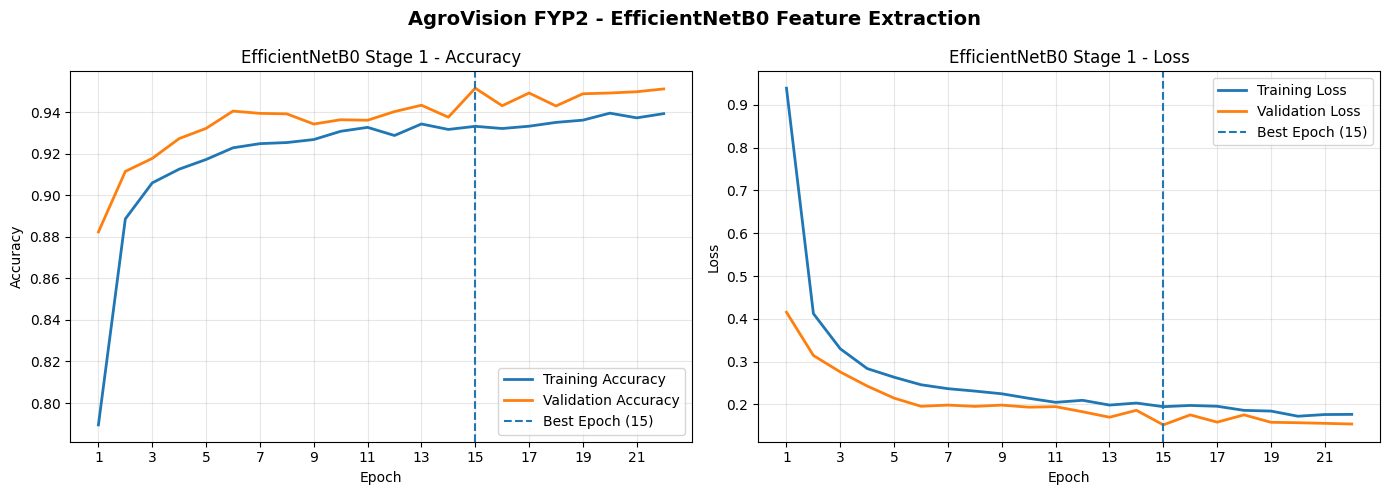


Training summary:
Epochs completed     : 22
Best epoch           : 15
Best validation loss : 0.152388
Best validation acc. : 0.951686

Training curves saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage1/training_curves.png

PASS: EfficientNetB0 Stage 1 curves saved.


In [16]:
# ============================================================
# PHASE 4.32: EFFICIENTNETB0 STAGE 1 TRAINING CURVES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CURVES")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load saved training history
# ------------------------------------------------------------

assert efficientnetb0_stage1_history_path.is_file()

history_df = pd.read_csv(
    efficientnetb0_stage1_history_path
)

required_columns = {
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
}

assert required_columns.issubset(history_df.columns)

epochs = np.arange(1, len(history_df) + 1)

# ------------------------------------------------------------
# 2. Identify best validation epoch
# ------------------------------------------------------------

best_epoch_idx = int(
    history_df["val_loss"].idxmin()
)

best_epoch = best_epoch_idx + 1

best_val_loss = float(
    history_df.loc[best_epoch_idx, "val_loss"]
)

best_val_accuracy = float(
    history_df.loc[best_epoch_idx, "val_accuracy"]
)

assert len(history_df) == 22
assert best_epoch == 15

# ------------------------------------------------------------
# 3. Create training curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy
axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[0].set_title(
    "EfficientNetB0 Stage 1 - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[1].set_title(
    "EfficientNetB0 Stage 1 - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(epochs[::2])

fig.suptitle(
    "AgroVision FYP2 - EfficientNetB0 Feature Extraction",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save curves to Google Drive
# ------------------------------------------------------------

fig.savefig(
    efficientnetb0_stage1_curves_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Verify and report
# ------------------------------------------------------------

assert efficientnetb0_stage1_curves_path.is_file()

print("\nTraining summary:")
print(f"Epochs completed     : {len(history_df)}")
print(f"Best epoch           : {best_epoch}")
print(f"Best validation loss : {best_val_loss:.6f}")
print(f"Best validation acc. : {best_val_accuracy:.6f}")

print("\nTraining curves saved to:")
print(efficientnetb0_stage1_curves_path)

print("\nPASS: EfficientNetB0 Stage 1 curves saved.")
print("=" * 60)

In [17]:
# ============================================================
# PHASE 4.33: EFFICIENTNETB0 STAGE 1 CHECKPOINT VERIFICATION
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify saved experiment files
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage1_history_path.is_file()
assert "val_ds" in globals()

# ------------------------------------------------------------
# 2. Reload best Stage 1 checkpoint
# ------------------------------------------------------------

efficientnetb0_stage1_best_model = (
    tf.keras.models.load_model(
        str(efficientnetb0_stage1_checkpoint),
        compile=False,
        safe_mode=True
    )
)

# ------------------------------------------------------------
# 3. Verify model architecture
# ------------------------------------------------------------

assert efficientnetb0_stage1_best_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_stage1_best_model.output_shape == (
    None, 38
)

assert (
    efficientnetb0_stage1_best_model.count_params()
    == 4098249
)

print("\nCheckpoint loaded successfully.")
print("Model:", efficientnetb0_stage1_best_model.name)

# ------------------------------------------------------------
# 4. Compile model for validation evaluation
# ------------------------------------------------------------

efficientnetb0_stage1_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Load original training history
# ------------------------------------------------------------

stage1_history_df = pd.read_csv(
    efficientnetb0_stage1_history_path
)

assert {
    "val_loss",
    "val_accuracy"
}.issubset(stage1_history_df.columns)

best_idx = int(
    stage1_history_df["val_loss"].idxmin()
)

best_epoch = best_idx + 1

recorded_loss = float(
    stage1_history_df.loc[best_idx, "val_loss"]
)

recorded_accuracy = float(
    stage1_history_df.loc[best_idx, "val_accuracy"]
)

# ------------------------------------------------------------
# 6. Evaluate saved checkpoint
# ------------------------------------------------------------

print("\nEvaluating checkpoint on 8,155 validation images...")

efficientnetb0_stage1_validation_results = (
    efficientnetb0_stage1_best_model.evaluate(
        val_ds,
        verbose=1,
        return_dict=True
    )
)

evaluated_loss = float(
    efficientnetb0_stage1_validation_results["loss"]
)

evaluated_accuracy = float(
    efficientnetb0_stage1_validation_results["accuracy"]
)

# ------------------------------------------------------------
# 7. Compare recorded and evaluated results
# ------------------------------------------------------------

loss_difference = abs(
    recorded_loss - evaluated_loss
)

accuracy_difference = abs(
    recorded_accuracy - evaluated_accuracy
)

print("\nBest checkpoint epoch:", best_epoch)

print("\nValidation comparison:")
print(f"Recorded loss       : {recorded_loss:.6f}")
print(f"Evaluated loss      : {evaluated_loss:.6f}")
print(f"Recorded accuracy   : {recorded_accuracy:.6f}")
print(f"Evaluated accuracy  : {evaluated_accuracy:.6f}")

print("\nAbsolute differences:")
print(f"Loss difference     : {loss_difference:.8f}")
print(f"Accuracy difference : {accuracy_difference:.8f}")

# ------------------------------------------------------------
# 8. Final checkpoint verification
# ------------------------------------------------------------

assert best_epoch == 15

assert np.isclose(
    recorded_loss,
    evaluated_loss,
    rtol=0,
    atol=1e-4
), "Checkpoint validation loss does not match history."

assert np.isclose(
    recorded_accuracy,
    evaluated_accuracy,
    rtol=0,
    atol=1e-4
), "Checkpoint validation accuracy does not match history."

print(
    "\nPASS: EfficientNetB0 Stage 1 checkpoint "
    "reproduces recorded validation results."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 VERIFICATION

Checkpoint loaded successfully.
Model: AgroVision_EfficientNetB0

Evaluating checkpoint on 8,155 validation images...
255/255 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.9517 - loss: 0.1524

Best checkpoint epoch: 15

Validation comparison:
Recorded loss       : 0.152388
Evaluated loss      : 0.152388
Recorded accuracy   : 0.951686
Evaluated accuracy  : 0.951686

Absolute differences:
Loss difference     : 0.00000000
Accuracy difference : 0.00000000

PASS: EfficientNetB0 Stage 1 checkpoint reproduces recorded validation results.


In [18]:
# ============================================================
# PHASE 4.34: INSPECT EFFICIENTNETB0 FINE-TUNING STRUCTURE
# ============================================================

import tensorflow as tf
import pandas as pd
import re

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 LAYER INSPECTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Retrieve backbone from verified Stage 1 checkpoint
# ------------------------------------------------------------

efficientnetb0_inspection_backbone = (
    efficientnetb0_stage1_best_model.get_layer(
        "efficientnetb0"
    )
)

assert efficientnetb0_inspection_backbone.count_params() == 4049571

# ------------------------------------------------------------
# 2. Classify layers by EfficientNet block
# ------------------------------------------------------------

def identify_efficientnet_region(layer_name):

    match = re.match(
        r"^(block[1-7])[a-z]_",
        layer_name
    )

    if match:
        return match.group(1)

    if layer_name.startswith("top_"):
        return "top"

    return "stem_or_preprocessing"


layer_records = []

for index, layer in enumerate(
    efficientnetb0_inspection_backbone.layers
):

    layer_records.append({
        "index": index,
        "name": layer.name,
        "type": layer.__class__.__name__,
        "region": identify_efficientnet_region(
            layer.name
        ),
        "parameters": layer.count_params(),
        "trainable": layer.trainable
    })

layer_inventory = pd.DataFrame(layer_records)

# ------------------------------------------------------------
# 3. Summarise the block structure
# ------------------------------------------------------------

block_summary = (
    layer_inventory
    .groupby("region", sort=False)
    .agg(
        layers=("name", "count"),
        parameters=("parameters", "sum")
    )
    .reset_index()
)

print("\nBackbone regions:")
print(block_summary.to_string(index=False))

# ------------------------------------------------------------
# 4. Inspect final backbone layers
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("FINAL 45 BACKBONE LAYERS")
print("-" * 60)

print(
    layer_inventory[
        ["index", "name", "type", "region", "parameters"]
    ].tail(45).to_string(index=False)
)

# ------------------------------------------------------------
# 5. Inspect candidate fine-tuning layers
# ------------------------------------------------------------

candidate_regions = {
    "block6",
    "block7",
    "top"
}

candidate_layers = [
    layer
    for layer in efficientnetb0_inspection_backbone.layers
    if identify_efficientnet_region(
        layer.name
    ) in candidate_regions
]

candidate_weight_layers = [
    layer
    for layer in candidate_layers
    if isinstance(
        layer,
        (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D
        )
    )
]

candidate_bn_layers = [
    layer
    for layer in candidate_layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

candidate_conv_params = sum(
    layer.count_params()
    for layer in candidate_weight_layers
)

# ------------------------------------------------------------
# 6. Verify inspection
# ------------------------------------------------------------

all_bn_layers = [
    layer
    for layer in efficientnetb0_inspection_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert len(all_bn_layers) == 49
assert len(candidate_weight_layers) > 0
assert len(candidate_bn_layers) > 0

assert len(
    efficientnetb0_inspection_backbone.trainable_weights
) == 0

# ------------------------------------------------------------
# 7. Report candidate selection
# ------------------------------------------------------------

print("\n" + "-" * 60)
print("PROPOSED FINE-TUNING REGIONS")
print("-" * 60)

print("Candidate regions       : block6, block7, top")
print("Candidate conv layers   :", len(candidate_weight_layers))
print("Candidate BatchNorm     :", len(candidate_bn_layers))
print(f"Candidate conv params   : {candidate_conv_params:,}")
print("Total backbone BN layers:", len(all_bn_layers))

print("\nCandidate convolutional layers:")

for layer in candidate_weight_layers:
    print(
        f"  {layer.name:<38}"
        f"{layer.__class__.__name__}"
    )

print("\nNo trainability settings were changed.")

print("\nPASS: EfficientNetB0 layer inspection completed.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 LAYER INSPECTION

Backbone regions:
               region  layers  parameters
stem_or_preprocessing       8         999
               block1      10        1544
               block2      29       17770
               block3      29       48336
               block4      44      248210
               block5      43      551116
               block6      59     2044396
               block7      13      722480
                  top       3      414720

------------------------------------------------------------
FINAL 45 BACKBONE LAYERS
------------------------------------------------------------
 index                      name                   type region  parameters
   193         block6c_expand_bn     BatchNormalization block6        4608
   194 block6c_expand_activation             Activation block6           0
   195            block6c_dwconv        DepthwiseConv2D block6       28800
   196                block6c_bn     BatchNormalization block6 

In [19]:
# ============================================================
# PHASE 4.35: EFFICIENTNETB0 STAGE 2 LAYER CONFIGURATION
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 SETUP")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify best Stage 1 checkpoint
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file()

assert efficientnetb0_stage1_best_epoch == 15

# ------------------------------------------------------------
# 2. Reload best Stage 1 model
# ------------------------------------------------------------

efficientnetb0_stage2_model = (
    tf.keras.models.load_model(
        str(efficientnetb0_stage1_checkpoint),
        compile=False,
        safe_mode=True
    )
)

efficientnetb0_stage2_backbone = (
    efficientnetb0_stage2_model.get_layer(
        "efficientnetb0"
    )
)

assert efficientnetb0_stage2_model.count_params() == 4098249

print("\nBest Stage 1 checkpoint restored.")
print("Model:", efficientnetb0_stage2_model.name)

# ------------------------------------------------------------
# 3. Define selected fine-tuning regions
# ------------------------------------------------------------

FINE_TUNING_REGIONS = {
    "block6",
    "block7",
    "top"
}

CONV_LAYER_TYPES = (
    tf.keras.layers.Conv2D,
    tf.keras.layers.DepthwiseConv2D
)

# ------------------------------------------------------------
# 4. Enable selective backbone fine-tuning
# ------------------------------------------------------------

# The parent backbone must be trainable so selected
# child-layer weights can appear in trainable_weights.

efficientnetb0_stage2_backbone.trainable = True

for layer in efficientnetb0_stage2_backbone.layers:

    region = identify_efficientnet_region(
        layer.name
    )

    selected_region = (
        region in FINE_TUNING_REGIONS
    )

    is_convolution = isinstance(
        layer,
        CONV_LAYER_TYPES
    )

    # Train only selected convolutional layers.
    # All BatchNormalization layers remain frozen.
    layer.trainable = (
        selected_region and is_convolution
    )

# ------------------------------------------------------------
# 5. Inspect trainable convolutional layers
# ------------------------------------------------------------

stage2_trainable_conv_layers = [
    layer
    for layer in efficientnetb0_stage2_backbone.layers
    if layer.trainable
    and isinstance(layer, CONV_LAYER_TYPES)
]

stage2_frozen_bn_layers = [
    layer
    for layer in efficientnetb0_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

# ------------------------------------------------------------
# 6. Calculate parameter counts
# ------------------------------------------------------------

def count_weight_parameters(weights):

    return sum(
        int(np.prod(weight.shape))
        for weight in weights
    )


stage2_backbone_trainable_params = (
    count_weight_parameters(
        efficientnetb0_stage2_backbone.trainable_weights
    )
)

stage2_total_trainable_params = (
    count_weight_parameters(
        efficientnetb0_stage2_model.trainable_weights
    )
)

stage2_total_params = (
    efficientnetb0_stage2_model.count_params()
)

stage2_non_trainable_params = (
    stage2_total_params - stage2_total_trainable_params
)

# ------------------------------------------------------------
# 7. Verify fine-tuning configuration
# ------------------------------------------------------------

assert len(stage2_trainable_conv_layers) == 26

assert len(stage2_frozen_bn_layers) == 49

assert all(
    not layer.trainable
    for layer in stage2_frozen_bn_layers
)

assert all(
    identify_efficientnet_region(layer.name)
    in FINE_TUNING_REGIONS
    for layer in stage2_trainable_conv_layers
)

assert stage2_backbone_trainable_params == 3129884

assert stage2_total_trainable_params == 3178562

assert stage2_total_params == 4098249

assert efficientnetb0_stage2_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_stage2_model.output_shape == (
    None, NUM_CLASSES
)

# ------------------------------------------------------------
# 8. Display fine-tuning summary
# ------------------------------------------------------------

print("\nFine-tuning configuration:")
print("Selected regions       :", sorted(FINE_TUNING_REGIONS))
print("Trainable conv layers  :", len(stage2_trainable_conv_layers))
print("Frozen BatchNorm layers:", len(stage2_frozen_bn_layers))

print("\nParameter summary:")
print(f"Total parameters       : {stage2_total_params:,}")
print(f"Trainable parameters   : {stage2_total_trainable_params:,}")
print(f"Non-trainable params   : {stage2_non_trainable_params:,}")
print(f"Trainable backbone     : {stage2_backbone_trainable_params:,}")

print("\nTrainable convolutional layers:")

for layer in stage2_trainable_conv_layers:
    print(
        f"  {layer.name:<38}"
        f"{layer.__class__.__name__}"
    )

print("\nStage 1 checkpoint remains unchanged.")
print("No training has been performed.")

print(
    "\nPASS: EfficientNetB0 Stage 2 trainable layers configured."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 SETUP

Best Stage 1 checkpoint restored.
Model: AgroVision_EfficientNetB0

Fine-tuning configuration:
Selected regions       : ['block6', 'block7', 'top']
Trainable conv layers  : 26
Frozen BatchNorm layers: 49

Parameter summary:
Total parameters       : 4,098,249
Trainable parameters   : 3,178,562
Non-trainable params   : 919,687
Trainable backbone     : 3,129,884

Trainable convolutional layers:
  block6a_expand_conv                   Conv2D
  block6a_dwconv                        DepthwiseConv2D
  block6a_se_reduce                     Conv2D
  block6a_se_expand                     Conv2D
  block6a_project_conv                  Conv2D
  block6b_expand_conv                   Conv2D
  block6b_dwconv                        DepthwiseConv2D
  block6b_se_reduce                     Conv2D
  block6b_se_expand                     Conv2D
  block6b_project_conv                  Conv2D
  block6c_expand_conv                   Conv2D
  block6c_dwconv      

In [20]:
# ============================================================
# PHASE 4.36: COMPILE EFFICIENTNETB0 STAGE 2
# ============================================================

import tensorflow as tf
import numpy as np

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 COMPILATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore fine-tuning configuration
# ------------------------------------------------------------

FINE_TUNING_LEARNING_RATE = 1e-5
FINE_TUNING_EPOCHS = 50

# ------------------------------------------------------------
# 2. Verify selective fine-tuning configuration
# ------------------------------------------------------------

assert efficientnetb0_stage2_backbone.trainable is True

assert len(stage2_trainable_conv_layers) == 26

assert all(
    not layer.trainable
    for layer in efficientnetb0_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

assert stage2_backbone_trainable_params == 3129884
assert stage2_total_trainable_params == 3178562

# ------------------------------------------------------------
# 3. Create a fresh Adam optimiser
# ------------------------------------------------------------

efficientnetb0_stage2_optimizer = (
    tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNING_LEARNING_RATE
    )
)

# ------------------------------------------------------------
# 4. Compile Stage 2 model
# ------------------------------------------------------------

efficientnetb0_stage2_model.compile(
    optimizer=efficientnetb0_stage2_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 5. Verify optimiser configuration
# ------------------------------------------------------------

actual_lr = float(
    efficientnetb0_stage2_model.optimizer.learning_rate.numpy()
)

optimizer_steps = int(
    efficientnetb0_stage2_model.optimizer.iterations.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE,
    rtol=0,
    atol=1e-10
)

assert optimizer_steps == 0, (
    "Stage 2 optimiser has already performed updates."
)

# ------------------------------------------------------------
# 6. Recheck trainable parameter count
# ------------------------------------------------------------

actual_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in efficientnetb0_stage2_model.trainable_weights
)

assert actual_trainable_params == 3178562

# ------------------------------------------------------------
# 7. Verify input and output configuration
# ------------------------------------------------------------

assert efficientnetb0_stage2_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_stage2_model.output_shape == (
    None, NUM_CLASSES
)

assert len(class_weights) == NUM_CLASSES

# ------------------------------------------------------------
# 8. Display compilation summary
# ------------------------------------------------------------

print("\nModel configuration:")
print("Architecture       :", efficientnetb0_stage2_model.name)
print("Training stage     : Stage 2 - Selective Fine-Tuning")
print("Fine-tuning regions: block6, block7, top")
print("Backbone trainable :", efficientnetb0_stage2_backbone.trainable)
print("BatchNorm frozen   : Yes")

print("\nOptimisation:")
print("Optimiser          : Adam (fresh instance)")
print(f"Learning rate      : {actual_lr:.8f}")
print("Loss function      : SparseCategoricalCrossentropy")
print("Evaluation metric  : SparseCategoricalAccuracy")
print("Optimiser steps    :", optimizer_steps)

print("\nModel parameters:")
print(f"Total parameters   : {stage2_total_params:,}")
print(f"Trainable params   : {actual_trainable_params:,}")
print(f"Frozen parameters  : {stage2_non_trainable_params:,}")

print("\nTraining configuration:")
print(f"Maximum epochs     : {FINE_TUNING_EPOCHS}")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Class weights      : {len(class_weights)}")

print(
    "\nPASS: EfficientNetB0 Stage 2 compiled successfully."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 COMPILATION

Model configuration:
Architecture       : AgroVision_EfficientNetB0
Training stage     : Stage 2 - Selective Fine-Tuning
Fine-tuning regions: block6, block7, top
Backbone trainable : True
BatchNorm frozen   : Yes

Optimisation:
Optimiser          : Adam (fresh instance)
Learning rate      : 0.00001000
Loss function      : SparseCategoricalCrossentropy
Evaluation metric  : SparseCategoricalAccuracy
Optimiser steps    : 0

Model parameters:
Total parameters   : 4,098,249
Trainable params   : 3,178,562
Frozen parameters  : 919,687

Training configuration:
Maximum epochs     : 50
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Class weights      : 38

PASS: EfficientNetB0 Stage 2 compiled successfully.


In [21]:
# ============================================================
# PHASE 4.37: EFFICIENTNETB0 STAGE 2 CALLBACK CONFIGURATION
# ============================================================

import tensorflow as tf
import numpy as np
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CALLBACKS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify original callback settings
# ------------------------------------------------------------

MONITOR_METRIC = "val_loss"

EARLY_STOPPING_PATIENCE = 7
EARLY_STOPPING_MIN_DELTA = 0.001

LR_REDUCTION_PATIENCE = 3
LR_REDUCTION_FACTOR = 0.5

MIN_LEARNING_RATE = 1e-7

# ------------------------------------------------------------
# 2. Create Stage 2 experiment directory
# ------------------------------------------------------------

EFFICIENTNETB0_STAGE2_DIR = (
    EFFICIENTNETB0_DIR / "stage2"
)

EFFICIENTNETB0_STAGE2_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Define Stage 2 output paths
# ------------------------------------------------------------

efficientnetb0_stage2_checkpoint = (
    EFFICIENTNETB0_STAGE2_DIR / "best_model.keras"
)

efficientnetb0_stage2_history_path = (
    EFFICIENTNETB0_STAGE2_DIR / "training_history.csv"
)

efficientnetb0_stage2_log_path = (
    EFFICIENTNETB0_STAGE2_DIR / "epoch_log.csv"
)

efficientnetb0_stage2_curves_path = (
    EFFICIENTNETB0_STAGE2_DIR / "training_curves.png"
)

# ------------------------------------------------------------
# 4. Prevent accidental overwriting
# ------------------------------------------------------------

stage2_output_paths = [
    efficientnetb0_stage2_checkpoint,
    efficientnetb0_stage2_history_path,
    efficientnetb0_stage2_log_path,
    efficientnetb0_stage2_curves_path
]

existing_stage2_outputs = [
    path
    for path in stage2_output_paths
    if path.exists()
]

assert not existing_stage2_outputs, (
    "Existing EfficientNetB0 Stage 2 outputs detected: "
    + ", ".join(
        str(path)
        for path in existing_stage2_outputs
    )
)

# ------------------------------------------------------------
# 5. Configure Stage 2 callbacks
# ------------------------------------------------------------

efficientnetb0_stage2_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(efficientnetb0_stage2_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(efficientnetb0_stage2_log_path),
        append=False
    )
]

# ------------------------------------------------------------
# 6. Verify Stage 2 configuration
# ------------------------------------------------------------

assert len(efficientnetb0_stage2_callbacks) == 4

assert EFFICIENTNETB0_STAGE2_DIR.is_dir()

assert (
    efficientnetb0_stage2_checkpoint
    != efficientnetb0_stage1_checkpoint
)

assert efficientnetb0_stage1_checkpoint.is_file()

assert efficientnetb0_stage2_backbone.trainable is True

assert np.isclose(
    float(
        efficientnetb0_stage2_model.optimizer.learning_rate.numpy()
    ),
    FINE_TUNING_LEARNING_RATE,
    rtol=0,
    atol=1e-10
)

assert int(
    efficientnetb0_stage2_model.optimizer.iterations.numpy()
) == 0

# ------------------------------------------------------------
# 7. Display callback summary
# ------------------------------------------------------------

print("\nStage 2 experiment directory:")
print(EFFICIENTNETB0_STAGE2_DIR)

print("\nOutput files:")
print("Best checkpoint :", efficientnetb0_stage2_checkpoint)
print("Training history:", efficientnetb0_stage2_history_path)
print("Epoch log       :", efficientnetb0_stage2_log_path)
print("Training curves :", efficientnetb0_stage2_curves_path)

print("\nConfigured callbacks:")

for callback in efficientnetb0_stage2_callbacks:
    print(f"  - {callback.__class__.__name__}")

print("\nCallback settings:")
print(f"Monitoring metric        : {MONITOR_METRIC}")
print(f"Early stopping patience  : {EARLY_STOPPING_PATIENCE}")
print(f"Early stopping min delta : {EARLY_STOPPING_MIN_DELTA}")
print(f"LR reduction patience    : {LR_REDUCTION_PATIENCE}")
print(f"LR reduction factor      : {LR_REDUCTION_FACTOR}")
print(f"Minimum learning rate    : {MIN_LEARNING_RATE}")

print("\nFine-tuning configuration:")
print(f"Maximum epochs          : {FINE_TUNING_EPOCHS}")
print(f"Initial learning rate   : {FINE_TUNING_LEARNING_RATE}")
print("Fine-tuning regions     : block6, block7, top")
print("BatchNormalization      : Frozen")

print("\nStage 1 checkpoint remains preserved.")

print(
    "\nPASS: EfficientNetB0 Stage 2 callbacks configured."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CALLBACKS

Stage 2 experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2

Output files:
Best checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras
Training history: /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/training_history.csv
Epoch log       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/epoch_log.csv
Training curves : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/training_curves.png

Configured callbacks:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger

Callback settings:
Monitoring metric        : val_loss
Early stopping patience  : 7
Early stopping min delta : 0.001
LR reduction patience    : 3
LR reduction factor      : 0.5
Minimum learning rate    : 1e-07

Fine-tuning configuration:
Maximum epochs          : 50

In [22]:
# ============================================================
# PHASE 4.38: EFFICIENTNETB0 STAGE 2 PRE-TRAINING CHECK
# ============================================================

import tensorflow as tf
import numpy as np
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 READINESS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify GPU availability
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")

assert len(gpus) > 0, (
    "No GPU detected. Do not start Stage 2 training on CPU."
)

print("\nGPU verification:")
for gpu in gpus:
    print("Detected:", gpu)

# ------------------------------------------------------------
# 2. Verify dataset pipelines
# ------------------------------------------------------------

assert "train_ds" in globals()
assert "val_ds" in globals()

training_batches = int(
    tf.data.experimental.cardinality(train_ds).numpy()
)

validation_batches = int(
    tf.data.experimental.cardinality(val_ds).numpy()
)

assert len(train_data) == 37978
assert len(val_data) == 8155

assert training_batches == 1187
assert validation_batches == 255

print("\nDataset verification:")
print(f"Training images    : {len(train_data):,}")
print(f"Validation images  : {len(val_data):,}")
print(f"Training batches   : {training_batches}")
print(f"Validation batches : {validation_batches}")

# ------------------------------------------------------------
# 3. Verify class weights
# ------------------------------------------------------------

assert len(class_weights) == NUM_CLASSES

assert set(class_weights.keys()) == set(
    range(NUM_CLASSES)
)

assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

print("\nClass weights:")
print("Classes with weights :", len(class_weights))
print("All weights valid    : Yes")

# ------------------------------------------------------------
# 4. Verify Stage 2 fine-tuning configuration
# ------------------------------------------------------------

assert efficientnetb0_stage2_backbone.trainable is True

trainable_conv_layers = [
    layer
    for layer in efficientnetb0_stage2_backbone.layers
    if layer.trainable
    and isinstance(
        layer,
        (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D
        )
    )
]

bn_layers = [
    layer
    for layer in efficientnetb0_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert len(trainable_conv_layers) == 26
assert len(bn_layers) == 49

assert all(
    not layer.trainable
    for layer in bn_layers
)

assert all(
    identify_efficientnet_region(layer.name)
    in {"block6", "block7", "top"}
    for layer in trainable_conv_layers
)

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in efficientnetb0_stage2_model.trainable_weights
)

assert trainable_params == 3178562

print("\nFine-tuning verification:")
print("Trainable conv layers :", len(trainable_conv_layers))
print("Frozen BatchNorm      :", len(bn_layers))
print(f"Trainable parameters  : {trainable_params:,}")

# ------------------------------------------------------------
# 5. Verify optimiser
# ------------------------------------------------------------

assert efficientnetb0_stage2_model.optimizer is not None

actual_lr = float(
    efficientnetb0_stage2_model.optimizer.learning_rate.numpy()
)

optimizer_steps = int(
    efficientnetb0_stage2_model.optimizer.iterations.numpy()
)

assert np.isclose(
    actual_lr,
    FINE_TUNING_LEARNING_RATE,
    rtol=0,
    atol=1e-10
)

assert optimizer_steps == 0, (
    "Stage 2 training may have already started."
)

print("\nOptimiser verification:")
print("Optimiser       : Adam")
print(f"Learning rate   : {actual_lr:.8f}")
print(f"Optimiser steps : {optimizer_steps}")

# ------------------------------------------------------------
# 6. Verify callbacks
# ------------------------------------------------------------

callback_types = [
    type(callback).__name__
    for callback in efficientnetb0_stage2_callbacks
]

expected_callbacks = [
    "ModelCheckpoint",
    "EarlyStopping",
    "ReduceLROnPlateau",
    "CSVLogger"
]

assert callback_types == expected_callbacks

print("\nCallback verification:")

for callback_name in callback_types:
    print("-", callback_name)

# ------------------------------------------------------------
# 7. Verify saved Stage 1 checkpoint
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage1_history_path.is_file()
assert efficientnetb0_stage1_curves_path.is_file()

print("\nStage 1 preservation:")
print("Best checkpoint : Available")
print("Training history: Available")
print("Training curves : Available")

# ------------------------------------------------------------
# 8. Verify Stage 2 output safety
# ------------------------------------------------------------

assert EFFICIENTNETB0_STAGE2_DIR.is_dir()

stage2_output_files = [
    efficientnetb0_stage2_checkpoint,
    efficientnetb0_stage2_history_path,
    efficientnetb0_stage2_log_path,
    efficientnetb0_stage2_curves_path
]

existing_outputs = [
    path
    for path in stage2_output_files
    if path.exists()
]

assert not existing_outputs, (
    "Existing Stage 2 files detected. "
    "Inspect them before starting training: "
    + ", ".join(str(path) for path in existing_outputs)
)

# Verify Google Drive write access
write_test_path = (
    EFFICIENTNETB0_STAGE2_DIR / "_write_test.tmp"
)

try:
    write_test_path.write_text(
        "AgroVision EfficientNetB0 Stage 2 write test",
        encoding="utf-8"
    )

    assert write_test_path.is_file()

finally:
    write_test_path.unlink(missing_ok=True)

print("\nStorage verification:")
print("Stage 2 directory :", EFFICIENTNETB0_STAGE2_DIR)
print("Write access      : Confirmed")
print("Existing outputs  : None")

# ------------------------------------------------------------
# 9. Final readiness status
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 STAGE 2 READY FOR TRAINING")
print("=" * 60)

print("\nConfiguration:")
print("Maximum epochs       :", FINE_TUNING_EPOCHS)
print("Batch size           :", BATCH_SIZE)
print("Initial learning rate:", FINE_TUNING_LEARNING_RATE)
print("Class weighting      : Enabled")
print("Validation monitoring: val_loss")
print("Best checkpoint      : Google Drive")

print("\nNo training has been performed in this cell.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 READINESS

GPU verification:
Detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Dataset verification:
Training images    : 37,978
Validation images  : 8,155
Training batches   : 1187
Validation batches : 255

Class weights:
Classes with weights : 38
All weights valid    : Yes

Fine-tuning verification:
Trainable conv layers : 26
Frozen BatchNorm      : 49
Trainable parameters  : 3,178,562

Optimiser verification:
Optimiser       : Adam
Learning rate   : 0.00001000
Optimiser steps : 0

Callback verification:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Stage 1 preservation:
Best checkpoint : Available
Training history: Available
Training curves : Available

Storage verification:
Stage 2 directory : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2
Write access      : Confirmed
Existing outputs  : None

PASS: EFFICIENTNETB0 STAGE 2 READY FOR TRAINING

Configuration:
Maximu

In [23]:
# ============================================================
# PHASE 4.39: EFFICIENTNETB0 STAGE 2 - SELECTIVE FINE-TUNING
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. Prevent accidental overwriting
# ------------------------------------------------------------

training_outputs = [
    efficientnetb0_stage2_checkpoint,
    efficientnetb0_stage2_history_path,
    efficientnetb0_stage2_log_path,
    efficientnetb0_stage2_curves_path
]

assert not any(
    path.exists() for path in training_outputs
), (
    "Existing EfficientNetB0 Stage 2 outputs detected. "
    "Review them before starting another training run."
)

# ------------------------------------------------------------
# 2. Verify training configuration
# ------------------------------------------------------------

assert efficientnetb0_stage2_backbone.trainable is True

assert len(stage2_trainable_conv_layers) == 26

assert all(
    not layer.trainable
    for layer in efficientnetb0_stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

assert np.isclose(
    float(
        efficientnetb0_stage2_model.optimizer.learning_rate.numpy()
    ),
    FINE_TUNING_LEARNING_RATE,
    rtol=0,
    atol=1e-10
)

assert int(
    efficientnetb0_stage2_model.optimizer.iterations.numpy()
) == 0

assert len(class_weights) == NUM_CLASSES

assert len(train_data) == 37978
assert len(val_data) == 8155

assert len(
    tf.config.list_physical_devices("GPU")
) > 0, "GPU not detected."

assert efficientnetb0_stage1_checkpoint.is_file()

# ------------------------------------------------------------
# 3. Display training configuration
# ------------------------------------------------------------

print("\nTraining configuration:")

print(f"Architecture       : {efficientnetb0_stage2_model.name}")
print("Training stage     : Stage 2 - Selective Fine-Tuning")
print("Fine-tuning regions: block6, block7, top")
print(f"Trainable params   : {stage2_total_trainable_params:,}")
print(f"Training samples   : {len(train_data):,}")
print(f"Validation samples : {len(val_data):,}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Maximum epochs     : {FINE_TUNING_EPOCHS}")
print(f"Initial LR         : {FINE_TUNING_LEARNING_RATE}")
print(f"Class weights      : {len(class_weights)}")
print(f"Checkpoint         : {efficientnetb0_stage2_checkpoint}")

print("\nStarting EfficientNetB0 Stage 2 fine-tuning...\n")

# ------------------------------------------------------------
# 4. Record training start time
# ------------------------------------------------------------

efficientnetb0_stage2_start = time.time()

# ------------------------------------------------------------
# 5. Fine-tune selected pretrained layers
# ------------------------------------------------------------

efficientnetb0_stage2_history = (
    efficientnetb0_stage2_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNING_EPOCHS,
        class_weight=class_weights,
        callbacks=efficientnetb0_stage2_callbacks,
        verbose=1
    )
)

# ------------------------------------------------------------
# 6. Calculate training duration
# ------------------------------------------------------------

efficientnetb0_stage2_duration = (
    time.time() - efficientnetb0_stage2_start
)

# ------------------------------------------------------------
# 7. Save complete training history
# ------------------------------------------------------------

efficientnetb0_stage2_history_df = pd.DataFrame(
    efficientnetb0_stage2_history.history
)

efficientnetb0_stage2_history_df.to_csv(
    efficientnetb0_stage2_history_path,
    index=False
)

# ------------------------------------------------------------
# 8. Identify best epoch by validation loss
# ------------------------------------------------------------

best_epoch_index = int(
    efficientnetb0_stage2_history_df["val_loss"].idxmin()
)

efficientnetb0_stage2_best_epoch = best_epoch_index + 1

efficientnetb0_stage2_best_val_loss = float(
    efficientnetb0_stage2_history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

efficientnetb0_stage2_best_val_accuracy = float(
    efficientnetb0_stage2_history_df.loc[
        best_epoch_index,
        "val_accuracy"
    ]
)

# ------------------------------------------------------------
# 9. Verify saved outputs
# ------------------------------------------------------------

assert efficientnetb0_stage2_checkpoint.is_file(), (
    "Best Stage 2 checkpoint was not saved."
)

assert efficientnetb0_stage2_history_path.is_file(), (
    "Stage 2 training history was not saved."
)

assert efficientnetb0_stage2_log_path.is_file(), (
    "Stage 2 epoch log was not saved."
)

assert len(efficientnetb0_stage2_history_df) > 0

assert (
    len(efficientnetb0_stage2_history_df)
    <= FINE_TUNING_EPOCHS
)

# ------------------------------------------------------------
# 10. Display final training results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EFFICIENTNETB0 STAGE 2 TRAINING COMPLETED")
print("=" * 60)

print("\nTraining summary:")

print(
    f"Epochs completed    : "
    f"{len(efficientnetb0_stage2_history.epoch)}"
)

print(
    f"Training duration   : "
    f"{efficientnetb0_stage2_duration / 60:.2f} minutes"
)

print(
    f"Best epoch          : "
    f"{efficientnetb0_stage2_best_epoch}"
)

print(
    f"Best validation loss: "
    f"{efficientnetb0_stage2_best_val_loss:.6f}"
)

print(
    f"Best validation acc.: "
    f"{efficientnetb0_stage2_best_val_accuracy:.6f}"
)

print("\nSaved outputs:")
print("Checkpoint :", efficientnetb0_stage2_checkpoint)
print("History    :", efficientnetb0_stage2_history_path)
print("Epoch log  :", efficientnetb0_stage2_log_path)

print(
    "\nPASS: EfficientNetB0 Stage 2 training completed."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 TRAINING

Training configuration:
Architecture       : AgroVision_EfficientNetB0
Training stage     : Stage 2 - Selective Fine-Tuning
Fine-tuning regions: block6, block7, top
Trainable params   : 3,178,562
Training samples   : 37,978
Validation samples : 8,155
Batch size         : 32
Maximum epochs     : 50
Initial LR         : 1e-05
Class weights      : 38
Checkpoint         : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras

Starting EfficientNetB0 Stage 2 fine-tuning...

Epoch 1/50
1186/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9457 - loss: 0.1646
Epoch 1: val_loss improved from None to 0.12894, saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 94s 70ms/step - accur

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CURVES


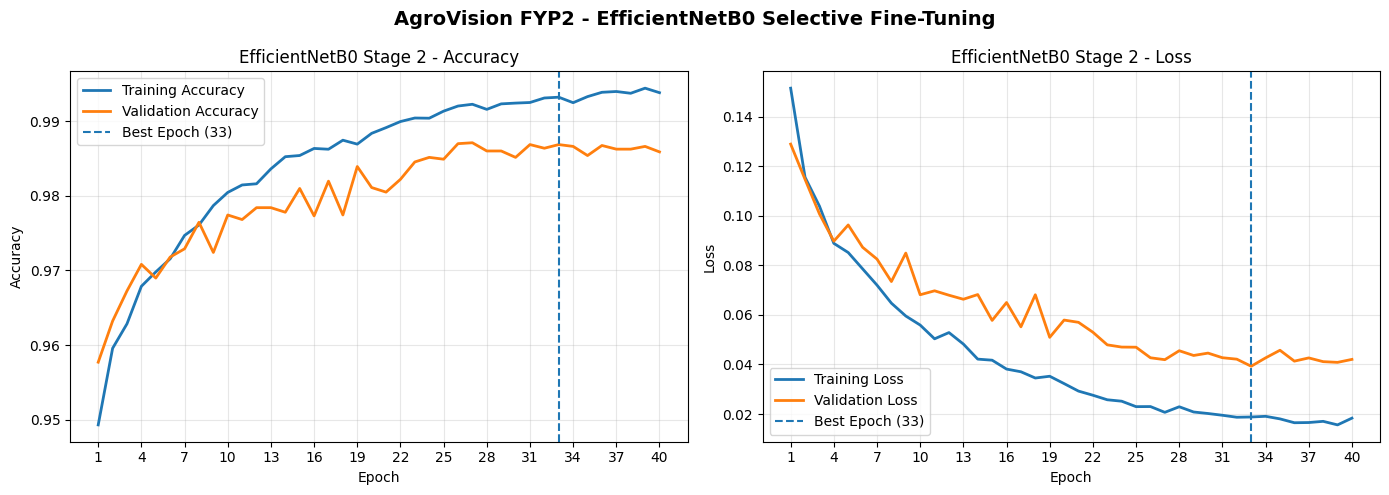


Training summary:
Epochs completed     : 40
Best epoch           : 33
Best validation loss : 0.039278
Best validation acc. : 0.986879

Training curves saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/training_curves.png

PASS: EfficientNetB0 Stage 2 curves saved.


In [24]:
# ============================================================
# PHASE 4.40: EFFICIENTNETB0 STAGE 2 TRAINING CURVES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CURVES")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load saved Stage 2 training history
# ------------------------------------------------------------

assert efficientnetb0_stage2_history_path.is_file()

history_df = pd.read_csv(
    efficientnetb0_stage2_history_path
)

required_columns = {
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
}

assert required_columns.issubset(history_df.columns)

assert len(history_df) == 40

epochs = np.arange(1, len(history_df) + 1)

# ------------------------------------------------------------
# 2. Identify best validation epoch
# ------------------------------------------------------------

best_epoch_idx = int(
    history_df["val_loss"].idxmin()
)

best_epoch = best_epoch_idx + 1

best_val_loss = float(
    history_df.loc[best_epoch_idx, "val_loss"]
)

best_val_accuracy = float(
    history_df.loc[best_epoch_idx, "val_accuracy"]
)

assert best_epoch == 33

# ------------------------------------------------------------
# 3. Create training and validation curves
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy graph
axes[0].plot(
    epochs,
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[0].set_title(
    "EfficientNetB0 Stage 2 - Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    epochs,
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

axes[1].set_title(
    "EfficientNetB0 Stage 2 - Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(
        np.arange(1, len(epochs) + 1, 3)
    )

fig.suptitle(
    "AgroVision FYP2 - EfficientNetB0 Selective Fine-Tuning",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save curves to Google Drive
# ------------------------------------------------------------

assert not efficientnetb0_stage2_curves_path.exists(), (
    "Stage 2 training curves already exist. "
    "Review the saved file before overwriting."
)

fig.savefig(
    efficientnetb0_stage2_curves_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Verify and report
# ------------------------------------------------------------

assert efficientnetb0_stage2_curves_path.is_file()

print("\nTraining summary:")
print(f"Epochs completed     : {len(history_df)}")
print(f"Best epoch           : {best_epoch}")
print(f"Best validation loss : {best_val_loss:.6f}")
print(f"Best validation acc. : {best_val_accuracy:.6f}")

print("\nTraining curves saved to:")
print(efficientnetb0_stage2_curves_path)

print("\nPASS: EfficientNetB0 Stage 2 curves saved.")
print("=" * 60)

In [25]:
# ============================================================
# PHASE 4.41: EFFICIENTNETB0 STAGE 2 CHECKPOINT VERIFICATION
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 VERIFICATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify saved files and validation pipeline
# ------------------------------------------------------------

assert efficientnetb0_stage2_checkpoint.is_file()
assert efficientnetb0_stage2_history_path.is_file()
assert "val_ds" in globals()

assert len(val_data) == 8155

# ------------------------------------------------------------
# 2. Reload best Stage 2 checkpoint
# ------------------------------------------------------------

efficientnetb0_stage2_best_model = (
    tf.keras.models.load_model(
        str(efficientnetb0_stage2_checkpoint),
        compile=False,
        safe_mode=True
    )
)

# ------------------------------------------------------------
# 3. Verify model architecture
# ------------------------------------------------------------

assert efficientnetb0_stage2_best_model.input_shape == (
    None, 160, 160, 3
)

assert efficientnetb0_stage2_best_model.output_shape == (
    None, 38
)

assert (
    efficientnetb0_stage2_best_model.count_params()
    == 4098249
)

print("\nCheckpoint loaded successfully.")
print("Model:", efficientnetb0_stage2_best_model.name)

# ------------------------------------------------------------
# 4. Verify fine-tuned backbone
# ------------------------------------------------------------

loaded_backbone = (
    efficientnetb0_stage2_best_model.get_layer(
        "efficientnetb0"
    )
)

loaded_bn_layers = [
    layer
    for layer in loaded_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
]

assert len(loaded_bn_layers) == 49

assert all(
    not layer.trainable
    for layer in loaded_bn_layers
)

print("\nBackbone verification:")
print("BatchNormalization layers:", len(loaded_bn_layers))
print("All BatchNorm frozen     : Yes")

# ------------------------------------------------------------
# 5. Compile for validation evaluation
# ------------------------------------------------------------

efficientnetb0_stage2_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# 6. Load recorded training history
# ------------------------------------------------------------

stage2_history_df = pd.read_csv(
    efficientnetb0_stage2_history_path
)

assert {
    "val_loss",
    "val_accuracy"
}.issubset(stage2_history_df.columns)

assert len(stage2_history_df) == 40

best_idx = int(
    stage2_history_df["val_loss"].idxmin()
)

best_epoch = best_idx + 1

recorded_loss = float(
    stage2_history_df.loc[best_idx, "val_loss"]
)

recorded_accuracy = float(
    stage2_history_df.loc[best_idx, "val_accuracy"]
)

# ------------------------------------------------------------
# 7. Evaluate the saved checkpoint
# ------------------------------------------------------------

print("\nEvaluating checkpoint on 8,155 validation images...")

efficientnetb0_stage2_validation_results = (
    efficientnetb0_stage2_best_model.evaluate(
        val_ds,
        verbose=1,
        return_dict=True
    )
)

evaluated_loss = float(
    efficientnetb0_stage2_validation_results["loss"]
)

evaluated_accuracy = float(
    efficientnetb0_stage2_validation_results["accuracy"]
)

# ------------------------------------------------------------
# 8. Compare recorded and evaluated results
# ------------------------------------------------------------

loss_difference = abs(
    recorded_loss - evaluated_loss
)

accuracy_difference = abs(
    recorded_accuracy - evaluated_accuracy
)

print("\nBest checkpoint epoch:", best_epoch)

print("\nValidation comparison:")
print(f"Recorded loss       : {recorded_loss:.6f}")
print(f"Evaluated loss      : {evaluated_loss:.6f}")
print(f"Recorded accuracy   : {recorded_accuracy:.6f}")
print(f"Evaluated accuracy  : {evaluated_accuracy:.6f}")

print("\nAbsolute differences:")
print(f"Loss difference     : {loss_difference:.8f}")
print(f"Accuracy difference : {accuracy_difference:.8f}")

# ------------------------------------------------------------
# 9. Final checkpoint verification
# ------------------------------------------------------------

assert best_epoch == 33, (
    "Unexpected best validation epoch."
)

assert np.isclose(
    recorded_loss,
    evaluated_loss,
    rtol=0,
    atol=1e-4
), "Checkpoint validation loss does not match history."

assert np.isclose(
    recorded_accuracy,
    evaluated_accuracy,
    rtol=0,
    atol=1e-4
), "Checkpoint validation accuracy does not match history."

print(
    "\nPASS: EfficientNetB0 Stage 2 checkpoint "
    "reproduces recorded validation results."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 VERIFICATION

Checkpoint loaded successfully.
Model: AgroVision_EfficientNetB0

Backbone verification:
BatchNormalization layers: 49
All BatchNorm frozen     : Yes

Evaluating checkpoint on 8,155 validation images...
255/255 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9869 - loss: 0.0393

Best checkpoint epoch: 33

Validation comparison:
Recorded loss       : 0.039278
Evaluated loss      : 0.039278
Recorded accuracy   : 0.986879
Evaluated accuracy  : 0.986879

Absolute differences:
Loss difference     : 0.00000000
Accuracy difference : 0.00000000

PASS: EfficientNetB0 Stage 2 checkpoint reproduces recorded validation results.


In [26]:
# ============================================================
# PHASE 4.42: EFFICIENTNETB0 STAGE 1 VS STAGE 2 COMPARISON
# ============================================================

import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required checkpoints and histories
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage2_checkpoint.is_file()

assert efficientnetb0_stage1_history_path.is_file()
assert efficientnetb0_stage2_history_path.is_file()

assert "efficientnetb0_stage1_validation_results" in globals()
assert "efficientnetb0_stage2_validation_results" in globals()

assert len(val_data) == 8155

# ------------------------------------------------------------
# 2. Load saved training histories
# ------------------------------------------------------------

stage1_history_df = pd.read_csv(
    efficientnetb0_stage1_history_path
)

stage2_history_df = pd.read_csv(
    efficientnetb0_stage2_history_path
)

required_columns = {
    "val_loss",
    "val_accuracy"
}

assert required_columns.issubset(stage1_history_df.columns)
assert required_columns.issubset(stage2_history_df.columns)

# ------------------------------------------------------------
# 3. Identify best epochs using minimum validation loss
# ------------------------------------------------------------

stage1_best_idx = int(
    stage1_history_df["val_loss"].idxmin()
)

stage2_best_idx = int(
    stage2_history_df["val_loss"].idxmin()
)

stage1_best_epoch = stage1_best_idx + 1
stage2_best_epoch = stage2_best_idx + 1

assert stage1_best_epoch == 15
assert stage2_best_epoch == 33

# ------------------------------------------------------------
# 4. Retrieve independently verified validation results
# ------------------------------------------------------------

stage1_loss = float(
    efficientnetb0_stage1_validation_results["loss"]
)

stage1_accuracy = float(
    efficientnetb0_stage1_validation_results["accuracy"]
)

stage2_loss = float(
    efficientnetb0_stage2_validation_results["loss"]
)

stage2_accuracy = float(
    efficientnetb0_stage2_validation_results["accuracy"]
)

# ------------------------------------------------------------
# 5. Cross-check results against saved training histories
# ------------------------------------------------------------

assert np.isclose(
    stage1_loss,
    stage1_history_df.loc[stage1_best_idx, "val_loss"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage1_accuracy,
    stage1_history_df.loc[stage1_best_idx, "val_accuracy"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage2_loss,
    stage2_history_df.loc[stage2_best_idx, "val_loss"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage2_accuracy,
    stage2_history_df.loc[stage2_best_idx, "val_accuracy"],
    rtol=0,
    atol=1e-4
)

print("\nPASS: Both stage results match saved histories.")

# ------------------------------------------------------------
# 6. Calculate performance changes
# ------------------------------------------------------------

loss_reduction = stage1_loss - stage2_loss

loss_reduction_percent = (
    loss_reduction / stage1_loss
) * 100

accuracy_improvement = (
    stage2_accuracy - stage1_accuracy
) * 100

# ------------------------------------------------------------
# 7. Create stage comparison table
# ------------------------------------------------------------

efficientnetb0_stage_comparison = pd.DataFrame([
    {
        "Stage": "Stage 1 - Feature Extraction",
        "Validation Loss": stage1_loss,
        "Validation Accuracy": stage1_accuracy
    },
    {
        "Stage": "Stage 2 - Fine-Tuning",
        "Validation Loss": stage2_loss,
        "Validation Accuracy": stage2_accuracy
    }
])

# ------------------------------------------------------------
# 8. Select best checkpoint by minimum validation loss
# ------------------------------------------------------------

if stage2_loss < stage1_loss:

    efficientnetb0_selected_stage = (
        "Stage 2 - Fine-Tuning"
    )

    efficientnetb0_selected_checkpoint = (
        efficientnetb0_stage2_checkpoint
    )

else:

    efficientnetb0_selected_stage = (
        "Stage 1 - Feature Extraction"
    )

    efficientnetb0_selected_checkpoint = (
        efficientnetb0_stage1_checkpoint
    )

assert efficientnetb0_selected_checkpoint.is_file()

# ------------------------------------------------------------
# 9. Save stage comparison to Google Drive
# ------------------------------------------------------------

efficientnetb0_comparison_path = (
    EFFICIENTNETB0_DIR / "stage_comparison.csv"
)

assert not efficientnetb0_comparison_path.exists(), (
    "An existing stage comparison file was found. "
    "Review it before overwriting."
)

efficientnetb0_stage_comparison.to_csv(
    efficientnetb0_comparison_path,
    index=False
)

assert efficientnetb0_comparison_path.is_file()

# ------------------------------------------------------------
# 10. Display comparison results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EFFICIENTNETB0 VALIDATION COMPARISON RESULTS")
print("=" * 60)

print(
    efficientnetb0_stage_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nBest epochs:")
print("Stage 1 :", stage1_best_epoch)
print("Stage 2 :", stage2_best_epoch)

print("\nPerformance changes:")
print(f"Validation loss reduction : {loss_reduction:.6f}")
print(f"Relative loss reduction   : {loss_reduction_percent:.2f}%")
print(f"Accuracy improvement      : {accuracy_improvement:.2f} percentage points")

print("\nCheckpoint selection:")
print("Selected stage      :", efficientnetb0_selected_stage)
print("Selected checkpoint :", efficientnetb0_selected_checkpoint)

print("\nComparison saved to:")
print(efficientnetb0_comparison_path)

print("\nPASS: EfficientNetB0 stage comparison completed.")
print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 STAGE COMPARISON

PASS: Both stage results match saved histories.

EFFICIENTNETB0 VALIDATION COMPARISON RESULTS
                       Stage  Validation Loss  Validation Accuracy
Stage 1 - Feature Extraction         0.152388             0.951686
       Stage 2 - Fine-Tuning         0.039278             0.986879

Best epochs:
Stage 1 : 15
Stage 2 : 33

Performance changes:
Validation loss reduction : 0.113110
Relative loss reduction   : 74.22%
Accuracy improvement      : 3.52 percentage points

Checkpoint selection:
Selected stage      : Stage 2 - Fine-Tuning
Selected checkpoint : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras

Comparison saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage_comparison.csv

PASS: EfficientNetB0 stage comparison completed.


In [27]:
# ============================================================
# PHASE 4.43: FINAL EFFICIENTNETB0 EXPERIMENT SUMMARY
# ============================================================

import json
import numpy as np
import pandas as pd

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 EXPERIMENT SUMMARY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required saved experiment files
# ------------------------------------------------------------

assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage2_checkpoint.is_file()

assert efficientnetb0_stage1_history_path.is_file()
assert efficientnetb0_stage2_history_path.is_file()

assert efficientnetb0_stage1_curves_path.is_file()
assert efficientnetb0_stage2_curves_path.is_file()

assert efficientnetb0_comparison_path.is_file()

# ------------------------------------------------------------
# 2. Recover frozen dataset counts
# ------------------------------------------------------------

split_counts = split_manifest["split"].value_counts()

training_samples = int(split_counts["train"])
validation_samples = int(split_counts["validation"])
test_samples = int(split_counts["test"])

assert training_samples == 37978
assert validation_samples == 8155
assert test_samples == 8151

assert len(class_to_index) == NUM_CLASSES == 38

# ------------------------------------------------------------
# 3. Load saved training histories
# ------------------------------------------------------------

stage1_history = pd.read_csv(
    efficientnetb0_stage1_history_path
)

stage2_history = pd.read_csv(
    efficientnetb0_stage2_history_path
)

required_columns = {
    "val_loss",
    "val_accuracy"
}

assert required_columns.issubset(stage1_history.columns)
assert required_columns.issubset(stage2_history.columns)

# ------------------------------------------------------------
# 4. Recover best epochs
# ------------------------------------------------------------

stage1_best_idx = int(
    stage1_history["val_loss"].idxmin()
)

stage2_best_idx = int(
    stage2_history["val_loss"].idxmin()
)

stage1_best_epoch = stage1_best_idx + 1
stage2_best_epoch = stage2_best_idx + 1

assert len(stage1_history) == 22
assert len(stage2_history) == 40

assert stage1_best_epoch == 15
assert stage2_best_epoch == 33

# ------------------------------------------------------------
# 5. Recover verified validation results
# ------------------------------------------------------------

stage1_loss = float(
    efficientnetb0_stage1_validation_results["loss"]
)

stage1_accuracy = float(
    efficientnetb0_stage1_validation_results["accuracy"]
)

stage2_loss = float(
    efficientnetb0_stage2_validation_results["loss"]
)

stage2_accuracy = float(
    efficientnetb0_stage2_validation_results["accuracy"]
)

# Verify consistency with saved histories

assert np.isclose(
    stage1_loss,
    stage1_history.loc[stage1_best_idx, "val_loss"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage1_accuracy,
    stage1_history.loc[stage1_best_idx, "val_accuracy"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage2_loss,
    stage2_history.loc[stage2_best_idx, "val_loss"],
    rtol=0,
    atol=1e-4
)

assert np.isclose(
    stage2_accuracy,
    stage2_history.loc[stage2_best_idx, "val_accuracy"],
    rtol=0,
    atol=1e-4
)

# ------------------------------------------------------------
# 6. Verify selected checkpoint
# ------------------------------------------------------------

assert stage2_loss < stage1_loss

assert (
    efficientnetb0_selected_checkpoint
    == efficientnetb0_stage2_checkpoint
)

assert (
    efficientnetb0_selected_stage
    == "Stage 2 - Fine-Tuning"
)

# ------------------------------------------------------------
# 7. Prepare experiment summary
# ------------------------------------------------------------

efficientnetb0_experiment_summary = {

    "architecture": "EfficientNetB0",
    "dataset": "PlantVillage",
    "num_classes": NUM_CLASSES,
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "random_seed": 42,

    "training_samples": training_samples,
    "validation_samples": validation_samples,
    "test_samples_reserved": test_samples,

    "stage1": {
        "training_type": "Feature Extraction",
        "backbone_trainable": False,
        "initial_learning_rate": 1e-3,
        "epochs_completed": len(stage1_history),
        "best_epoch": stage1_best_epoch,
        "validation_loss": stage1_loss,
        "validation_accuracy": stage1_accuracy,
        "checkpoint": str(
            efficientnetb0_stage1_checkpoint
        )
    },

    "stage2": {
        "training_type": "Selective Fine-Tuning",
        "fine_tuning_region": "block6, block7, top",
        "trainable_convolutional_layers": 26,
        "batch_normalization_frozen": True,
        "frozen_batch_normalization_layers": 49,
        "initial_learning_rate": 1e-5,
        "epochs_completed": len(stage2_history),
        "best_epoch": stage2_best_epoch,
        "validation_loss": stage2_loss,
        "validation_accuracy": stage2_accuracy,
        "checkpoint": str(
            efficientnetb0_stage2_checkpoint
        )
    },

    "model_selection": {
        "criterion": "Minimum validation loss",
        "selected_stage": efficientnetb0_selected_stage,
        "selected_checkpoint": str(
            efficientnetb0_selected_checkpoint
        )
    },

    "test_evaluation_completed": False,
    "external_evaluation_completed": False
}

# ------------------------------------------------------------
# 8. Save experiment summary
# ------------------------------------------------------------

efficientnetb0_summary_path = (
    EFFICIENTNETB0_DIR / "experiment_summary.json"
)

assert not efficientnetb0_summary_path.exists(), (
    "EfficientNetB0 experiment summary already exists. "
    "Review the existing file before overwriting."
)

with open(
    efficientnetb0_summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        efficientnetb0_experiment_summary,
        file,
        indent=4
    )

# ------------------------------------------------------------
# 9. Reload and verify saved summary
# ------------------------------------------------------------

with open(
    efficientnetb0_summary_path,
    "r",
    encoding="utf-8"
) as file:

    saved_summary = json.load(file)

assert saved_summary["architecture"] == "EfficientNetB0"

assert saved_summary["training_samples"] == 37978
assert saved_summary["validation_samples"] == 8155
assert saved_summary["test_samples_reserved"] == 8151

assert (
    saved_summary["stage1"]["best_epoch"] == 15
)

assert (
    saved_summary["stage2"]["best_epoch"] == 33
)

assert (
    saved_summary["model_selection"]["selected_checkpoint"]
    == str(efficientnetb0_stage2_checkpoint)
)

assert saved_summary["test_evaluation_completed"] is False
assert saved_summary["external_evaluation_completed"] is False

# ------------------------------------------------------------
# 10. Display final experiment summary
# ------------------------------------------------------------

print("\nArchitecture:", saved_summary["architecture"])

print("\nDataset configuration:")
print(f"  Training images   : {training_samples:,}")
print(f"  Validation images : {validation_samples:,}")
print(f"  Reserved test     : {test_samples:,}")
print(f"  Classes           : {NUM_CLASSES}")

print("\nStage 1 - Feature Extraction:")
print(f"  Epochs completed  : {len(stage1_history)}")
print(f"  Best epoch        : {stage1_best_epoch}")
print(f"  Validation loss   : {stage1_loss:.6f}")
print(f"  Validation acc.   : {stage1_accuracy:.6f}")

print("\nStage 2 - Fine-Tuning:")
print(f"  Epochs completed  : {len(stage2_history)}")
print(f"  Best epoch        : {stage2_best_epoch}")
print(f"  Validation loss   : {stage2_loss:.6f}")
print(f"  Validation acc.   : {stage2_accuracy:.6f}")

print("\nModel selection:")
print("  Criterion        : Minimum validation loss")
print("  Selected stage   :", efficientnetb0_selected_stage)
print("  Checkpoint       :", efficientnetb0_selected_checkpoint)

print("\nEvaluation status:")
print("  PlantVillage test : Not evaluated")
print("  External datasets : Not evaluated")

print("\nSummary saved to:")
print(efficientnetb0_summary_path)

print(
    "\nPASS: EfficientNetB0 experiment summary recorded."
)

print("=" * 60)

AGROVISION FYP2 - EFFICIENTNETB0 EXPERIMENT SUMMARY

Architecture: EfficientNetB0

Dataset configuration:
  Training images   : 37,978
  Validation images : 8,155
  Reserved test     : 8,151
  Classes           : 38

Stage 1 - Feature Extraction:
  Epochs completed  : 22
  Best epoch        : 15
  Validation loss   : 0.152388
  Validation acc.   : 0.951686

Stage 2 - Fine-Tuning:
  Epochs completed  : 40
  Best epoch        : 33
  Validation loss   : 0.039278
  Validation acc.   : 0.986879

Model selection:
  Criterion        : Minimum validation loss
  Selected stage   : Stage 2 - Fine-Tuning
  Checkpoint       : /content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/stage2/best_model.keras

Evaluation status:
  PlantVillage test : Not evaluated
  External datasets : Not evaluated

Summary saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/EfficientNetB0/experiment_summary.json

PASS: EfficientNetB0 experiment summary recorded.


In [28]:
# ============================================================
# PHASE 4.44: AUDIT ALL MODEL EXPERIMENT RECORDS
# ============================================================

import json
import pandas as pd
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EXPERIMENT RECORD AUDIT")
print("=" * 60)

EXPERIMENT_DIR = (
    PROJECT_DIR / "model_experiments"
)

MODEL_NAMES = [
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

audit_records = []

# ------------------------------------------------------------
# 1. Inspect saved files for each architecture
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    model_dir = EXPERIMENT_DIR / model_name

    assert model_dir.is_dir(), (
        f"Missing experiment directory: {model_name}"
    )

    print(f"\n{'-' * 60}")
    print(f"MODEL: {model_name}")
    print("-" * 60)

    for stage in ["stage1", "stage2"]:

        stage_dir = model_dir / stage

        checkpoint_path = stage_dir / "best_model.keras"
        history_path = stage_dir / "training_history.csv"
        log_path = stage_dir / "epoch_log.csv"
        curves_path = stage_dir / "training_curves.png"

        required_files = {
            "checkpoint": checkpoint_path,
            "history": history_path,
            "epoch_log": log_path,
            "curves": curves_path
        }

        for label, path in required_files.items():
            assert path.is_file(), (
                f"Missing {label}: {path}"
            )

        history = pd.read_csv(history_path)

        assert {
            "loss",
            "accuracy",
            "val_loss",
            "val_accuracy"
        }.issubset(history.columns)

        best_idx = int(
            history["val_loss"].idxmin()
        )

        audit_records.append({
            "architecture": model_name,
            "stage": stage,
            "epochs_completed": len(history),
            "best_epoch": best_idx + 1,
            "best_val_loss": float(
                history.loc[best_idx, "val_loss"]
            ),
            "best_val_accuracy": float(
                history.loc[best_idx, "val_accuracy"]
            ),
            "checkpoint_saved": True,
            "curves_saved": True
        })

        print(
            f"{stage}: "
            f"{len(history)} epochs, "
            f"best epoch {best_idx + 1}, "
            f"val_loss "
            f"{history.loc[best_idx, 'val_loss']:.6f}"
        )

    # --------------------------------------------------------
    # 2. Inspect model-level documentation
    # --------------------------------------------------------

    comparison_path = (
        model_dir / "stage_comparison.csv"
    )

    summary_path = (
        model_dir / "experiment_summary.json"
    )

    assert comparison_path.is_file()
    assert summary_path.is_file()

    with open(
        summary_path,
        "r",
        encoding="utf-8"
    ) as file:
        summary = json.load(file)

    print("\nExperiment summary fields:")
    print(sorted(summary.keys()))

    print("Stage comparison: Available")
    print("Experiment summary: Available")

# ------------------------------------------------------------
# 3. Display consolidated audit
# ------------------------------------------------------------

audit_df = pd.DataFrame(audit_records)

assert len(audit_df) == 6

print("\n" + "=" * 60)
print("ALL MODEL EXPERIMENT RECORDS")
print("=" * 60)

display(audit_df)

print("\nPASS: All three model experiment records verified.")
print("=" * 60)

AGROVISION FYP2 - EXPERIMENT RECORD AUDIT

------------------------------------------------------------
MODEL: ResNet50
------------------------------------------------------------
stage1: 24 epochs, best epoch 17, val_loss 0.172250
stage2: 14 epochs, best epoch 7, val_loss 0.086392

Experiment summary fields:
['architecture', 'batch_size', 'dataset', 'external_evaluation_completed', 'image_size', 'model_selection', 'num_classes', 'random_seed', 'stage1', 'stage2', 'test_evaluation_completed', 'test_samples_reserved', 'training_samples', 'validation_samples']
Stage comparison: Available
Experiment summary: Available

------------------------------------------------------------
MODEL: MobileNetV2
------------------------------------------------------------
stage1: 30 epochs, best epoch 23, val_loss 0.183626
stage2: 21 epochs, best epoch 14, val_loss 0.085886

Experiment summary fields:
['architecture', 'batch_size', 'dataset', 'external_evaluation_completed', 'image_size', 'model_select

,architecture,stage,epochs_completed,best_epoch,best_val_loss,best_val_accuracy,checkpoint_saved,curves_saved
0,ResNet50,stage1,24,17,0.172250,0.946536,True,True
1,ResNet50,stage2,14,7,0.086392,0.974004,True,True
2,MobileNetV2,stage1,30,23,0.183626,0.940895,True,True
3,MobileNetV2,stage2,21,14,0.085886,0.974372,True,True
4,EfficientNetB0,stage1,22,15,0.152388,0.951686,True,True
5,EfficientNetB0,stage2,40,33,0.039278,0.986879,True,True



PASS: All three model experiment records verified.


In [31]:
# ============================================================
# PHASE 4.45: CONSOLIDATED EXPERIMENT TRACKING TABLE
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - PHASE 4 EXPERIMENT TRACKER")
print("=" * 60)

# ------------------------------------------------------------
# 1. Define model directories
# ------------------------------------------------------------

MODEL_NAMES = [
    "ResNet50",
    "MobileNetV2",
    "EfficientNetB0"
]

EXPERIMENT_DIR = (
    PROJECT_DIR / "model_experiments"
)

assert EXPERIMENT_DIR.is_dir()

tracker_records = []

# ------------------------------------------------------------
# 2. Read each model's saved experiment records
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    model_dir = EXPERIMENT_DIR / model_name

    summary_path = (
        model_dir / "experiment_summary.json"
    )

    comparison_path = (
        model_dir / "stage_comparison.csv"
    )

    assert summary_path.is_file(), (
        f"Missing experiment summary: {model_name}"
    )

    assert comparison_path.is_file(), (
        f"Missing stage comparison: {model_name}"
    )

    with open(
        summary_path,
        "r",
        encoding="utf-8"
    ) as file:
        summary = json.load(file)

    # Verify experiment identity and dataset configuration
    assert summary["architecture"] == model_name
    assert summary["training_samples"] == 37978
    assert summary["validation_samples"] == 8155
    assert summary["num_classes"] == 38

    # Ensure final evaluation has not been performed
    assert summary["test_evaluation_completed"] is False
    assert summary["external_evaluation_completed"] is False

    # --------------------------------------------------------
    # 3. Retrieve stage comparison results
    # --------------------------------------------------------

    comparison = pd.read_csv(comparison_path)

    assert len(comparison) == 2

    stage_results = {}

    for stage_name in ["stage1", "stage2"]:

        stage_dir = model_dir / stage_name

        history_path = (
            stage_dir / "training_history.csv"
        )

        checkpoint_path = (
            stage_dir / "best_model.keras"
        )

        curves_path = (
            stage_dir / "training_curves.png"
        )

        epoch_log_path = (
            stage_dir / "epoch_log.csv"
        )

        # ----------------------------------------------------
        # 4. Verify required experiment files
        # ----------------------------------------------------

        assert history_path.is_file(), (
            f"Missing history: {model_name} {stage_name}"
        )

        assert checkpoint_path.is_file(), (
            f"Missing checkpoint: {model_name} {stage_name}"
        )

        assert curves_path.is_file(), (
            f"Missing curves: {model_name} {stage_name}"
        )

        assert epoch_log_path.is_file(), (
            f"Missing epoch log: {model_name} {stage_name}"
        )

        # ----------------------------------------------------
        # 5. Load saved training history and epoch log
        # ----------------------------------------------------

        history = pd.read_csv(history_path)

        epoch_log = pd.read_csv(epoch_log_path)

        required_columns = {
            "loss",
            "accuracy",
            "val_loss",
            "val_accuracy"
        }

        assert required_columns.issubset(
            history.columns
        )

        # ----------------------------------------------------
        # 6. Recover actual completed epochs
        # ----------------------------------------------------

        # The original ResNet50 JSON summary does not
        # contain "epochs_completed".
        #
        # Therefore, recover the actual epoch count
        # directly from the saved training history.

        epochs_completed = len(history)

        assert 0 < epochs_completed <= 50

        saved_stage = summary[stage_name]

        # Verify against JSON only when the field exists
        if "epochs_completed" in saved_stage:

            assert (
                epochs_completed
                == saved_stage["epochs_completed"]
            ), (
                f"Epoch count mismatch: "
                f"{model_name} {stage_name}"
            )

        # ----------------------------------------------------
        # 7. Identify best validation epoch
        # ----------------------------------------------------

        best_idx = int(
            history["val_loss"].idxmin()
        )

        best_epoch = best_idx + 1

        best_loss = float(
            history.loc[best_idx, "val_loss"]
        )

        best_accuracy = float(
            history.loc[best_idx, "val_accuracy"]
        )

        assert best_epoch == saved_stage["best_epoch"]

        # Verify best validation results against JSON
        assert np.isclose(
            best_loss,
            saved_stage["validation_loss"],
            rtol=0,
            atol=1e-4
        ), (
            f"Validation loss mismatch: "
            f"{model_name} {stage_name}"
        )

        assert np.isclose(
            best_accuracy,
            saved_stage["validation_accuracy"],
            rtol=0,
            atol=1e-4
        ), (
            f"Validation accuracy mismatch: "
            f"{model_name} {stage_name}"
        )

        # ----------------------------------------------------
        # 8. Store stage results for comparison
        # ----------------------------------------------------

        stage_results[stage_name] = {
            "loss": best_loss,
            "accuracy": best_accuracy
        }

        # ----------------------------------------------------
        # 9. Recover observed learning-rate reductions
        # ----------------------------------------------------

        lr_column = next(
            (
                column
                for column in [
                    "learning_rate",
                    "lr"
                ]
                if column in epoch_log.columns
            ),
            None
        )

        if lr_column is not None:

            lr_values = pd.to_numeric(
                epoch_log[lr_column],
                errors="coerce"
            ).dropna()

            lr_reductions = int(
                (
                    lr_values.diff() < -1e-10
                ).sum()
            )

        else:

            lr_reductions = None

        # ----------------------------------------------------
        # 10. Recover experiment configuration
        # ----------------------------------------------------

        training_type = saved_stage.get(
            "training_type",
            (
                "Feature Extraction"
                if stage_name == "stage1"
                else "Selective Fine-Tuning"
            )
        )

        fine_tuning_region = saved_stage.get(
            "fine_tuning_region",
            "Not applicable"
        )

        initial_lr = saved_stage.get(
            "initial_learning_rate"
        )

        # ----------------------------------------------------
        # 11. Generate observations from actual results
        # ----------------------------------------------------

        if stage_name == "stage1":

            validation_change = "Baseline"

            observation = (
                "Frozen ImageNet backbone; "
                "classification head trained on PlantVillage."
            )

        else:

            baseline_loss = (
                stage_results["stage1"]["loss"]
            )

            baseline_accuracy = (
                stage_results["stage1"]["accuracy"]
            )

            loss_reduction_pct = (
                (baseline_loss - best_loss)
                / baseline_loss
            ) * 100

            accuracy_gain_pp = (
                best_accuracy - baseline_accuracy
            ) * 100

            validation_change = (
                f"Loss reduced {loss_reduction_pct:.2f}%; "
                f"accuracy improved {accuracy_gain_pp:.2f} pp"
            )

            observation = (
                "Selected later backbone layers fine-tuned; "
                "BatchNormalization frozen. "
                + validation_change + "."
            )

        # ----------------------------------------------------
        # 12. Record experiment information
        # ----------------------------------------------------

        tracker_records.append({

            "Architecture": model_name,

            "Stage": (
                "Stage 1 - Feature Extraction"
                if stage_name == "stage1"
                else "Stage 2 - Fine-Tuning"
            ),

            "Training Type": training_type,

            "Training Images": (
                summary["training_samples"]
            ),

            "Validation Images": (
                summary["validation_samples"]
            ),

            "Classes": summary["num_classes"],

            "Image Size": (
                f"{summary['image_size'][0]}x"
                f"{summary['image_size'][1]}"
            ),

            "Batch Size": summary["batch_size"],

            "Random Seed": summary["random_seed"],

            "Initial Learning Rate": initial_lr,

            "Class Weighting": "Enabled",

            "Fine-Tuning Region": fine_tuning_region,

            "Maximum Epochs": 50,

            "Epochs Completed": epochs_completed,

            "Best Epoch": best_epoch,

            "Best Validation Loss": best_loss,

            "Best Validation Accuracy": best_accuracy,

            "LR Reductions Observed": lr_reductions,

            "Validation Change": validation_change,

            "Selected Stage": (
                summary["model_selection"]["selected_stage"]
            ),

            "Checkpoint": str(checkpoint_path),

            "Observation": observation
        })

    print(
        f"PASS: {model_name} experiment records verified."
    )

# ------------------------------------------------------------
# 13. Create consolidated experiment tracker
# ------------------------------------------------------------

phase4_experiment_tracker = pd.DataFrame(
    tracker_records
)

assert len(phase4_experiment_tracker) == 6

assert set(
    phase4_experiment_tracker["Architecture"]
) == set(MODEL_NAMES)

assert (
    phase4_experiment_tracker.groupby(
        "Architecture"
    ).size() == 2
).all()

# ------------------------------------------------------------
# 14. Define final tracker path
# ------------------------------------------------------------

phase4_tracker_path = (
    EXPERIMENT_DIR / "phase4_experiment_tracker.csv"
)

# Prevent accidental overwriting
assert not phase4_tracker_path.exists(), (
    "Phase 4 experiment tracker already exists. "
    "Review the existing file before overwriting."
)

# ------------------------------------------------------------
# 15. Save consolidated tracker to Google Drive
# ------------------------------------------------------------

phase4_experiment_tracker.to_csv(
    phase4_tracker_path,
    index=False
)

# ------------------------------------------------------------
# 16. Reload and verify saved tracker
# ------------------------------------------------------------

assert phase4_tracker_path.is_file()

saved_tracker = pd.read_csv(
    phase4_tracker_path
)

assert len(saved_tracker) == 6

assert (
    saved_tracker["Architecture"].nunique() == 3
)

assert saved_tracker["Best Validation Loss"].notna().all()

assert saved_tracker[
    "Best Validation Accuracy"
].notna().all()

# ------------------------------------------------------------
# 17. Display concise experiment comparison
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CONSOLIDATED EXPERIMENT RESULTS")
print("=" * 60)

display(
    phase4_experiment_tracker[
        [
            "Architecture",
            "Stage",
            "Epochs Completed",
            "Best Epoch",
            "Best Validation Loss",
            "Best Validation Accuracy",
            "Validation Change"
        ]
    ]
)

# ------------------------------------------------------------
# 18. Display final experiment tracking status
# ------------------------------------------------------------

print("\nExperiment tracking summary:")

print(
    "Total experiment records :",
    len(saved_tracker)
)

print(
    "Architectures            :",
    saved_tracker["Architecture"].nunique()
)

print(
    "Training stages          :",
    saved_tracker["Stage"].nunique()
)

print("\nTracker saved to:")
print(phase4_tracker_path)

print("\nEvaluation status:")
print("PlantVillage test : Reserved")
print("External datasets : Reserved")

print(
    "\nPASS: Phase 4 experiment tracker completed."
)

print("=" * 60)

AGROVISION FYP2 - PHASE 4 EXPERIMENT TRACKER
PASS: ResNet50 experiment records verified.
PASS: MobileNetV2 experiment records verified.
PASS: EfficientNetB0 experiment records verified.

CONSOLIDATED EXPERIMENT RESULTS


,Architecture,Stage,Epochs Completed,Best Epoch,Best Validation Loss,Best Validation Accuracy,Validation Change
0,ResNet50,Stage 1 - Feature Extraction,24,17,0.172250,0.946536,Baseline
1,ResNet50,Stage 2 - Fine-Tuning,14,7,0.086392,0.974004,Loss reduced 49.84%; accuracy improved 2.75 pp
2,MobileNetV2,Stage 1 - Feature Extraction,30,23,0.183626,0.940895,Baseline
3,MobileNetV2,Stage 2 - Fine-Tuning,21,14,0.085886,0.974372,Loss reduced 53.23%; accuracy improved 3.35 pp
4,EfficientNetB0,Stage 1 - Feature Extraction,22,15,0.152388,0.951686,Baseline
5,EfficientNetB0,Stage 2 - Fine-Tuning,40,33,0.039278,0.986879,Loss reduced 74.22%; accuracy improved 3.52 pp



Experiment tracking summary:
Total experiment records : 6
Architectures            : 3
Training stages          : 2

Tracker saved to:
/content/drive/MyDrive/AgroVision_FYP2/model_experiments/phase4_experiment_tracker.csv

Evaluation status:
PlantVillage test : Reserved
External datasets : Reserved

PASS: Phase 4 experiment tracker completed.
